# **Project Name**    - Brain Tumor MRI Image Classification

##### **Project Type**    - Classification (Deep Learning / Computer Vision - multi-class medical image classification)
##### **Contribution**    - Individual
##### **Team Member 1 -** Sahil


# **Project Introduction**

Magnetic Resonance Imaging (MRI) is one of the main tools used to look at the brain without surgery. A radiologist reads each scan slice by slice and decides whether a mass is present and what kind it is likely to be. That reading takes time and expertise, and the number of scans keeps growing faster than the number of specialists.

**Computer Vision** with **Deep Learning** can support this work. A **Convolutional Neural Network (CNN)** learns visual patterns directly from pixels: early layers respond to edges and textures, deeper layers to larger structures. **Transfer Learning** reuses a CNN that has already learned general visual features from millions of natural images (ImageNet) and adapts it to MRI slices, which is useful when the medical dataset is small.

This project builds an end-to-end pipeline that classifies a single 2-D brain MRI slice into one of four categories: **glioma**, **meningioma**, **pituitary tumor** or **no tumor**. It compares a CNN written from scratch with two pretrained architectures and deploys the selected model in a Streamlit web application.

**Potential use cases** (not demonstrated outcomes):

| Use case | How a classifier like this could help |
|---|---|
| AI-assisted diagnosis | Offer a suggested tumor category for the radiologist to confirm or reject |
| Preliminary screening / triage | Sort the reading queue so scans flagged as likely tumors are reviewed first |
| Research and clinical-trial organisation | Pre-sort large image archives by tumor type |
| Second-opinion assistance | Provide an additional signal in remote or under-resourced settings |

> **Important:** this is an academic prototype of an *AI-assisted classification system*. It is **not** a medical device, has not been clinically validated, and is **not a replacement for a qualified medical professional**.

# **Project Summary -**

**Problem.** Brain tumors are diagnosed largely from MRI, and the tumor type guides what happens next for the patient. This project asks whether a deep learning model can assign a single brain MRI slice to one of four categories - glioma, meningioma, pituitary tumor or no tumor - reliably enough to act as a decision-support aid, and which kind of model is the most sensible one to deploy.

**Dataset.** The data is the "Labeled MRI Brain Tumor Dataset" (Roboflow Universe, CC BY 4.0), supplied as class folders inside `train/`, `valid/` and `test/`. Every statistic in this notebook is computed at runtime: the loader discovers the classes, counts the images and audits each file for corruption, size, colour mode and duplicates.

**Key data finding.** Every image decodes correctly and shares one resolution, but the supplied split leaks. Some images exist twice, as an original and a horizontally mirrored copy, and many of those pairs are divided between the supplied folders. The notebook therefore pools the images and builds a new **70 / 15 / 15 stratified split that keeps every mirrored pair in one subset**.

**EDA.** Fifteen charts follow the Univariate - Bivariate - Multivariate structure, and three hypotheses are tested statistically. The main result is that brightness, contrast and framing differ strongly between classes, so a model could learn scan style instead of pathology.

**Preprocessing and augmentation.** Images are converted to RGB, resized to 224 x 224 and scaled to 0-1 by one shared function used for training, evaluation and the web app. Mild augmentation (rotation, zoom, shift, brightness, contrast, horizontal flip) is applied to training batches only. Class weights compensate for the moderate class imbalance.

**Models.** Three models are trained: a compact **custom CNN** built from scratch, and two ImageNet-pretrained networks, **MobileNetV2** and **EfficientNetB0**, trained in two stages - a frozen backbone with a new head, then fine-tuning of the top layers at a lower learning rate. EarlyStopping, ModelCheckpoint, ReduceLROnPlateau and CSVLogger control and record training.

**Evaluation and selection.** Decisions are made on the validation set; the test set is used once. Reported metrics are accuracy, macro precision, recall and F1, weighted F1, ROC-AUC, confusion matrices, parameter counts, training time and inference time. Because of the shortcut risk, the deployed model is chosen by its **worst-case validation macro-F1 after small brightness and contrast shifts**, with inference speed as the tie-breaker. Error analysis, confidence analysis and Grad-CAM examine how the selected model fails.

**Result of the reference run.** With seed 42 on a CPU, the selected model was **MobileNetV2** (fine-tuned). On the 367 held-out test images it reached 94.0% accuracy and a macro F1 of 0.940, stayed at 0.927 or above under intensity shifts, and classified 0 of 294 tumor images as "no tumor". EfficientNetB0 reached a macro F1 of 0.912 and the custom CNN 0.798. An unaugmented custom CNN scored highest on unmodified validation images but collapsed when brightness changed, which is why robustness is part of the selection. The Conclusion regenerates these figures on every run.

**Deployment.** All models are saved as `.h5` with the class mapping. A Streamlit app loads the selected model once, accepts an uploaded MRI image and returns the predicted class, the probability of every class and an optional Grad-CAM overlay.

**Relevance and limitations.** A tool like this could support triage, second opinions and research; those are potential uses, not demonstrated outcomes. The dataset is small, single-source, 2-D only and has no patient identifiers. The model has not been validated on external or clinical data and must not be used for diagnosis.

**Future scope.** External multi-centre validation, patient-level splitting, probability calibration, uncertainty estimation, DICOM support and Vision Transformers.

# **GitHub Link -**

[`Link`](https://github.com/SahilMD06/brain-tumor-mri-classification/tree/main)

The repository layout expected by this notebook is described in `README.md`.

# **Problem Statement**

**Develop a deep learning solution that classifies brain MRI images into multiple categories according to tumor type.**

The work must:

1. Understand and quality-check the image dataset.
2. Preprocess the images (resize, normalise) and augment the training data.
3. Build a **custom CNN from scratch**.
4. Improve on it with **transfer learning** from pretrained models.
5. Train with EarlyStopping and ModelCheckpoint, and track training and validation metrics.
6. Evaluate with accuracy, precision, recall, F1-score and confusion matrices.
7. Compare the models and select the most accurate, efficient and reliable one.
8. Deploy the selected model in a **Streamlit** application that returns the predicted tumor type with a confidence score.

**Task type:** supervised, single-label, multi-class image classification.
**Input:** one 2-D brain MRI slice. **Output:** one of the tumor / no-tumor classes found in the dataset, with class probabilities.

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 15 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





6. You may add more ml algorithms for model creation. Make sure for each and every algorithm, the following format should be answered.


*   Explain the ML Model used and it's performance using Evaluation metric Score Chart.


*   Cross- Validation & Hyperparameter Tuning

*   Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

*   Explain each evaluation metric's indication towards business and the business impact pf the ML model used.




















### How this template was adapted for image data

The template was written for tabular data. The table below shows how each section is used here. Sections that do not apply to images are kept and explained, not left blank.

| Template section | Use in this project |
|---|---|
| 1. Know Your Data | Build a metadata table with one row per image; audit files for corruption, duplicates and missing values |
| 2. Understanding Your Variables | Describe the image metadata (size, channels, brightness, contrast, class, split) |
| 3. Data Wrangling | Remove invalid files, analyse mirrored copies and split leakage, load resized pixels |
| 4. Data Visualisation | 15 image-based EDA charts (UBM); model charts follow in section 7 |
| 5. Hypothesis Testing | Statistical tests on image-level features |
| 6. Feature Engineering & Pre-processing | Resize, normalise, label encoding, split, class weights, augmentation |
| 6.4 Textual preprocessing, feature selection, dimensionality reduction | Not applicable to image tensors - explained in place |
| 7. ML Model Implementation | Custom CNN, MobileNetV2, EfficientNetB0, tuning, evaluation, comparison, explainability |
| 8. Future Work | Model saving, reload sanity check, deployment, future extensions |
| Additional | Responsible AI, video presentation guide, final quality checklist |

# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [1]:
# Import Libraries
import hashlib
import os
import shutil
import sys
import time
import warnings
from collections import Counter
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")  # hide TensorFlow info messages

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from absl import logging as absl_logging
from IPython.display import Markdown, display
from PIL import Image, ImageOps, UnidentifiedImageError
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, auc, classification_report,
                             confusion_matrix, f1_score,
                             precision_recall_fscore_support, roc_auc_score,
                             roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize
from sklearn.utils.class_weight import compute_class_weight
from tensorflow import keras
from tensorflow.keras import layers

# Keras prints a harmless note when a tf.data pipeline is passed to fit();
# hiding it keeps the training logs readable.
warnings.filterwarnings("ignore", message=".*shuffle=True.*")
warnings.filterwarnings("ignore", message=".*input_shape.*is undefined or non-square.*")

In [2]:
# Locate the repository root (the folder that contains `src/`) so that the
# notebook works from any launch directory and never needs an absolute path.
def locate_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "src").is_dir() and (candidate / "requirements.txt").is_file():
            return candidate
    raise FileNotFoundError(
        "Project root not found. Open this notebook from inside the repository "
        "(it must contain the 'src' folder and 'requirements.txt')."
    )

PROJECT_ROOT = locate_project_root(Path.cwd().resolve())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Shared code: the Streamlit app imports the same functions, which guarantees
# that training-time and inference-time preprocessing are identical.
from src.inference import (load_class_names, load_trained_model,
                           make_gradcam_heatmap, overlay_heatmap, predict_image)
from src.preprocessing import (IMG_SIZE, MIN_IMAGE_SIDE, SUPPORTED_EXTENSIONS,
                               InvalidImageError, load_and_resize, preprocess_image)
from src.utils import get_logger, save_json, set_global_seed

logger = get_logger()
print(f"TensorFlow {tf.__version__} | Keras {keras.__version__} | "
      f"GPUs visible: {len(tf.config.list_physical_devices('GPU'))}")

TensorFlow 2.21.0 | Keras 3.15.1 | GPUs visible: 0


### Project Configuration

Every tunable value lives in this one cell. Nothing below it contains a hidden setting.

In [3]:
# ----------------------------- Reproducibility -----------------------------
SEED = 42
set_global_seed(SEED)

# --------------------------------- Paths -----------------------------------
# Default: <repo>/data/Tumour. Override without editing code by setting the
# environment variable BRAIN_MRI_DATASET_DIR to the dataset folder.
DATASET_DIR = Path(os.environ.get("BRAIN_MRI_DATASET_DIR", PROJECT_ROOT / "data" / "Tumour"))
MODELS_DIR = PROJECT_ROOT / "models"
CHECKPOINT_DIR = MODELS_DIR / "checkpoints"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
SAMPLES_DIR = PROJECT_ROOT / "assets" / "sample_images"
for folder in (MODELS_DIR, CHECKPOINT_DIR, REPORTS_DIR, FIGURES_DIR, SAMPLES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# ------------------------------- Data split --------------------------------
TRAIN_FRACTION, VAL_FRACTION, TEST_FRACTION = 0.70, 0.15, 0.15

# -------------------------------- Training ---------------------------------
BATCH_SIZE = 32
CNN_EPOCHS = 40              # upper bound; EarlyStopping usually stops sooner
CNN_LEARNING_RATE = 5e-4
CNN_PATIENCE = 8
HEAD_EPOCHS = 10             # transfer learning stage 1 (frozen backbone)
HEAD_LEARNING_RATE = 1e-3
HEAD_PATIENCE = 3
FINE_TUNE_EPOCHS = 12        # transfer learning stage 2 (top layers unfrozen)
FINE_TUNE_LEARNING_RATE = 1e-4   # 10x smaller than stage 1
FINE_TUNE_PATIENCE = 4
HEAD_DROPOUT = 0.3

# Custom CNN controlled experiment: baseline vs stronger regularisation.
CNN_BASELINE = {"dropout": 0.2, "augment": False}
CNN_TUNED = {"dropout": 0.4, "augment": True}

# Training-only augmentation strength (fractions follow Keras conventions).
AUGMENTATION = {
    "horizontal_flip": True,
    "rotation": 0.03,        # fraction of a full turn -> about +/- 11 degrees
    "zoom": 0.10,            # +/- 10 %
    "translation": 0.05,     # +/- 5 % of height / width
    "brightness": 0.10,      # +/- 10 % of the [0, 1] range
    "contrast": 0.10,        # +/- 10 %
}

# ------------------------------ Decision rules -----------------------------
IMBALANCE_RATIO_THRESHOLD = 1.5   # majority / minority ratio that triggers class weights
LOW_CONFIDENCE_THRESHOLD = 0.70   # predictions below this are flagged for human review
SELECTION_TOLERANCE = 0.01        # models within 1 pp of the best selection score count as tied
# Mild intensity shifts used to test robustness. The EDA shows that brightness and
# contrast differ by class, so a model must not change its answer when they move a little.
# ("brightness", d) adds d to every pixel; ("contrast", f) scales the distance from the image mean by f.
ROBUSTNESS_SHIFTS = {
    "Original": None,
    "Brightness +10%": ("brightness", 0.10),
    "Brightness -10%": ("brightness", -0.10),
    "Contrast -20%": ("contrast", 0.80),
    "Contrast +20%": ("contrast", 1.20),
}
FOREGROUND_THRESHOLD = 0.10       # pixels brighter than this count as tissue, not background
MIRROR_HAMMING_MAX = 20           # max differing bits (of 256) for two images to count as the same picture

# QUICK_RUN=1 runs the whole notebook on a small subset for a few epochs. It is
# only a smoke test of the code path; reported results must use the full run.
QUICK_RUN = os.environ.get("BRAIN_MRI_QUICK_RUN", "0") == "1"
if QUICK_RUN:
    CNN_EPOCHS, HEAD_EPOCHS, FINE_TUNE_EPOCHS = 2, 1, 1

def show_md(text: str) -> None:
    """Render a computed result as Markdown so findings always match the run."""
    display(Markdown(text))

def finish_figure(fig, name: str) -> None:
    """Save a figure for the README / report and display it."""
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / f"{name}.png", dpi=120, bbox_inches="tight")
    plt.show()

sns.set_theme(style="whitegrid", context="notebook")
print(f"Project root : {PROJECT_ROOT.name}/")
print(f"Dataset dir  : {DATASET_DIR}")
print(f"Image size   : {IMG_SIZE} | batch size: {BATCH_SIZE} | seed: {SEED} | quick run: {QUICK_RUN}")

Project root : proj/
Dataset dir  : /home/claude/proj/data/Tumour
Image size   : (224, 224) | batch size: 32 | seed: 42 | quick run: False


### Dataset Loading

The loader does not assume class names or counts. It treats **every folder that directly contains image files as a class folder**, so it supports both layouts:

```
dataset/class_a/...                 dataset/train/class_a/...
dataset/class_b/...        or       dataset/valid/class_a/...
                                    dataset/test/class_a/...
```

When split folders exist, the split name is recorded as metadata (`original_split`) so that the supplied split can be examined before it is trusted.

In [4]:
# Load Dataset
def discover_dataset(dataset_dir: Path) -> tuple[pd.DataFrame, list[Path]]:
    """Index every supported image under `dataset_dir`.

    Returns a table with one row per image and a list of files that sit inside
    class folders but are not supported images.
    """
    if not dataset_dir.is_dir():
        raise FileNotFoundError(
            f"Dataset folder not found: {dataset_dir}\n"
            "Fix: place the dataset at '<repo>/data/Tumour' or set the environment "
            "variable BRAIN_MRI_DATASET_DIR to the folder that contains the class "
            "folders (or the train/valid/test folders)."
        )

    records, unsupported = [], []
    for path in sorted(dataset_dir.rglob("*")):
        if not path.is_file():
            continue
        class_dir = path.parent
        if path.suffix.lower() not in SUPPORTED_EXTENSIONS:
            # Files directly inside a split folder (e.g. label CSVs) are
            # dataset metadata; anything else is reported, never ignored.
            unsupported.append(path)
            continue
        if class_dir == dataset_dir:
            unsupported.append(path)   # an image with no class folder has no label
            continue
        split = class_dir.parent.name if class_dir.parent != dataset_dir else "unsplit"
        # Roboflow exports name files "<source>.rf.<hash>.jpg"; the part before
        # ".rf." identifies the source picture an image was derived from.
        source_id = path.name.split(".rf.")[0] if ".rf." in path.name else path.stem
        records.append({
            "filepath": path.relative_to(dataset_dir).as_posix(),
            "filename": path.name,
            "label": class_dir.name,
            "original_split": split,
            "source_id": f"{class_dir.name}/{source_id}",
            "extension": path.suffix.lower(),
            "file_kb": path.stat().st_size / 1024,
        })

    if not records:
        raise ValueError(
            f"No images with extensions {SUPPORTED_EXTENSIONS} were found under "
            f"{dataset_dir}. Expected class sub-folders that contain image files."
        )
    return pd.DataFrame.from_records(records), unsupported


df_index, unsupported_files = discover_dataset(DATASET_DIR)

if QUICK_RUN:  # small deterministic subset per class and split, smoke test only
    df_index = (df_index.groupby(["label", "original_split"], group_keys=False)
                .head(40).reset_index(drop=True))

class_names = sorted(df_index["label"].unique())
NUM_CLASSES = len(class_names)

print(f"Dataset path          : {DATASET_DIR}")
print(f"Supported extensions  : {SUPPORTED_EXTENSIONS}")
print(f"Number of classes     : {NUM_CLASSES}")
print(f"Class names           : {class_names}")
print(f"Total image count     : {len(df_index):,}")
print(f"Supplied split folders: {sorted(df_index['original_split'].unique())}")
print(f"Non-image files found : {len(unsupported_files)} "
      f"{sorted({p.name for p in unsupported_files})}")
print("\nImages per class:")
print(df_index["label"].value_counts().reindex(class_names).to_string())

Dataset path          : /home/claude/proj/data/Tumour
Supported extensions  : ('.jpg', '.jpeg', '.png', '.bmp')
Number of classes     : 4
Class names           : ['glioma', 'meningioma', 'no_tumor', 'pituitary']
Total image count     : 2,443
Supplied split folders: ['test', 'train', 'valid']
Non-image files found : 4 ['README.dataset.txt', '_classes.csv']

Images per class:
label
glioma        805
meningioma    545
no_tumor      483
pituitary     610


### Image Quality Audit

Each file is opened and **fully decoded** inside a `try / except` block. Corrupted, truncated or extremely small files are recorded with the reason and are not silently skipped. For every valid image the audit stores its size, colour mode and simple intensity statistics, plus two fingerprints:

* an **MD5 hash of the pixel content** to find exact duplicates, and
* a **difference hash (dHash)** of the image and of its mirror image, used later to test whether two files show the same picture.

In [5]:
def dhash_bits(gray_image: Image.Image, hash_size: int = 16) -> np.ndarray:
    """Perceptual difference hash: 256 bits that describe the image's coarse structure."""
    small = np.asarray(gray_image.resize((hash_size + 1, hash_size), Image.BILINEAR), dtype=np.int16)
    return (small[:, 1:] > small[:, :-1]).ravel()


def audit_image(path: Path) -> tuple[dict, dict | None]:
    """Decode one image safely and return (metadata record, fingerprints)."""
    record = {"is_valid": False, "error": None}
    try:
        with Image.open(path) as raw:
            raw.load()  # force full decoding; lazy opening hides truncated files
            if min(raw.size) < MIN_IMAGE_SIDE:
                raise InvalidImageError(f"too small: {raw.width}x{raw.height}px")
            record.update(width=raw.width, height=raw.height, mode=raw.mode,
                          channels=len(raw.getbands()))
            rgb = np.asarray(raw.convert("RGB"), dtype=np.int16)
            gray = raw.convert("L")
    except (UnidentifiedImageError, OSError, ValueError) as exc:
        record["error"] = f"{type(exc).__name__}: {exc}"
        return record, None

    gray_pixels = np.asarray(gray, dtype=np.float32) / 255.0
    record.update(
        aspect_ratio=record["width"] / record["height"],
        # Largest difference between colour channels: ~0 means the file is a
        # grayscale picture stored in three identical channels.
        max_channel_diff=int(max(np.abs(rgb[..., 0] - rgb[..., 1]).max(),
                                 np.abs(rgb[..., 1] - rgb[..., 2]).max())),
        brightness=float(gray_pixels.mean()),
        contrast=float(gray_pixels.std()),
        foreground_frac=float((gray_pixels > FOREGROUND_THRESHOLD).mean()),
        pixel_md5=hashlib.md5(np.asarray(gray).tobytes()).hexdigest(),
        is_valid=True,
    )
    fingerprints = {
        "dhash": dhash_bits(gray),
        "dhash_mirrored": dhash_bits(ImageOps.mirror(gray)),
        "histogram": np.histogram(gray_pixels, bins=64, range=(0.0, 1.0))[0],
    }
    return record, fingerprints


audit_records, fingerprints = [], {}
for row in df_index.itertuples():
    record, prints = audit_image(DATASET_DIR / row.filepath)
    audit_records.append(record)
    if prints is not None:
        fingerprints[row.filepath] = prints

df_raw = pd.concat([df_index, pd.DataFrame(audit_records)], axis=1)
print(f"Audited {len(df_raw):,} files | valid: {int(df_raw['is_valid'].sum()):,} | "
      f"invalid / corrupted: {int((~df_raw['is_valid']).sum()):,}")

Audited 2,443 files | valid: 2,443 | invalid / corrupted: 0


### Dataset First View

In [6]:
# Dataset First Look
df_raw.drop(columns=["pixel_md5", "error"]).head()

,filepath,filename,label,original_split,source_id,extension,file_kb,is_valid,width,height,mode,channels,aspect_ratio,max_channel_diff,brightness,contrast,foreground_frac
0,test/glioma/Tr-gl_0016_jpg.rf.99746694ea97fe0b...,Tr-gl_0016_jpg.rf.99746694ea97fe0b73108832b462...,glioma,test,glioma/Tr-gl_0016_jpg,.jpg,28.125000,True,640,640,RGB,3,1.0,0,0.131727,0.160264,0.435554
1,test/glioma/Tr-gl_0018_jpg.rf.7a670766b8083a1b...,Tr-gl_0018_jpg.rf.7a670766b8083a1b516a49e241a6...,glioma,test,glioma/Tr-gl_0018_jpg,.jpg,26.443359,True,640,640,RGB,3,1.0,0,0.121727,0.134808,0.469744
2,test/glioma/Tr-gl_0028_jpg.rf.8098b9737048aac0...,Tr-gl_0028_jpg.rf.8098b9737048aac0dccb1b7c4504...,glioma,test,glioma/Tr-gl_0028_jpg,.jpg,31.201172,True,640,640,RGB,3,1.0,0,0.147606,0.152124,0.519866
3,test/glioma/Tr-gl_0032_jpg.rf.e1e485b4f909d84c...,Tr-gl_0032_jpg.rf.e1e485b4f909d84c8e24cd26e0ad...,glioma,test,glioma/Tr-gl_0032_jpg,.jpg,31.427734,True,640,640,RGB,3,1.0,0,0.189584,0.190885,0.520481
4,test/glioma/Tr-gl_0035_jpg.rf.7a7c96ab2e6245cf...,Tr-gl_0035_jpg.rf.7a7c96ab2e6245cf42a0c86b97f8...,glioma,test,glioma/Tr-gl_0035_jpg,.jpg,27.150391,True,640,640,RGB,3,1.0,0,0.129386,0.157211,0.435918


### Dataset Rows & Columns count

In [7]:
# Dataset Rows & Columns count
print(f"Rows (one per image): {df_raw.shape[0]:,}")
print(f"Columns (metadata)  : {df_raw.shape[1]}")

Rows (one per image): 2,443
Columns (metadata)  : 19


### Dataset Information

In [8]:
# Dataset Info
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 2443 entries, 0 to 2442
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   filepath          2443 non-null   str    
 1   filename          2443 non-null   str    
 2   label             2443 non-null   str    
 3   original_split    2443 non-null   str    
 4   source_id         2443 non-null   str    
 5   extension         2443 non-null   str    
 6   file_kb           2443 non-null   float64
 7   is_valid          2443 non-null   bool   
 8   error             0 non-null      object 
 9   width             2443 non-null   int64  
 10  height            2443 non-null   int64  
 11  mode              2443 non-null   str    
 12  channels          2443 non-null   int64  
 13  aspect_ratio      2443 non-null   float64
 14  max_channel_diff  2443 non-null   int64  
 15  brightness        2443 non-null   float64
 16  contrast          2443 non-null   float64
 17  foregr

#### Duplicate Values

Two kinds of duplicates matter for images: files with **identical pixel content**, and files that are **different versions of the same source picture** (the dataset's file names expose the source). The second kind is examined in detail in Data Wrangling.

In [9]:
# Dataset Duplicate Value Count
valid_mask = df_raw["is_valid"]
exact_duplicate_count = int(df_raw.loc[valid_mask, "pixel_md5"].duplicated().sum())
source_sizes = df_raw.loc[valid_mask].groupby("source_id").size()
shared_source_images = int(source_sizes[source_sizes > 1].sum())

print(f"Exact pixel-level duplicate images   : {exact_duplicate_count}")
print(f"Distinct source pictures             : {source_sizes.size:,}")
print(f"Source pictures with more than 1 file: {int((source_sizes > 1).sum()):,} "
      f"({shared_source_images:,} files)")

Exact pixel-level duplicate images   : 0
Distinct source pictures             : 2,091
Source pictures with more than 1 file: 352 (704 files)


#### Missing Values/Null Values

For an image dataset "missing" means: a metadata field that could not be computed, a file that cannot be decoded, or a class folder with no images.

In [10]:
# Missing Values/Null Values Count
metadata_nulls = df_raw.drop(columns=["error"]).isnull().sum()
invalid_files = df_raw.loc[~valid_mask, ["filepath", "error"]]
too_small_count = int(df_raw["error"].fillna("").str.contains("too small").sum())

print("Null values per metadata column:")
print(metadata_nulls.to_string())
print(f"\nCorrupted / undecodable / too-small files: {len(invalid_files)}")
if len(invalid_files):
    print(invalid_files.to_string(index=False))

Null values per metadata column:
filepath            0
filename            0
label               0
original_split      0
source_id           0
extension           0
file_kb             0
is_valid            0
width               0
height              0
mode                0
channels            0
aspect_ratio        0
max_channel_diff    0
brightness          0
contrast            0
foreground_frac     0
pixel_md5           0

Corrupted / undecodable / too-small files: 0


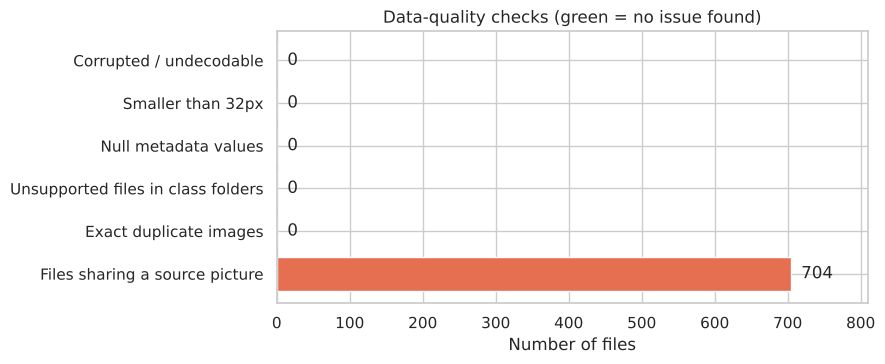

In [11]:
# Visualizing the missing values
# A null-value heatmap of a fully populated table is a blank rectangle, so the
# data-quality checks are summarised as counts instead.
class_folders = {(DATASET_DIR / relative_path).parent for relative_path in df_index["filepath"]}
quality_summary = pd.Series({
    "Corrupted / undecodable": len(invalid_files) - too_small_count,
    f"Smaller than {MIN_IMAGE_SIDE}px": too_small_count,
    "Null metadata values": int(metadata_nulls.sum()),
    "Unsupported files in class folders": sum(p.parent in class_folders for p in unsupported_files),
    "Exact duplicate images": exact_duplicate_count,
    "Files sharing a source picture": shared_source_images,
})

fig, ax = plt.subplots(figsize=(9, 3.8))
colors = ["#2a9d8f" if value == 0 else "#e76f51" for value in quality_summary]
ax.barh(quality_summary.index, quality_summary.values, color=colors)
for position, value in enumerate(quality_summary.values):
    ax.text(value, position, f"  {value:,}", va="center")
ax.invert_yaxis()
ax.set_xlabel("Number of files")
ax.set_title("Data-quality checks (green = no issue found)")
ax.set_xlim(0, max(quality_summary.max() * 1.15, 1))
finish_figure(fig, "00_data_quality_checks")

### What did you know about your dataset?

In [12]:
size_counts = df_raw.loc[valid_mask, ["width", "height"]].value_counts()
mode_counts = df_raw.loc[valid_mask, "mode"].value_counts()
grayscale_share = float((df_raw.loc[valid_mask, "max_channel_diff"] <= 8).mean())
class_counts_raw = df_raw["label"].value_counts().reindex(class_names)

show_md(f"""
**Computed from the files on disk:**

* **{len(df_raw):,} images** in **{NUM_CLASSES} classes**: {', '.join(f'`{c}` ({n:,})' for c, n in class_counts_raw.items())}.
* Supplied folders: {', '.join(f'`{s}` ({n:,})' for s, n in df_raw['original_split'].value_counts().items())}.
* File format(s): {', '.join(sorted(df_raw['extension'].unique()))}. Distinct image resolutions: **{len(size_counts)}** \
(most common: {size_counts.index[0][0]} x {size_counts.index[0][1]} px, {size_counts.iloc[0] / valid_mask.sum():.1%} of images).
* Colour mode(s): {', '.join(f'{m} ({n:,})' for m, n in mode_counts.items())}. \
**{grayscale_share:.1%}** of images are grayscale pictures stored with identical colour channels.
* Corrupted or undecodable files: **{len(invalid_files)}**. Null metadata values: **{int(metadata_nulls.sum())}**. \
Exact duplicate images: **{exact_duplicate_count}**.
* **{int((source_sizes > 1).sum()):,} source pictures appear in more than one file** - investigated in Data Wrangling.
* Largest class / smallest class ratio: **{class_counts_raw.max() / class_counts_raw.min():.2f}**.
""")


**Computed from the files on disk:**

* **2,443 images** in **4 classes**: `glioma` (805), `meningioma` (545), `no_tumor` (483), `pituitary` (610).
* Supplied folders: `train` (1,695), `valid` (502), `test` (246).
* File format(s): .jpg. Distinct image resolutions: **1** (most common: 640 x 640 px, 100.0% of images).
* Colour mode(s): RGB (2,443). **99.7%** of images are grayscale pictures stored with identical colour channels.
* Corrupted or undecodable files: **0**. Null metadata values: **0**. Exact duplicate images: **0**.
* **352 source pictures appear in more than one file** - investigated in Data Wrangling.
* Largest class / smallest class ratio: **1.67**.


**What this means.** The dataset is technically clean: the files decode, they share one resolution and one colour mode, and there are no exact duplicates. Because the images are grayscale content in an RGB container, colour carries no information and colour augmentation would be pointless. Two points need attention before modelling: the classes are moderately imbalanced, and a group of source pictures exists as more than one file, which can leak information between the training and evaluation sets.

## ***2. Understanding Your Variables***

In [13]:
# Dataset Columns
print(list(df_raw.columns))

['filepath', 'filename', 'label', 'original_split', 'source_id', 'extension', 'file_kb', 'is_valid', 'error', 'width', 'height', 'mode', 'channels', 'aspect_ratio', 'max_channel_diff', 'brightness', 'contrast', 'foreground_frac', 'pixel_md5']


In [14]:
# Dataset Describe
df_raw.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
file_kb,2443.0,31.166,9.092,16.444,24.049,30.010,36.708,121.682
width,2443.0,640.000,0.000,640.000,640.000,640.000,640.000,640.000
height,2443.0,640.000,0.000,640.000,640.000,640.000,640.000,640.000
channels,2443.0,3.000,0.000,3.000,3.000,3.000,3.000,3.000
aspect_ratio,2443.0,1.000,0.000,1.000,1.000,1.000,1.000,1.000
max_channel_diff,2443.0,0.125,2.765,0.000,0.000,0.000,0.000,90.000
brightness,2443.0,0.172,0.073,0.038,0.116,0.157,0.208,0.540
contrast,2443.0,0.173,0.045,0.087,0.145,0.163,0.188,0.360
foreground_frac,2443.0,0.506,0.150,0.138,0.390,0.475,0.621,1.000


### Variables Description

**Dataset / image metadata description.** The model's real inputs are pixel tensors. The table built above describes each image with the following variables.

| Variable | Type | Meaning |
|---|---|---|
| `filepath`, `filename` | text | Location of the image relative to the dataset folder |
| `label` | categorical | **Target.** Class folder name (tumor type or no tumor) |
| `original_split` | categorical | Split folder the file was supplied in (train / valid / test) |
| `source_id` | categorical | Source picture the file was derived from (class + original file name) |
| `extension` | categorical | File format |
| `file_kb` | numeric | Compressed file size in KB - a rough proxy for image detail |
| `width`, `height` | numeric | Image dimensions in pixels |
| `aspect_ratio` | numeric | Width divided by height |
| `mode`, `channels` | categorical / numeric | Colour mode and number of colour channels |
| `max_channel_diff` | numeric | Largest difference between colour channels (0 = true grayscale) |
| `brightness` | numeric | Mean pixel intensity on a 0-1 scale |
| `contrast` | numeric | Standard deviation of pixel intensity on a 0-1 scale |
| `foreground_frac` | numeric | Share of pixels brighter than the background threshold - how much of the frame the head fills |
| `pixel_md5` | text | Hash of the pixel content, used to detect exact duplicates |
| `is_valid`, `error` | boolean / text | Whether the file decoded correctly, and the reason if it did not |

### Check Unique Values for each variable.

In [15]:
# Check Unique Values for each variable.
unique_summary = pd.DataFrame({
    "unique_values": df_raw.nunique(),
    "examples": [", ".join(map(str, df_raw[column].dropna().unique()[:4])) for column in df_raw.columns],
})
unique_summary["examples"] = unique_summary["examples"].str.slice(0, 70)
unique_summary

,unique_values,examples
filepath,2443,test/glioma/Tr-gl_0016_jpg.rf.99746694ea97fe0b...
filename,2443,Tr-gl_0016_jpg.rf.99746694ea97fe0b73108832b462...
label,4,"glioma, meningioma, no_tumor, pituitary"
original_split,3,"test, train, valid"
source_id,2091,"glioma/Tr-gl_0016_jpg, glioma/Tr-gl_0018_jpg, ..."
extension,1,.jpg
file_kb,2340,"28.125, 26.443359375, 31.201171875, 31.427734375"
is_valid,1,True
error,0,
width,1,640


## 3. ***Data Wrangling***

### Data Wrangling Code

In [16]:
# Write your code to make your dataset analysis ready.

# Step 1 - keep only decodable images and drop exact pixel duplicates.
# Invalid files are excluded (not repaired) because a partially decoded medical
# image could contain misleading content; the decision is logged below.
df = df_raw[df_raw["is_valid"]].copy()
removed_invalid = len(df_raw) - len(df)
before_dedup = len(df)
df = df.drop_duplicates(subset="pixel_md5", keep="first").reset_index(drop=True)
removed_duplicates = before_dedup - len(df)

# Step 2 - encode the target and add analysis helpers.
class_to_index = {name: index for index, name in enumerate(class_names)}
df["label_index"] = df["label"].map(class_to_index)
df["display_label"] = df["label"].str.replace("_", " ").str.title()
DISPLAY_NAMES = [name.replace("_", " ").title() for name in class_names]
PALETTE = dict(zip(DISPLAY_NAMES, sns.color_palette("colorblind", NUM_CLASSES)))

logger.info("Removed %d invalid and %d exact-duplicate images; %d remain.",
            removed_invalid, removed_duplicates, len(df))

11:10:17 | INFO | Removed 0 invalid and 0 exact-duplicate images; 2443 remain.


In [17]:
# Step 3 - are files that share a source picture really the same picture?
# For each source with several files, compare the first file with the others:
# directly, and after mirroring one of them left-to-right.
def hamming(bits_a: np.ndarray, bits_b: np.ndarray) -> int:
    return int(np.count_nonzero(bits_a != bits_b))

pair_rows = []
for source_id, group in df.groupby("source_id"):
    if len(group) < 2:
        continue
    first = group.iloc[0]
    for _, other in group.iloc[1:].iterrows():
        pair_rows.append({
            "source_id": source_id,
            "split_a": first["original_split"], "split_b": other["original_split"],
            "direct_distance": hamming(fingerprints[first["filepath"]]["dhash"],
                                       fingerprints[other["filepath"]]["dhash"]),
            "mirrored_distance": hamming(fingerprints[first["filepath"]]["dhash"],
                                         fingerprints[other["filepath"]]["dhash_mirrored"]),
        })
pairs = pd.DataFrame(pair_rows, columns=["source_id", "split_a", "split_b",
                                         "direct_distance", "mirrored_distance"])

# Reference: how different are two unrelated images?
rng = np.random.default_rng(SEED)
random_idx = rng.integers(0, len(df), size=(300, 2))
unrelated = [hamming(fingerprints[df.at[a, "filepath"]]["dhash"], fingerprints[df.at[b, "filepath"]]["dhash"])
             for a, b in random_idx if a != b]

# A pair is "related" if either comparison matches; it is a mirrored copy when
# the flipped comparison is the closer of the two.
related = pairs[["direct_distance", "mirrored_distance"]].min(axis=1) <= MIRROR_HAMMING_MAX
pairs["mirrored_copy"] = related & (pairs["mirrored_distance"] < pairs["direct_distance"])
pairs["identical_view"] = related & ~pairs["mirrored_copy"]
pairs["crosses_split"] = pairs["split_a"] != pairs["split_b"]
pairs["split_pair"] = [" + ".join(sorted(p)) for p in zip(pairs["split_a"], pairs["split_b"])]

leaky_pairs = int(pairs["crosses_split"].sum())
touches_test = int((pairs["crosses_split"] & ((pairs["split_a"] == "test") | (pairs["split_b"] == "test"))).sum())
print(f"File pairs that share a source picture : {len(pairs):,}")
print(f"  - confirmed mirrored copies          : {int(pairs['mirrored_copy'].sum()):,}")
print(f"  - same view, not mirrored            : {int(pairs['identical_view'].sum()):,}")
print(f"  - same file name but different picture: {int((~related).sum()):,}")
print(f"  - median differing bits when mirrored : {pairs['mirrored_distance'].median() if len(pairs) else float('nan'):.0f} of 256")
print(f"Reference, unrelated image pairs        : median {np.median(unrelated):.0f} of 256 bits differ")
print(f"Pairs split across supplied folders     : {leaky_pairs:,}  "
      f"(of which {touches_test:,} put one copy in 'test')")

File pairs that share a source picture : 352
  - confirmed mirrored copies          : 352
  - same view, not mirrored            : 0
  - same file name but different picture: 0
  - median differing bits when mirrored : 0 of 256
Reference, unrelated image pairs        : median 98 of 256 bits differ
Pairs split across supplied folders     : 164  (of which 67 put one copy in 'test')


In [18]:
# Step 4 - load every image once, resized with the SAME function the app uses.
# uint8 storage keeps memory low; scaling to [0, 1] happens in the input pipeline.
def load_pixel_cache(frame: pd.DataFrame) -> np.ndarray:
    cache = np.empty((len(frame), *IMG_SIZE, 3), dtype=np.uint8)
    for position, relative_path in enumerate(frame["filepath"]):
        try:
            cache[position] = load_and_resize(DATASET_DIR / relative_path, IMG_SIZE)
        except InvalidImageError as exc:
            # The audit already removed unreadable files, so reaching this line
            # means the dataset changed on disk while the notebook was running.
            raise RuntimeError(f"Image became unreadable after the audit: {relative_path}") from exc
    return cache

X_all = load_pixel_cache(df)
y_all = df["label_index"].to_numpy()
print(f"Pixel cache: shape {X_all.shape}, dtype {X_all.dtype}, {X_all.nbytes / 1e6:.0f} MB in memory")

Pixel cache: shape (2443, 224, 224, 3), dtype uint8, 368 MB in memory


### What all manipulations have you done and insights you found?

In [19]:
show_md(f"""
**Manipulations**

1. Removed **{removed_invalid}** invalid files and **{removed_duplicates}** exact duplicates, leaving **{len(df):,}** images.
2. Encoded the target: {', '.join(f'`{name}` -> {index}' for name, index in class_to_index.items())}.
3. Derived a `source_id` for every file from its name and compared files that share one.
4. Loaded all images into memory at {IMG_SIZE[0]} x {IMG_SIZE[1]} px with the shared preprocessing function.

**Insights**

* **{len(pairs):,} pairs of files share a source picture.** {int(pairs['mirrored_copy'].sum()):,} of them are \
**left-right mirrored copies** of each other; {int(pairs['identical_view'].sum()):,} show the same view without mirroring. \
(Mirrored pairs differ in a median of {pairs['mirrored_distance'].median() if len(pairs) else float('nan'):.0f} of 256 hash bits once one is flipped back; \
unrelated images differ in about {np.median(unrelated):.0f}.)
* **{leaky_pairs:,} of those pairs are split across the supplied train / valid / test folders**, and \
{touches_test:,} of them place one copy in the test folder. Evaluating on the supplied split would therefore test the \
model on mirror images of pictures it had already seen, which inflates every metric.
* **Decision:** the supplied split is not used. Section 6.8 builds a new stratified split in which all files of one \
source picture stay in the same subset.
""")


**Manipulations**

1. Removed **0** invalid files and **0** exact duplicates, leaving **2,443** images.
2. Encoded the target: `glioma` -> 0, `meningioma` -> 1, `no_tumor` -> 2, `pituitary` -> 3.
3. Derived a `source_id` for every file from its name and compared files that share one.
4. Loaded all images into memory at 224 x 224 px with the shared preprocessing function.

**Insights**

* **352 pairs of files share a source picture.** 352 of them are **left-right mirrored copies** of each other; 0 show the same view without mirroring. (Mirrored pairs differ in a median of 0 of 256 hash bits once one is flipped back; unrelated images differ in about 98.)
* **164 of those pairs are split across the supplied train / valid / test folders**, and 67 of them place one copy in the test folder. Evaluating on the supplied split would therefore test the model on mirror images of pictures it had already seen, which inflates every metric.
* **Decision:** the supplied split is not used. Section 6.8 builds a new stratified split in which all files of one source picture stay in the same subset.


The dataset's mirrored copies also tell us something about augmentation: the dataset author already treated a left-right flip as a label-preserving transformation, so horizontal flipping is consistent with how this data was built.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

The charts follow the **UBM** rule. **U**nivariate: charts 1-5. **B**ivariate: charts 6-8, 11, 12. **M**ultivariate: charts 9, 10, 13, 14, 15. Model-related charts (augmentation, training curves, confusion matrices, comparisons, Grad-CAM) appear in sections 6 and 7.

For each chart the three template questions are answered. Because this is a medical-imaging project, "business impact" is read as *impact on the project and on a potential clinical workflow*.

#### Chart - 1 : Class distribution (Univariate)

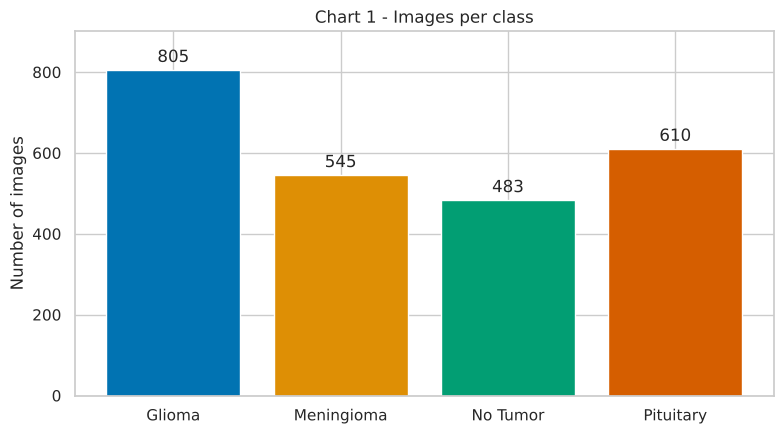

Largest class: **Glioma** (805). Smallest class: **No Tumor** (483). Imbalance ratio: **1.67 : 1**.

In [20]:
# Chart - 1 visualization code
class_counts = df["display_label"].value_counts().reindex(DISPLAY_NAMES)
imbalance_ratio = class_counts.max() / class_counts.min()

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(class_counts.index, class_counts.values, color=[PALETTE[c] for c in class_counts.index])
ax.bar_label(bars, labels=[f"{v:,}" for v in class_counts.values], padding=3)
ax.set_ylabel("Number of images")
ax.set_title("Chart 1 - Images per class")
ax.set_ylim(0, class_counts.max() * 1.12)
finish_figure(fig, "01_class_distribution")
show_md(f"Largest class: **{class_counts.idxmax()}** ({class_counts.max():,}). Smallest class: "
        f"**{class_counts.idxmin()}** ({class_counts.min():,}). Imbalance ratio: **{imbalance_ratio:.2f} : 1**.")

##### 1. Why did you pick the specific chart?

A bar chart is the most direct way to compare a count across a few categories. Class balance is the first thing to check in a classification problem because it decides which metrics can be trusted and whether the loss needs re-weighting.

##### 2. What is/are the insight(s) found from the chart?

The classes are not equal in size. Glioma is the largest class and No Tumor the smallest, with the largest class about 1.7 times the size of the smallest (exact figures are printed under the chart). This is a moderate imbalance, not a severe one.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** knowing the imbalance early lets the project use macro-averaged metrics and class weights, so the smaller classes are not ignored. **Risk:** a model trained without correction could favour the largest class, and plain accuracy would hide that. The class mix here is also not the mix a hospital sees - in real screening most scans show no tumor - so performance on this dataset does not translate directly into clinical predictive value.

#### Chart - 2 : Class share (Univariate)

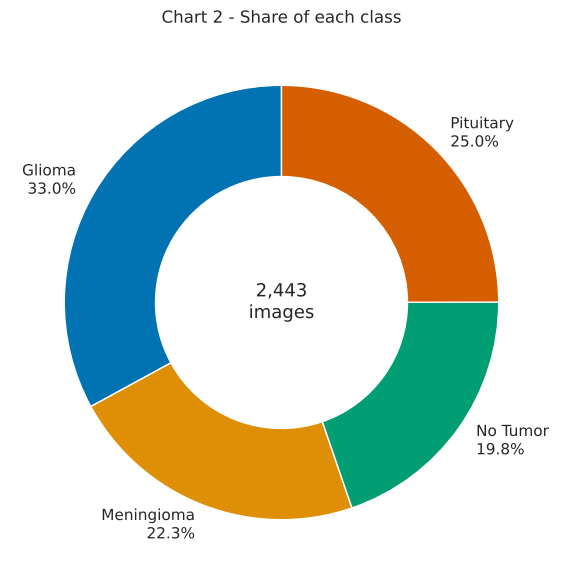

A model that always predicts the largest class would reach **33.0%** accuracy. Tumor classes together make up **80.2%** of the images.

In [21]:
# Chart - 2 visualization code
class_share = class_counts / class_counts.sum()

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(class_share.values, labels=[f"{name}\n{share:.1%}" for name, share in class_share.items()],
       colors=[PALETTE[c] for c in class_share.index], startangle=90,
       wedgeprops={"width": 0.42, "edgecolor": "white"})
ax.text(0, 0, f"{class_counts.sum():,}\nimages", ha="center", va="center", fontsize=13)
ax.set_title("Chart 2 - Share of each class")
finish_figure(fig, "02_class_share")
tumor_share = 1 - class_share.get("No Tumor", 0.0)
show_md(f"A model that always predicts the largest class would reach **{class_share.max():.1%}** accuracy. "
        f"Tumor classes together make up **{tumor_share:.1%}** of the images.")

##### 1. Why did you pick the specific chart?

A donut chart shows parts of a whole. With only four categories it is easy to read, and it answers a different question from Chart 1: not "how many?" but "what proportion?", which sets the baseline any model must beat.

##### 2. What is/are the insight(s) found from the chart?

No class dominates: the largest class holds about one third of the data, so a trivial majority-class predictor would be right only about one time in three. Roughly four in five images show a tumor.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the majority-class baseline gives an honest reference point for judging model accuracy. **Risk:** tumor images are heavily over-represented compared with a real screening population. A model tuned on this mix may be more willing to predict "tumor" than is appropriate where tumors are rare, which would increase false alarms.

#### Chart - 3 : Representative MRI slices per class (Univariate)

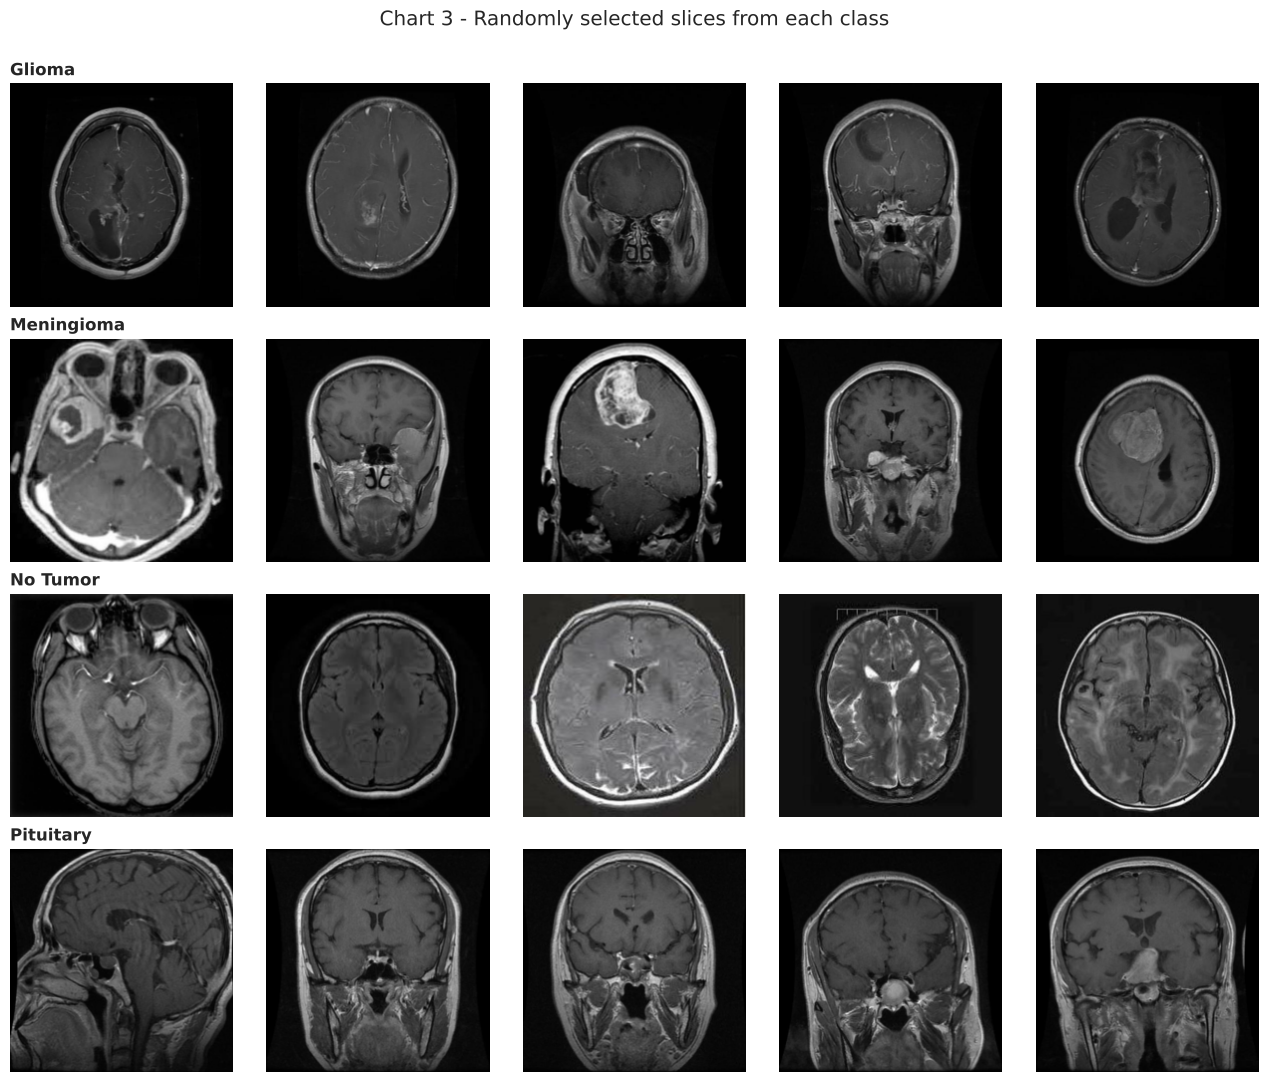

In [22]:
# Chart - 3 visualization code
SAMPLES_PER_CLASS = 5
fig, axes = plt.subplots(NUM_CLASSES, SAMPLES_PER_CLASS, figsize=(2.6 * SAMPLES_PER_CLASS, 2.7 * NUM_CLASSES))
for row_index, (class_name, display_name) in enumerate(zip(class_names, DISPLAY_NAMES)):
    class_rows = df.index[df["label"] == class_name].to_numpy()
    chosen = np.random.default_rng(SEED + row_index).choice(class_rows, SAMPLES_PER_CLASS, replace=False)
    for column_index, image_index in enumerate(chosen):
        axis = axes[row_index, column_index]
        axis.imshow(X_all[image_index])
        axis.axis("off")
        if column_index == 0:
            axis.set_title(display_name, loc="left", fontsize=12, fontweight="bold")
fig.suptitle("Chart 3 - Randomly selected slices from each class", y=1.0)
finish_figure(fig, "03_sample_images")

##### 1. Why did you pick the specific chart?

Statistics cannot replace looking at the images. A grid of random samples per class shows what the model will actually receive: the viewing planes, the framing, the image quality and how visible the differences between classes are.

##### 2. What is/are the insight(s) found from the chart?

The dataset mixes viewing planes (axial, coronal and sagittal slices) and different contrast settings within every class. The images differ in how much of the frame the head fills and in overall brightness. The differences between tumor types are subtle and local, while the differences in framing and brightness are large and global.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** variety in planes and contrast means the model is not tied to one acquisition protocol, which is closer to real use. **Risk:** the mixture makes the task harder for a small dataset, and the visible global differences between classes are a warning that a model could separate classes by appearance of the scan rather than by the lesion. Charts 6-10 measure this.

#### Chart - 4 : File size distribution (Univariate)

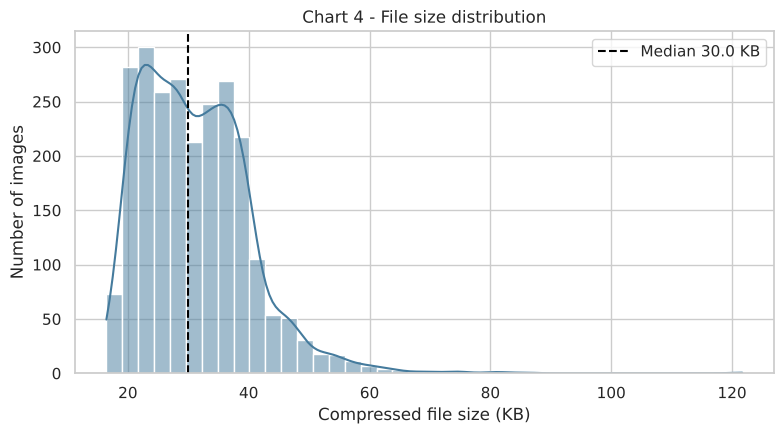

Image resolutions present: **640 x 640px (2,443)**. Aspect ratios present: **1.00**. File size ranges from 16.4 to 121.7 KB (skewness 1.37).

In [23]:
# Chart - 4 visualization code
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(df["file_kb"], bins=40, kde=True, color="#457b9d", ax=ax)
ax.axvline(df["file_kb"].median(), color="black", linestyle="--", label=f"Median {df['file_kb'].median():.1f} KB")
ax.set_xlabel("Compressed file size (KB)")
ax.set_ylabel("Number of images")
ax.set_title("Chart 4 - File size distribution")
ax.legend()
finish_figure(fig, "04_file_size")
resolution_text = ", ".join(f"{w} x {h}px ({n:,})" for (w, h), n in df[["width", "height"]].value_counts().items())
show_md(f"Image resolutions present: **{resolution_text}**. Aspect ratios present: "
        f"**{', '.join(f'{ratio:.2f}' for ratio in sorted(df['aspect_ratio'].round(3).unique()))}**. File size ranges from "
        f"{df['file_kb'].min():.1f} to {df['file_kb'].max():.1f} KB (skewness {df['file_kb'].skew():.2f}).")

##### 1. Why did you pick the specific chart?

The usual width, height and aspect-ratio histograms would each be a single bar here, because every image has the same resolution (shown under the chart). They would carry no information, so they are reported as one line of text. File size is the size-related variable that does vary: at a fixed resolution and format, a larger JPEG means more detail or more non-black area. A histogram with a density curve shows its shape.

##### 2. What is/are the insight(s) found from the chart?

All images share one resolution and a square aspect ratio, so resizing to the model's input size does not distort anatomy. File sizes are right-skewed: most images are small, with a tail of larger files that contain more detail or less black background.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** a uniform resolution removes a whole class of preprocessing problems and means no image is stretched. **Risk:** the uniformity is a product of how the dataset was exported, not of real scanners. Images uploaded to the deployed app will arrive in many sizes and aspect ratios, and non-square uploads will be distorted by resizing. This is listed as a limitation.

#### Chart - 5 : Pixel intensity distribution (Univariate)

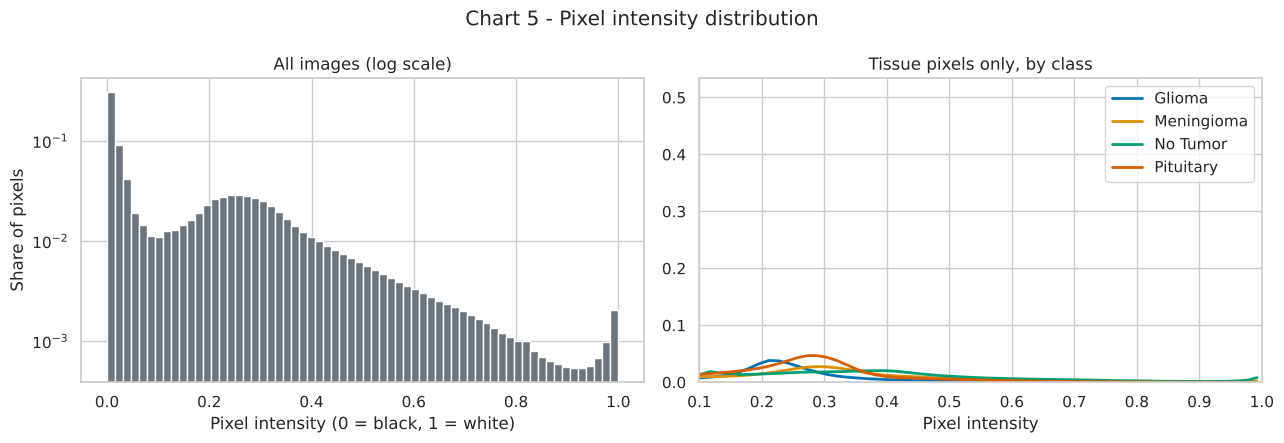

**48.9%** of all pixels are near-black background (intensity <= 0.1). Only **0.54%** of pixels are near-white (>= 0.9).

In [24]:
# Chart - 5 visualization code
histograms = np.stack([fingerprints[path]["histogram"] for path in df["filepath"]])
bin_centers = (np.arange(64) + 0.5) / 64
overall_density = histograms.sum(axis=0) / histograms.sum()
dark_share = overall_density[bin_centers <= FOREGROUND_THRESHOLD].sum()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(bin_centers, overall_density, width=1 / 64, color="#6c757d")
axes[0].set_yscale("log")
axes[0].set_title("All images (log scale)")
axes[0].set_xlabel("Pixel intensity (0 = black, 1 = white)")
axes[0].set_ylabel("Share of pixels")
for class_name, display_name in zip(class_names, DISPLAY_NAMES):
    class_hist = histograms[(df["label"] == class_name).to_numpy()].sum(axis=0)
    axes[1].plot(bin_centers, class_hist / class_hist.sum(), label=display_name, color=PALETTE[display_name], linewidth=2)
axes[1].set_xlim(FOREGROUND_THRESHOLD, 1)
axes[1].set_ylim(0, None)
axes[1].set_title("Tissue pixels only, by class")
axes[1].set_xlabel("Pixel intensity")
axes[1].legend()
fig.suptitle("Chart 5 - Pixel intensity distribution")
finish_figure(fig, "05_pixel_intensity")
show_md(f"**{dark_share:.1%}** of all pixels are near-black background (intensity <= {FOREGROUND_THRESHOLD}). "
        f"Only **{overall_density[bin_centers >= 0.9].sum():.2%}** of pixels are near-white (>= 0.9).")

##### 1. Why did you pick the specific chart?

A histogram of pixel values is the image equivalent of describing a numeric feature. It shows the range the network will see, whether values are concentrated at an extreme, and whether scaling is needed. The left panel uses a log scale because background pixels would otherwise hide everything else; the right panel removes the background to compare tissue intensities between classes.

##### 2. What is/are the insight(s) found from the chart?

About half of all pixels are black background, and very few are near-white, so the images are dark overall and use the lower part of the intensity range. The tissue-intensity curves are not the same for all classes: the classes differ in how bright their tissue pixels typically are.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** values span the full 0-255 range without clipping, so scaling to 0-1 is enough and no contrast stretching is needed. Large black borders mean small shifts and zooms will not push anatomy out of the frame, which supports mild geometric augmentation. **Risk:** class-specific intensity profiles suggest the classes may come from different scanners or protocols. A model can exploit that, and it would not hold in a hospital with different equipment.

#### Chart - 6 : Brightness by class (Bivariate, numerical - categorical)

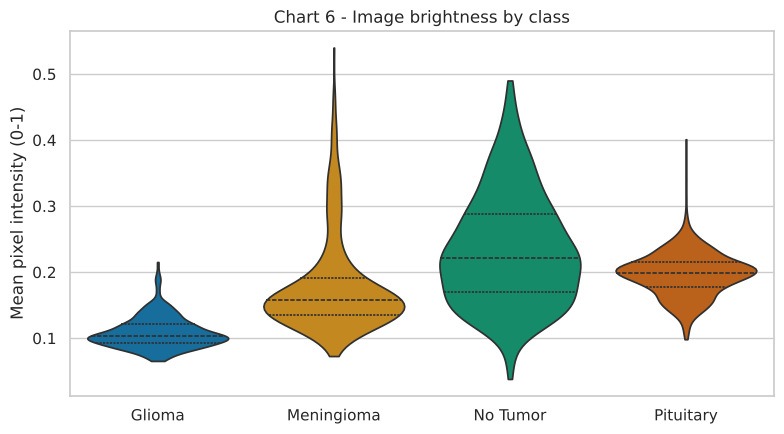

Median brightness - Glioma: **0.104**, Meningioma: **0.157**, No Tumor: **0.221**, Pituitary: **0.199**. Brightest / darkest class ratio: **2.13x**.

In [25]:
# Chart - 6 visualization code
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.violinplot(data=df, x="display_label", y="brightness", hue="display_label", order=DISPLAY_NAMES,
               palette=PALETTE, inner="quartile", cut=0, legend=False, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("Mean pixel intensity (0-1)")
ax.set_title("Chart 6 - Image brightness by class")
finish_figure(fig, "06_brightness_by_class")
brightness_medians = df.groupby("display_label")["brightness"].median().reindex(DISPLAY_NAMES)
show_md("Median brightness - " + ", ".join(f"{name}: **{value:.3f}**" for name, value in brightness_medians.items())
        + f". Brightest / darkest class ratio: **{brightness_medians.max() / brightness_medians.min():.2f}x**.")

##### 1. Why did you pick the specific chart?

A violin plot compares the full distribution of a numeric variable across categories - its centre, spread and shape - not just an average. It is the right tool to ask whether a simple global property of the image is related to the label.

##### 2. What is/are the insight(s) found from the chart?

Brightness is clearly related to class. Glioma images are the darkest and No Tumor images the brightest, with the median of the brightest class roughly twice that of the darkest. The distributions overlap, but far less than they would if brightness were unrelated to the label.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**This is mainly a risk.** A tumor does not make a whole image darker, so this difference almost certainly reflects where and how the images of each class were acquired. A network can use it as a shortcut and reach a high score without looking at the lesion, and that score would not carry over to another hospital. **Mitigation in this project:** brightness and contrast augmentation weaken the shortcut, and Grad-CAM is used to check where the model looks. The limitation is reported, not hidden.

#### Chart - 7 : Contrast by class (Bivariate, numerical - categorical)

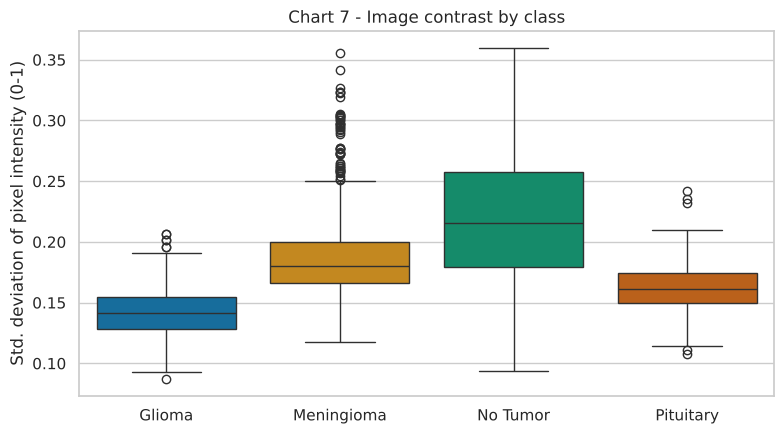

Median contrast - Glioma: **0.141**, Meningioma: **0.180**, No Tumor: **0.215**, Pituitary: **0.161**.

In [26]:
# Chart - 7 visualization code
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=df, x="display_label", y="contrast", hue="display_label", order=DISPLAY_NAMES,
            palette=PALETTE, legend=False, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("Std. deviation of pixel intensity (0-1)")
ax.set_title("Chart 7 - Image contrast by class")
finish_figure(fig, "07_contrast_by_class")
contrast_medians = df.groupby("display_label")["contrast"].median().reindex(DISPLAY_NAMES)
show_md("Median contrast - " + ", ".join(f"{name}: **{value:.3f}**" for name, value in contrast_medians.items()) + ".")

##### 1. Why did you pick the specific chart?

A box plot summarises median, quartiles and outliers per category in a compact form, which makes it easy to compare classes and to see how many unusual images each class contains.

##### 2. What is/are the insight(s) found from the chart?

Contrast also differs by class. No Tumor images have the highest median contrast and the widest spread; the three tumor classes are lower and closer to one another. Every class has outliers with unusually high contrast.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the outliers are real scans with different contrast settings, so keeping them exposes the model to the variety it would meet in practice. **Risk:** as with brightness, contrast separates No Tumor from the tumor classes for reasons unrelated to pathology, so part of the model's ability to recognise healthy scans may come from scan style.

#### Chart - 8 : Brain-area coverage by class (Bivariate, numerical - categorical)

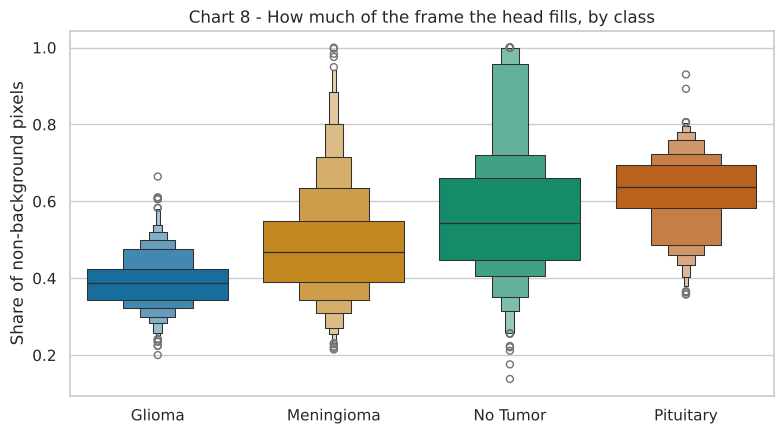

Median coverage - Glioma: **38.7%**, Meningioma: **46.7%**, No Tumor: **54.3%**, Pituitary: **63.8%**.

In [27]:
# Chart - 8 visualization code
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxenplot(data=df, x="display_label", y="foreground_frac", hue="display_label", order=DISPLAY_NAMES,
              palette=PALETTE, legend=False, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("Share of non-background pixels")
ax.set_title("Chart 8 - How much of the frame the head fills, by class")
finish_figure(fig, "08_foreground_by_class")
foreground_medians = df.groupby("display_label")["foreground_frac"].median().reindex(DISPLAY_NAMES)
show_md("Median coverage - " + ", ".join(f"{name}: **{value:.1%}**" for name, value in foreground_medians.items()) + ".")

##### 1. Why did you pick the specific chart?

The share of non-background pixels measures framing: how tightly the scan is cropped around the head. A letter-value (boxen) plot shows more of the tails than a box plot, which matters because coverage has long tails.

##### 2. What is/are the insight(s) found from the chart?

Framing differs by class. Glioma images have the least tissue in frame and Pituitary images the most. The No Tumor class has the widest spread, from tightly cropped images to ones with a large black border.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** it guides augmentation - random zoom and translation vary the framing during training so the model cannot rely on it as much. **Risk:** framing is a property of the image export, not of the patient. If the deployed app receives scans cropped differently from the training data, predictions may shift for reasons that have nothing to do with anatomy.

#### Chart - 9 : Mean image per class (Multivariate)

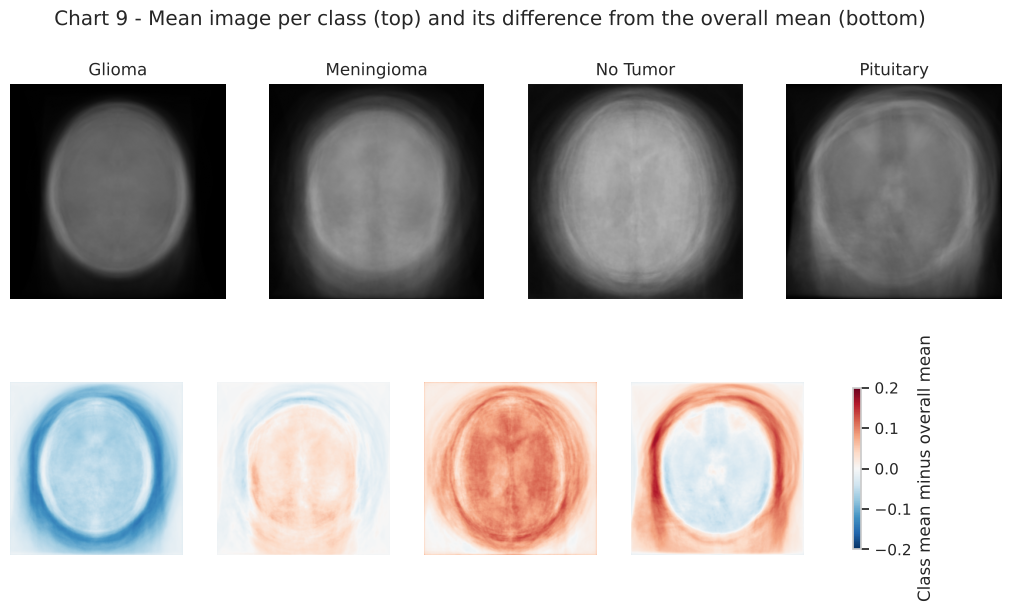

In [28]:
# Chart - 9 visualization code
gray_all = X_all.mean(axis=-1, dtype=np.float32) / 255.0
overall_mean_image = gray_all.mean(axis=0)

fig, axes = plt.subplots(2, NUM_CLASSES, figsize=(3.2 * NUM_CLASSES, 6.6))
for column_index, (class_name, display_name) in enumerate(zip(class_names, DISPLAY_NAMES)):
    class_mean = gray_all[(df["label"] == class_name).to_numpy()].mean(axis=0)
    axes[0, column_index].imshow(class_mean, cmap="gray", vmin=0, vmax=0.6)
    axes[0, column_index].set_title(display_name)
    difference = axes[1, column_index].imshow(class_mean - overall_mean_image, cmap="RdBu_r", vmin=-0.2, vmax=0.2)
    axes[0, column_index].axis("off")
    axes[1, column_index].axis("off")
fig.colorbar(difference, ax=axes[1, :], shrink=0.7, label="Class mean minus overall mean")
fig.suptitle("Chart 9 - Mean image per class (top) and its difference from the overall mean (bottom)")
fig.savefig(FIGURES_DIR / "09_mean_images.png", dpi=120, bbox_inches="tight")
plt.show()

##### 1. Why did you pick the specific chart?

Averaging all images of a class pixel by pixel uses every pixel position at once, so it is a multivariate view. It shows the typical layout of a class, and the difference map shows where each class is systematically brighter (red) or darker (blue) than the dataset average.

##### 2. What is/are the insight(s) found from the chart?

The mean images are blurred head shapes, as expected when several viewing planes are mixed. The difference maps are not confined to a small lesion-sized region: whole areas of the frame, including the border, differ between classes. That confirms the earlier charts - classes differ in overall framing and brightness, not only in local pathology.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the chart gives a concrete picture of the dataset bias, which makes the limitation easy to explain to a clinical or technical reviewer. **Risk:** differences near the image border cannot be anatomical. Any model trained on this data should be checked with an explainability method before its accuracy is trusted, which is done with Grad-CAM in section 7.

#### Chart - 10 : Brightness vs contrast by class (Multivariate)

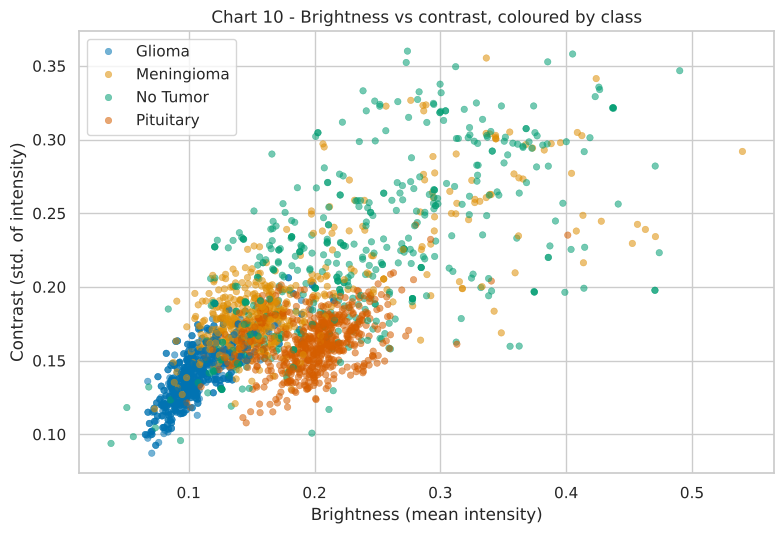

Pearson correlation between brightness and contrast: **0.74**.

In [29]:
# Chart - 10 visualization code
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.scatterplot(data=df, x="brightness", y="contrast", hue="display_label", hue_order=DISPLAY_NAMES,
                palette=PALETTE, alpha=0.55, s=22, edgecolor=None, ax=ax)
ax.set_xlabel("Brightness (mean intensity)")
ax.set_ylabel("Contrast (std. of intensity)")
ax.set_title("Chart 10 - Brightness vs contrast, coloured by class")
ax.legend(title="")
finish_figure(fig, "10_brightness_vs_contrast")
show_md(f"Pearson correlation between brightness and contrast: **{df['brightness'].corr(df['contrast']):.2f}**.")

##### 1. Why did you pick the specific chart?

A scatter plot with colour for the class shows three variables together: two numeric features and the label. It answers whether the classes could be partly separated using just two global statistics.

##### 2. What is/are the insight(s) found from the chart?

Brightness and contrast rise together, and the classes occupy different regions of the plot: Glioma sits in the dark, low-contrast corner while No Tumor spreads towards the bright, high-contrast area. The clusters overlap, so these two numbers cannot classify the images on their own, but they carry real label information.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** it sets a sanity expectation - a deep model should do much better than two global statistics, and if it did not, it would be adding little. **Risk:** partial separability from global statistics means a high test score on this dataset is not, by itself, proof that the model has learned tumor appearance.

#### Chart - 11 : Class composition of the supplied split (Bivariate, categorical - categorical)

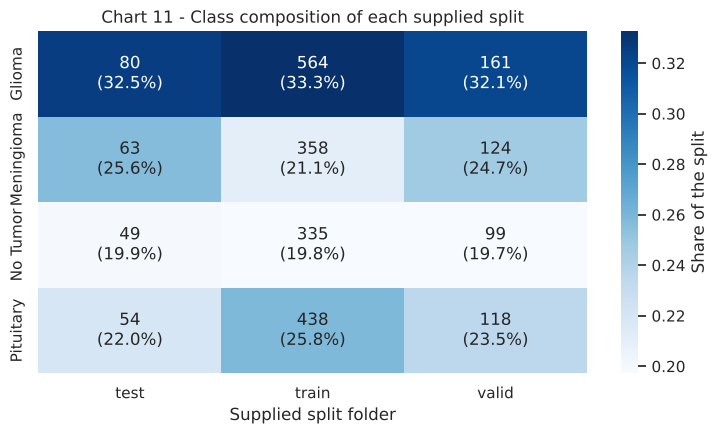

Supplied split sizes - test: **246** (10.1%), train: **1,695** (69.4%), valid: **502** (20.5%).

In [30]:
# Chart - 11 visualization code
split_counts = pd.crosstab(df["display_label"], df["original_split"]).reindex(DISPLAY_NAMES)
split_share = split_counts / split_counts.sum(axis=0)
annotations = split_counts.astype(str) + "\n(" + (split_share * 100).round(1).astype(str) + "%)"

fig, ax = plt.subplots(figsize=(7.5, 4.5))
sns.heatmap(split_share, annot=annotations, fmt="", cmap="Blues", cbar_kws={"label": "Share of the split"}, ax=ax)
ax.set_xlabel("Supplied split folder")
ax.set_ylabel("")
ax.set_title("Chart 11 - Class composition of each supplied split")
finish_figure(fig, "11_supplied_split_composition")
show_md("Supplied split sizes - " + ", ".join(f"{name}: **{count:,}** ({count / len(df):.1%})"
                                               for name, count in split_counts.sum(axis=0).items()) + ".")

##### 1. Why did you pick the specific chart?

A heatmap of a contingency table is the standard way to compare two categorical variables. Here it checks whether the dataset author's train, validation and test folders contain the classes in similar proportions.

##### 2. What is/are the insight(s) found from the chart?

The three supplied folders have similar class proportions, differing by only a few percentage points per class, so the supplied split is roughly stratified by class. The supplied split is approximately 69 % / 21 % / 10 %.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** class proportions are not a problem in the supplied split. **Risk:** balanced proportions say nothing about independence. A split can be perfectly stratified and still leak, which is what the next chart shows.

#### Chart - 12 : Mirrored copies across the supplied split (Bivariate, categorical - categorical)

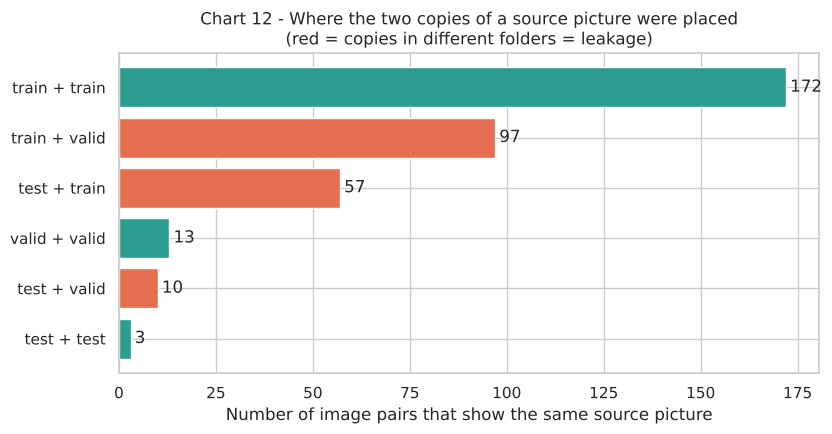

**164 of 352 pairs (46.6%)** are divided between folders. **67** pairs have one copy in the supplied test folder.

In [31]:
# Chart - 12 visualization code
if len(pairs):
    pair_counts = pairs.groupby(["split_pair", "crosses_split"]).size().reset_index(name="pairs").sort_values("pairs")
    fig, ax = plt.subplots(figsize=(8.5, 4.5))
    bar_colors = ["#e76f51" if crosses else "#2a9d8f" for crosses in pair_counts["crosses_split"]]
    bars = ax.barh(pair_counts["split_pair"], pair_counts["pairs"], color=bar_colors)
    ax.bar_label(bars, padding=3)
    ax.set_xlabel("Number of image pairs that show the same source picture")
    ax.set_title("Chart 12 - Where the two copies of a source picture were placed\n"
                 "(red = copies in different folders = leakage)")
    finish_figure(fig, "12_split_leakage")
    show_md(f"**{leaky_pairs:,} of {len(pairs):,} pairs ({leaky_pairs / len(pairs):.1%})** are divided between folders. "
            f"**{touches_test:,}** pairs have one copy in the supplied test folder.")
else:
    show_md("No files share a source picture in this dataset, so there is no pair-level leakage to chart.")

##### 1. Why did you pick the specific chart?

The question is categorical on both sides: for each pair of copies, which two folders hold them? A horizontal bar chart of the folder combinations, coloured by whether the pair crosses a boundary, makes the amount of leakage visible at a glance.

##### 2. What is/are the insight(s) found from the chart?

Nearly half of the mirrored pairs are divided between folders. Dozens of images in the supplied test folder have their mirror image in the training or validation folder. Only the pairs kept inside one folder (green) are harmless.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** this is the most important data finding of the project. Catching it prevents reporting an inflated test score, which in a medical setting could create false confidence in the model. **Negative if ignored:** a mirrored copy is almost the same image, so the model would be partly graded on memorised examples. The fix - a split that keeps the copies together - is applied in section 6.8.

#### Chart - 13 : PCA projection of raw pixels (Multivariate)

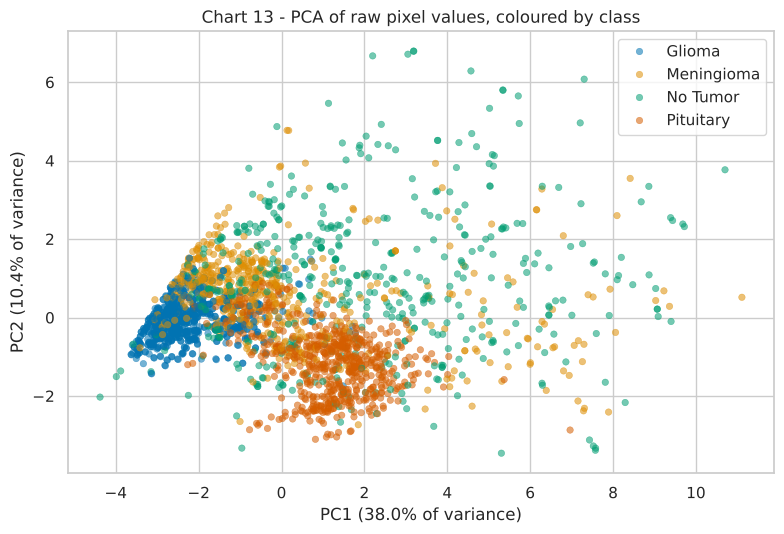

The first two components explain **48.5%** of pixel variance; the first ten explain **66.7%**.

In [32]:
# Chart - 13 visualization code
# Downsample to 32x32 grayscale so that PCA runs on 1,024 pixel features per image.
thumbnails = tf.image.resize(gray_all[..., np.newaxis], (32, 32), antialias=True).numpy().reshape(len(df), -1)
del gray_all  # the full-resolution grayscale copy is no longer needed
pca = PCA(n_components=10, random_state=SEED)
projection = pca.fit_transform(thumbnails - thumbnails.mean(axis=0))
pca_frame = pd.DataFrame({"PC1": projection[:, 0], "PC2": projection[:, 1], "Class": df["display_label"]})

fig, ax = plt.subplots(figsize=(8, 5.5))
sns.scatterplot(data=pca_frame, x="PC1", y="PC2", hue="Class", hue_order=DISPLAY_NAMES, palette=PALETTE,
                alpha=0.55, s=22, edgecolor=None, ax=ax)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} of variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} of variance)")
ax.set_title("Chart 13 - PCA of raw pixel values, coloured by class")
ax.legend(title="")
finish_figure(fig, "13_pca_projection")
show_md(f"The first two components explain **{pca.explained_variance_ratio_[:2].sum():.1%}** of pixel variance; "
        f"the first ten explain **{pca.explained_variance_ratio_.sum():.1%}**.")

##### 1. Why did you pick the specific chart?

PCA compresses the thousand pixel values of each thumbnail into the two directions of greatest variation. Plotting them shows whether the classes can be separated by a *linear* combination of raw pixels, which indicates how much a non-linear model such as a CNN is needed.

##### 2. What is/are the insight(s) found from the chart?

The classes form overlapping clouds, not clean clusters. There is some structure - classes lean towards different sides of the plot, in line with the brightness and framing differences - but no straight line separates them, and two components capture only part of the variance.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** it justifies the modelling choice. Raw pixels are not linearly separable, so a model that learns hierarchical, spatial features is appropriate, and a simple linear model on pixels would not be. **Risk:** the partial structure visible even in two components is again likely to be acquisition-related and not pathological.

#### Chart - 14 - Correlation Heatmap

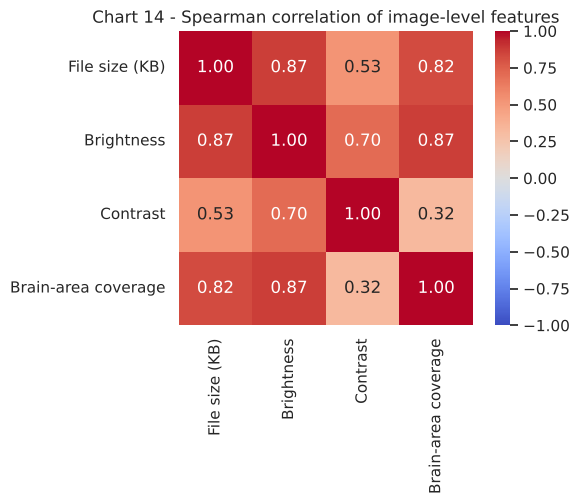

Strongest relationship: **File size (KB) - Brightness** (rho = 0.87). Weakest: **Contrast - Brain-area coverage** (rho = 0.32).

In [33]:
# Correlation Heatmap visualization code
FEATURE_COLUMNS = ["file_kb", "brightness", "contrast", "foreground_frac"]
FEATURE_LABELS = {"file_kb": "File size (KB)", "brightness": "Brightness", "contrast": "Contrast",
                  "foreground_frac": "Brain-area coverage"}
correlation = df[FEATURE_COLUMNS].rename(columns=FEATURE_LABELS).corr(method="spearman")

fig, ax = plt.subplots(figsize=(6.5, 5.2))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Chart 14 - Spearman correlation of image-level features")
finish_figure(fig, "14_correlation_heatmap")
upper = correlation.where(np.triu(np.ones(correlation.shape, dtype=bool), k=1)).stack()
show_md(f"Strongest relationship: **{upper.abs().idxmax()[0]} - {upper.abs().idxmax()[1]}** "
        f"(rho = {upper[upper.abs().idxmax()]:.2f}). Weakest: **{upper.abs().idxmin()[0]} - {upper.abs().idxmin()[1]}** "
        f"(rho = {upper[upper.abs().idxmin()]:.2f}).")

##### 1. Why did you pick the specific chart?

A correlation heatmap shows all pairwise relationships between numeric variables in one view. Width, height and aspect ratio are constants in this dataset and have no correlation to compute, so the heatmap uses the four image-level features that vary. Spearman correlation is used because the features are skewed.

##### 2. What is/are the insight(s) found from the chart?

The features are positively related. Brightness is strongly tied to brain-area coverage - an image is brighter mainly because more of it is tissue - and to file size. Contrast is the most independent of the four, particularly with respect to coverage.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** it shows that much of the brightness difference between classes is a framing effect, which points to zoom and translation augmentation as the relevant counter-measure. **Risk:** because the features move together, the class-related bias seen in charts 6-8 is one underlying difference in acquisition and export, not several small independent ones, and is therefore likely to be consistent enough for a model to exploit.

#### Chart - 15 - Pair Plot

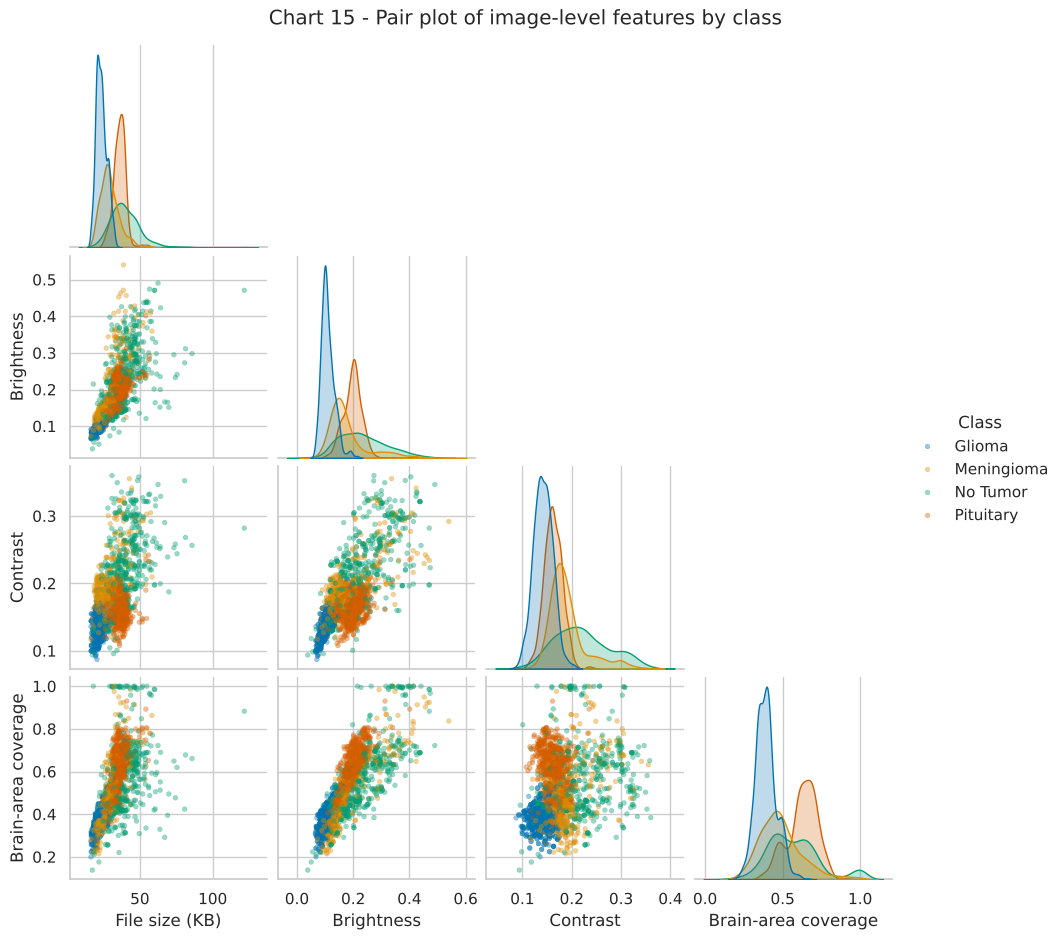

In [34]:
# Pair Plot visualization code
pair_frame = df[FEATURE_COLUMNS + ["display_label"]].rename(columns={**FEATURE_LABELS, "display_label": "Class"})
grid = sns.pairplot(pair_frame, hue="Class", hue_order=DISPLAY_NAMES, palette=PALETTE, corner=True,
                    plot_kws={"alpha": 0.4, "s": 12, "edgecolor": None}, height=2.3)
grid.figure.suptitle("Chart 15 - Pair plot of image-level features by class", y=1.02)
grid.figure.savefig(FIGURES_DIR / "15_pair_plot.png", dpi=110, bbox_inches="tight")
plt.show()

##### 1. Why did you pick the specific chart?

A pair plot shows every two-way relationship as a scatter plot and each feature's per-class distribution on the diagonal. It complements the heatmap by showing the *shape* of the relationships and where each class lies, not just a single coefficient.

##### 2. What is/are the insight(s) found from the chart?

The diagonal panels confirm that every one of the four features has a different distribution for each class. In the scatter panels Glioma forms the tightest group at low values, Pituitary is compact at high coverage, and No Tumor is the most spread out. No pair of features separates the classes cleanly.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

The charts suggest three statements that can be tested on image-level features:

1. Image **brightness differs between classes** (Chart 6).
2. The **supplied train / valid / test folders have the same class proportions** (Chart 11).
3. **No-tumor images have a different contrast** from tumor images (Chart 7).

Significance level: alpha = 0.05. Tests 1 and 3 use **one image per source picture**, because a mirrored copy has identical brightness and contrast and is not an independent observation. Statistical significance here describes the dataset; it does not say anything about biology.

### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **H0:** The distribution of image brightness is the same in all classes.
* **H1:** At least one class has a different brightness distribution.

#### 2. Perform an appropriate statistical test.

In [35]:
# Perform Statistical Test to obtain P-Value
ALPHA = 0.05
df_independent = df.drop_duplicates(subset="source_id")   # one image per source picture

brightness_groups = [group["brightness"].to_numpy() for _, group in df_independent.groupby("label")]
h_statistic, p_value_1 = stats.kruskal(*brightness_groups)
# Epsilon-squared effect size: share of rank variance explained by class.
epsilon_squared = (h_statistic - NUM_CLASSES + 1) / (len(df_independent) - NUM_CLASSES)

show_md(f"Kruskal-Wallis H = **{h_statistic:.1f}**, p = **{p_value_1:.3g}**, effect size (epsilon squared) = "
        f"**{epsilon_squared:.2f}**, n = {len(df_independent):,}. "
        f"Decision: **{'reject' if p_value_1 < ALPHA else 'fail to reject'} H0** at alpha = {ALPHA}.")

Kruskal-Wallis H = **1001.0**, p = **1.12e-216**, effect size (epsilon squared) = **0.48**, n = 2,091. Decision: **reject H0** at alpha = 0.05.

##### Which statistical test have you done to obtain P-Value?

The **Kruskal-Wallis H test**, with epsilon squared as the effect size.

##### Why did you choose the specific statistical test?

The comparison is one numeric variable across more than two independent groups. Brightness is skewed and has different spreads in different classes (Chart 6), which violates the assumptions of one-way ANOVA. Kruskal-Wallis is its rank-based alternative and needs neither normality nor equal variances. The effect size is reported because with thousands of images even a trivial difference would be statistically significant.

### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **H0:** Class label and supplied split folder are independent (all folders have the same class proportions).
* **H1:** Class proportions differ between the supplied folders.

#### 2. Perform an appropriate statistical test.

In [36]:
# Perform Statistical Test to obtain P-Value
contingency = pd.crosstab(df["label"], df["original_split"])
if contingency.shape[1] > 1:
    chi2_statistic, p_value_2, dof, expected = stats.chi2_contingency(contingency)
    cramers_v = np.sqrt(chi2_statistic / (contingency.to_numpy().sum() * (min(contingency.shape) - 1)))
    show_md(f"Chi-square = **{chi2_statistic:.2f}** (dof = {dof}), p = **{p_value_2:.3f}**, Cramer's V = "
            f"**{cramers_v:.3f}**, smallest expected count = {expected.min():.1f}. "
            f"Decision: **{'reject' if p_value_2 < ALPHA else 'fail to reject'} H0** at alpha = {ALPHA}.")
else:
    show_md("The dataset was supplied without split folders, so this test does not apply.")

Chi-square = **5.59** (dof = 6), p = **0.470**, Cramer's V = **0.034**, smallest expected count = 48.6. Decision: **fail to reject H0** at alpha = 0.05.

##### Which statistical test have you done to obtain P-Value?

The **chi-square test of independence**, with Cramer's V as the effect size.

##### Why did you choose the specific statistical test?

Both variables are categorical (class and folder), and the question is whether they are associated. The chi-square test of independence is designed for exactly this contingency-table setting, and all expected cell counts are well above 5, so its approximation is valid. Failing to reject H0 means the supplied folders are consistent with a class-stratified split - which, as Chart 12 showed, does not make that split leak-free.

### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **H0:** Image contrast has the same distribution in no-tumor images and in tumor images.
* **H1:** The contrast distributions of no-tumor and tumor images differ.

#### 2. Perform an appropriate statistical test.

In [37]:
# Perform Statistical Test to obtain P-Value
NO_TUMOR_KEYWORDS = ("no_tumor", "notumor", "no tumor", "healthy", "normal")
no_tumor_classes = [name for name in class_names if name.lower() in NO_TUMOR_KEYWORDS]

if no_tumor_classes:
    is_no_tumor = df_independent["label"].isin(no_tumor_classes)
    contrast_healthy = df_independent.loc[is_no_tumor, "contrast"]
    contrast_tumor = df_independent.loc[~is_no_tumor, "contrast"]
    u_statistic, p_value_3 = stats.mannwhitneyu(contrast_healthy, contrast_tumor, alternative="two-sided")
    # Common-language effect size: chance that a random no-tumor image has higher contrast.
    probability_superiority = u_statistic / (len(contrast_healthy) * len(contrast_tumor))
    show_md(f"Mann-Whitney U = **{u_statistic:,.0f}**, p = **{p_value_3:.3g}**. Median contrast: no tumor "
            f"**{contrast_healthy.median():.3f}** (n = {len(contrast_healthy):,}) vs tumor "
            f"**{contrast_tumor.median():.3f}** (n = {len(contrast_tumor):,}). A randomly chosen no-tumor image has "
            f"higher contrast than a randomly chosen tumor image **{probability_superiority:.0%}** of the time. "
            f"Decision: **{'reject' if p_value_3 < ALPHA else 'fail to reject'} H0** at alpha = {ALPHA}.")
else:
    show_md("No class in this dataset represents 'no tumor', so this test does not apply.")

Mann-Whitney U = **626,814**, p = **2.39e-93**. Median contrast: no tumor **0.215** (n = 483) vs tumor **0.162** (n = 1,608). A randomly chosen no-tumor image has higher contrast than a randomly chosen tumor image **81%** of the time. Decision: **reject H0** at alpha = 0.05.

##### Which statistical test have you done to obtain P-Value?

The two-sided **Mann-Whitney U test**, with the probability of superiority as the effect size.

##### Why did you choose the specific statistical test?

Two independent groups are compared on one numeric variable that is skewed and has outliers (Chart 7). The Mann-Whitney U test compares the groups by ranks and does not assume normality, unlike the independent-samples t-test. The test is two-sided because the hypothesis was about a difference, not a direction.

**Overall conclusion of the hypothesis tests.** The statistics agree with the charts: global image properties are associated with the class label in this dataset, and the supplied folders are class-balanced. Both facts shape the modelling decisions - augmentation that varies brightness, contrast and framing, and a leak-free split.

## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [38]:
# Handling Missing Values & Missing Value Imputation
analysis_columns = ["label", "width", "height", "brightness", "contrast", "foreground_frac"]
remaining_nulls = int(df[analysis_columns].isnull().sum().sum())
empty_classes = [name for name in class_names if (df["label"] == name).sum() == 0]

assert remaining_nulls == 0, "Unexpected null metadata after wrangling."
assert not empty_classes, f"Classes without any valid image: {empty_classes}"
print(f"Null values in analysis columns : {remaining_nulls}")
print(f"Invalid files excluded earlier  : {removed_invalid}")
print(f"Classes without valid images    : {len(empty_classes)}")

Null values in analysis columns : 0
Invalid files excluded earlier  : 0
Classes without valid images    : 0


#### What all missing value imputation techniques have you used and why did you use those techniques?

**No imputation was used, and none would be appropriate.** In an image dataset a "missing value" is a file that cannot be decoded. A missing image cannot be filled in from other images the way a missing number can be replaced by a median: an invented scan would be fabricated medical data. The policy is therefore *detect, report and exclude*: the audit decodes every file, records the reason for any failure, and wrangling drops those rows. The count of excluded files is printed above, and the assertions stop the notebook if a class were to end up empty.

### 2. Handling Outliers

In [39]:
# Handling Outliers & Outlier treatments
def iqr_outlier_mask(values: pd.Series) -> pd.Series:
    """Flag values beyond 1.5 x IQR from the quartiles (Tukey's rule)."""
    q1, q3 = values.quantile([0.25, 0.75])
    spread = q3 - q1
    return (values < q1 - 1.5 * spread) | (values > q3 + 1.5 * spread)

outlier_flags = pd.DataFrame({column: iqr_outlier_mask(df[column])
                              for column in ["brightness", "contrast", "foreground_frac"]})
df["is_statistical_outlier"] = outlier_flags.any(axis=1)

print("Images flagged by the IQR rule:")
print(outlier_flags.sum().to_string())
print(f"Flagged on at least one feature: {int(df['is_statistical_outlier'].sum()):,} "
      f"({df['is_statistical_outlier'].mean():.1%}) - kept in the dataset")
print("\nFlagged images per class:")
print(df.groupby("label")["is_statistical_outlier"].sum().to_string())

Images flagged by the IQR rule:
brightness          81
contrast           182
foreground_frac     33
Flagged on at least one feature: 223 (9.1%) - kept in the dataset

Flagged images per class:
label
glioma          0
meningioma     61
no_tumor      161
pituitary       1


##### What all outlier treatment techniques have you used and why did you use those techniques?

**Outliers were identified with the IQR rule but deliberately not removed, capped or transformed.** In tabular data an extreme value may be an entry error. Here an "outlier" is a real scan that is brighter, higher in contrast or more tightly cropped than usual. Such scans occur in practice, and removing them would make the model less robust and the test set easier than reality. The only images excluded are those that fail technical validity checks (undecodable, or smaller than the minimum side length). Brightness and contrast augmentation, described below, further reduces the model's sensitivity to these variations.

### 3. Categorical Encoding

In [40]:
# Encode your categorical columns
index_to_class = {index: name for name, index in class_to_index.items()}
print("Class label -> integer index")
for name, index in class_to_index.items():
    print(f"  {name:<12} -> {index}   ({int((y_all == index).sum()):,} images)")

Class label -> integer index
  glioma       -> 0   (805 images)
  meningioma   -> 1   (545 images)
  no_tumor     -> 2   (483 images)
  pituitary    -> 3   (610 images)


#### What all categorical encoding techniques have you used & why did you use those techniques?

The only categorical variable used by the model is the **target**. Class labels are encoded into **integer indices** in alphabetical order, and the mapping is saved to `class_names.json` so that the app decodes predictions with exactly the same order.

Integer labels are paired with the **sparse categorical cross-entropy** loss. This is mathematically the same as one-hot encoding with categorical cross-entropy, but it avoids building a one-hot matrix. The integers imply no order between tumor types, because the loss treats each index only as the position of the correct output unit.

Categorical encoding of *input features* does not apply: the inputs are pixel intensities, which are already numeric.

### 4. Textual Data Preprocessing
(It's mandatory for textual dataset i.e., NLP, Sentiment Analysis, Text Clustering etc.)

**Not applicable.** This section of the template covers contraction expansion, lower-casing, punctuation and URL removal, stop-word removal, rephrasing, tokenisation, stemming / lemmatisation, part-of-speech tagging and text vectorisation. The dataset consists of image tensors and contains no free text, so none of these steps has anything to act on. The only text involved is the class folder names, which are handled as labels in the previous step.

The image equivalents of these steps are: *decoding* (instead of tokenising), *resizing and channel standardisation* (instead of text normalisation) and *pixel scaling* (instead of vectorisation). They are implemented in the following subsections.

### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

In [41]:
# Manipulate Features to minimize feature correlation and create new features
# For images, "feature manipulation" is bringing every picture to one tensor
# format: 3-channel RGB at a fixed size. This was done once in Data Wrangling by
# `load_and_resize`; here the result is verified.
original_sizes = df[["width", "height"]].drop_duplicates().to_numpy().tolist()
print(f"Original size(s) [width, height] : {original_sizes}")
print(f"Model input size (height, width) : {IMG_SIZE}")
print(f"Tensor shape of the cache        : {X_all.shape}  (images, height, width, channels)")
print(f"Data type / value range          : {X_all.dtype}, {X_all.min()} to {X_all.max()}")

Original size(s) [width, height] : [[640, 640]]
Model input size (height, width) : (224, 224)
Tensor shape of the cache        : (2443, 224, 224, 3)  (images, height, width, channels)
Data type / value range          : uint8, 0 to 255


**Why 224 x 224?** It is the resolution MobileNetV2 and EfficientNetB0 were pretrained at, so the pretrained filters see structures at the scale they were learned for. It keeps enough detail for lesions to remain visible while cutting the pixel count by about 88 % compared with the original 640 x 640, which keeps training practical on a CPU. Because the originals are square, resizing does not change the aspect ratio.

**Why RGB for grayscale scans?** ImageNet backbones expect three channels. Replicating the gray channel is the standard way to reuse them, and using the same format for the custom CNN keeps a single input contract for all models.

#### 2. Feature Selection

In [42]:
# Select your features wisely to avoid overfitting
# No manual feature selection is performed: the CNN receives all pixels and
# learns which spatial patterns matter. This cell documents the model input.
pixels_per_image = int(np.prod(X_all.shape[1:]))
print(f"Input features per image: {pixels_per_image:,} pixel values "
      f"({IMG_SIZE[0]} x {IMG_SIZE[1]} x 3)")

Input features per image: 150,528 pixel values (224 x 224 x 3)


##### What all feature selection methods have you used  and why?

**Conventional feature selection is not applicable.** Filter, wrapper and embedded selection methods rank individual columns, but a single pixel has no fixed meaning: the same anatomical structure appears at different pixel positions in different images. A CNN does not use pixels as independent features; it learns filters that detect patterns wherever they occur.

Overfitting, which feature selection addresses in tabular work, is controlled here by other means: weight sharing in convolutions, global average pooling in place of a large dense layer, dropout, batch normalisation, data augmentation, early stopping, and transfer learning with a frozen backbone.

##### Which all features you found important and why?

The important features are the ones the networks **learn**, and they cannot be listed by name. To see which image regions drive a prediction, section 7 applies **Grad-CAM**, which highlights the areas that most influenced the selected model's output. The hand-computed descriptors from the EDA (brightness, contrast, coverage) are not given to the models; they were used only to understand the data and its biases.

### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

**Yes - one transformation: pixel intensities are rescaled from the 0-255 integer range to the 0-1 floating-point range.** Neural networks train more stably when inputs are small and on a consistent scale, because gradient sizes depend on input magnitude.

No log, power or histogram transformation is applied. Chart 5 showed that the images already use the full intensity range without clipping, and transformations such as histogram equalisation would alter tissue contrast in ways that are hard to justify clinically.

In [43]:
# Transform Your data
# The transformation used everywhere: uint8 [0, 255] -> float32 [0, 1].
def scale_pixels(images: tf.Tensor) -> tf.Tensor:
    return tf.cast(images, tf.float32) / 255.0

example_scaled = scale_pixels(X_all[:256]).numpy()
print(f"Before: dtype {X_all.dtype}, range {X_all[:256].min()} to {X_all[:256].max()}")
print(f"After : dtype {example_scaled.dtype}, range {example_scaled.min():.1f} to {example_scaled.max():.1f}, "
      f"mean {example_scaled.mean():.3f}")

Before: dtype uint8, range 0 to 255


After : dtype float32, range 0.0 to 1.0, mean 0.175


### 6. Data Scaling

In [44]:
# Scaling your data
# The shared inference function must give exactly the same numbers as the
# training pipeline. This check compares the two paths on real files.
check_rows = df.sample(n=min(8, len(df)), random_state=SEED)
pipeline_pixels = scale_pixels(X_all[check_rows.index.to_numpy()]).numpy()
inference_pixels = np.stack([preprocess_image(DATASET_DIR / path) for path in check_rows["filepath"]])
max_difference = float(np.abs(pipeline_pixels - inference_pixels).max())
assert max_difference == 0.0, "Training and inference preprocessing have diverged!"
print(f"Training pipeline vs inference function, max pixel difference: {max_difference}")

Training pipeline vs inference function, max pixel difference: 0.0


##### Which method have you used to scale you data and why?

**Min-max scaling with fixed bounds: divide by 255.** The minimum (0) and maximum (255) are properties of the 8-bit image format, not statistics estimated from the data, so nothing is "fitted" and there is **no risk of leakage** from validation or test images. Standardisation with a dataset mean and standard deviation was avoided for that reason and because it would add state that the app would have to reproduce.

**One input contract for all models.** Pretrained backbones expect their own input ranges (MobileNetV2: -1 to 1; EfficientNetB0: 0 to 255 with built-in normalisation). Instead of giving each model a different preprocessing function, every model in this project accepts the same 0-1 image and contains a `Rescaling` layer that converts it to what its backbone needs. The conversion is saved inside the model file, so training, evaluation and the Streamlit app cannot disagree. The check above confirms that the training pipeline and the app's function produce identical values.

### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

**No separate dimensionality-reduction step is needed.** Each image has about 150,000 input values, but applying PCA or a similar method before the model would flatten the image and destroy the spatial arrangement that convolutions rely on. A CNN reduces dimensionality itself: pooling and strided convolutions shrink the feature maps step by step, and global average pooling turns the final maps into a short feature vector.

In [45]:
# DImensionality Reduction (If needed)
# Not applied to the model input. For reference, this is how far PCA would have
# to compress the thumbnails used in Chart 13 to keep most of their variance.
cumulative_variance = np.cumsum(PCA(n_components=50, random_state=SEED).fit(thumbnails).explained_variance_ratio_)
print(f"Variance kept by 10 components: {cumulative_variance[9]:.1%} | by 50 components: {cumulative_variance[49]:.1%}")

Variance kept by 10 components: 66.7% | by 50 components: 84.8%


##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

None on the model input. PCA was used **only for visualisation** in Chart 13. Inside the networks, **global average pooling** performs the equivalent role by summarising each final feature map with one number.

### 8. Data Splitting

In [46]:
# Split your data to train and test. Choose Splitting ratio wisely.
def group_stratified_split(frame: pd.DataFrame) -> pd.Series:
    """Assign train / val / test so that classes are stratified AND every file of
    one source picture (e.g. an image and its mirrored copy) stays together."""
    sources = frame.groupby("source_id", sort=True)["label_index"].first().reset_index()
    holdout_fraction = VAL_FRACTION + TEST_FRACTION
    train_sources, holdout_sources = train_test_split(
        sources, test_size=holdout_fraction, stratify=sources["label_index"], random_state=SEED)
    val_sources, test_sources = train_test_split(
        holdout_sources, test_size=TEST_FRACTION / holdout_fraction,
        stratify=holdout_sources["label_index"], random_state=SEED)
    assignment = {**dict.fromkeys(train_sources["source_id"], "train"),
                  **dict.fromkeys(val_sources["source_id"], "val"),
                  **dict.fromkeys(test_sources["source_id"], "test")}
    return frame["source_id"].map(assignment)

df["split"] = group_stratified_split(df)

# Leakage guard: stop immediately if any source picture is in two subsets.
subsets_per_source = df.groupby("source_id")["split"].nunique()
assert subsets_per_source.max() == 1, "A source picture appears in more than one subset!"
assert df["split"].notna().all(), "Some images were not assigned to a subset."

SPLIT_NAMES = ["train", "val", "test"]
split_indices = {name: df.index[df["split"] == name].to_numpy() for name in SPLIT_NAMES}
X_train, y_train = X_all[split_indices["train"]], y_all[split_indices["train"]]
X_val, y_val = X_all[split_indices["val"]], y_all[split_indices["val"]]
X_test, y_test = X_all[split_indices["test"]], y_all[split_indices["test"]]

split_table = pd.crosstab(df["display_label"], df["split"]).reindex(DISPLAY_NAMES)[SPLIT_NAMES]
split_table.loc["Total"] = split_table.sum()
display(split_table)
show_md(f"Split by images - " + ", ".join(f"{name}: **{len(split_indices[name]):,}** ({len(split_indices[name]) / len(df):.1%})"
                                           for name in SPLIT_NAMES)
        + f". Source pictures shared between subsets: **{int((subsets_per_source > 1).sum())}**.")

split,train,val,test
display_label,,,
Glioma,558,126,121
Meningioma,381,82,82
No Tumor,338,72,73
Pituitary,427,92,91
Total,1704,372,367


Split by images - train: **1,704** (69.8%), val: **372** (15.2%), test: **367** (15.0%). Source pictures shared between subsets: **0**.

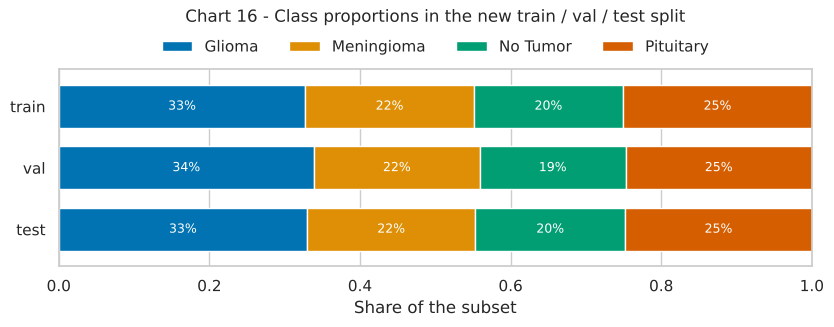

In [47]:
# Chart - 16 : class proportions in the new split
split_share_new = pd.crosstab(df["split"], df["display_label"], normalize="index").reindex(SPLIT_NAMES)[DISPLAY_NAMES]
fig, ax = plt.subplots(figsize=(8.5, 3.6))
split_share_new.plot(kind="barh", stacked=True, color=[PALETTE[c] for c in DISPLAY_NAMES], ax=ax, width=0.7)
for container in ax.containers:
    ax.bar_label(container, labels=[f"{v:.0%}" for v in container.datavalues], label_type="center", color="white", fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("Share of the subset")
ax.set_ylabel("")
ax.set_xlim(0, 1)
ax.legend(ncol=NUM_CLASSES, loc="upper center", bbox_to_anchor=(0.5, 1.22), frameon=False)
ax.set_title("Chart 16 - Class proportions in the new train / val / test split", y=1.2)
finish_figure(fig, "16_new_split_composition")

##### What data splitting ratio have you used and why?

**70 % training, 15 % validation, 15 % test, stratified by class and grouped by source picture, with a fixed seed.**

* **Why not the supplied folders?** Chart 12 showed that mirrored copies of the same picture are spread across them. The images were pooled and re-split so that both copies of a picture always fall in the same subset. The assertion in the code stops the notebook if this is ever violated.
* **Why 70 / 15 / 15?** With a dataset of this size, 70 % leaves enough images to train on, while 15 % each for validation and test gives a few hundred images per subset - enough for per-class metrics to be reasonably stable. The supplied test folder held only about 10 %.
* **Why stratified?** So that each subset has the same class proportions (Chart 16) and per-class metrics are comparable.
* **Roles.** The *training* set fits the weights. The *validation* set drives early stopping, learning-rate scheduling, the tuning experiments and model selection. The *test* set is used once, in the final evaluation, and plays no part in any decision.

**Remaining limitation:** the dataset has no patient identifiers. Different slices from the same patient may still be in different subsets, which grouping by file name cannot detect. A patient-level split would be required for a clinical study.

### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

In [48]:
train_class_counts = pd.Series(np.bincount(y_train, minlength=NUM_CLASSES), index=DISPLAY_NAMES)
train_imbalance_ratio = train_class_counts.max() / train_class_counts.min()
USE_CLASS_WEIGHTS = bool(train_imbalance_ratio > IMBALANCE_RATIO_THRESHOLD)

show_md(f"Training images per class - " + ", ".join(f"{name}: **{count:,}**" for name, count in train_class_counts.items())
        + f". Largest / smallest = **{train_imbalance_ratio:.2f}**, decision threshold = {IMBALANCE_RATIO_THRESHOLD}. "
        + ("**The training set is treated as imbalanced and class weights are applied.**" if USE_CLASS_WEIGHTS
           else "**The training set is treated as sufficiently balanced; no correction is applied.**"))

Training images per class - Glioma: **558**, Meningioma: **381**, No Tumor: **338**, Pituitary: **427**. Largest / smallest = **1.65**, decision threshold = 1.5. **The training set is treated as imbalanced and class weights are applied.**

The dataset is **moderately imbalanced**. The rule used is stated in the configuration: if the largest class is more than 1.5 times the smallest, the imbalance is corrected. The computed ratio and the resulting decision are printed above. An imbalance of this size will not stop a model from learning the smaller classes, but it can tilt borderline predictions towards the largest class, so a light correction is justified.

In [49]:
# Handling Imbalanced Dataset (If needed)
if USE_CLASS_WEIGHTS:
    # "Balanced" weights are inversely proportional to class frequency, so each
    # class contributes equally to the loss overall. Computed on TRAINING labels only.
    weights = compute_class_weight(class_weight="balanced", classes=np.arange(NUM_CLASSES), y=y_train)
    CLASS_WEIGHT = {index: float(weight) for index, weight in enumerate(weights)}
else:
    CLASS_WEIGHT = None

print("Class weights used in the loss:")
for index, name in enumerate(class_names):
    print(f"  {name:<12} {CLASS_WEIGHT[index]:.3f}" if CLASS_WEIGHT else f"  {name:<12} 1.000 (unweighted)")

Class weights used in the loss:
  glioma       0.763
  meningioma   1.118
  no_tumor     1.260
  pituitary    0.998


##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

**Class weights in the loss function**, computed from the training labels only. An error on a rarer class costs more than an error on a common class, in inverse proportion to class frequency. This approach was chosen because it adds no images, removes none, and leaves the validation and test sets untouched.

**Why not SMOTE?** SMOTE creates synthetic samples by interpolating between neighbouring samples in feature space. For raw images that means blending two scans pixel by pixel, which gives a ghosted double exposure of two different heads, not a plausible MRI slice. Distances between images in a 150,000-dimensional pixel space are also poor indicators of similarity, so the "neighbours" SMOTE would pick are not meaningfully similar. Realistic variety is added through augmentation instead.

**Why not random oversampling or undersampling?** Oversampling repeats the same few images and encourages memorisation; undersampling throws away scarce medical data.

### 10. Data Augmentation (training data only)

In [50]:
def build_augmentation(settings: dict) -> keras.Sequential:
    """Training-time augmentation. Inputs and outputs are float images in [0, 1]."""
    steps = []
    if settings["horizontal_flip"]:
        steps.append(layers.RandomFlip("horizontal", seed=SEED))
    steps += [
        # Empty areas created by geometric transforms are filled with black,
        # which matches the scans' natural background.
        layers.RandomRotation(settings["rotation"], fill_mode="constant", fill_value=0.0, seed=SEED),
        layers.RandomZoom(settings["zoom"], fill_mode="constant", fill_value=0.0, seed=SEED),
        layers.RandomTranslation(settings["translation"], settings["translation"],
                                 fill_mode="constant", fill_value=0.0, seed=SEED),
        layers.RandomBrightness(settings["brightness"], value_range=(0.0, 1.0), seed=SEED),
        layers.RandomContrast(settings["contrast"], value_range=(0.0, 1.0), seed=SEED),
    ]
    return keras.Sequential(steps, name="train_augmentation")

augmenter = build_augmentation(AUGMENTATION)

def augment_batch(images: tf.Tensor) -> tf.Tensor:
    # Clip so that brightness / contrast changes cannot leave the valid range.
    return tf.clip_by_value(augmenter(images, training=True), 0.0, 1.0)

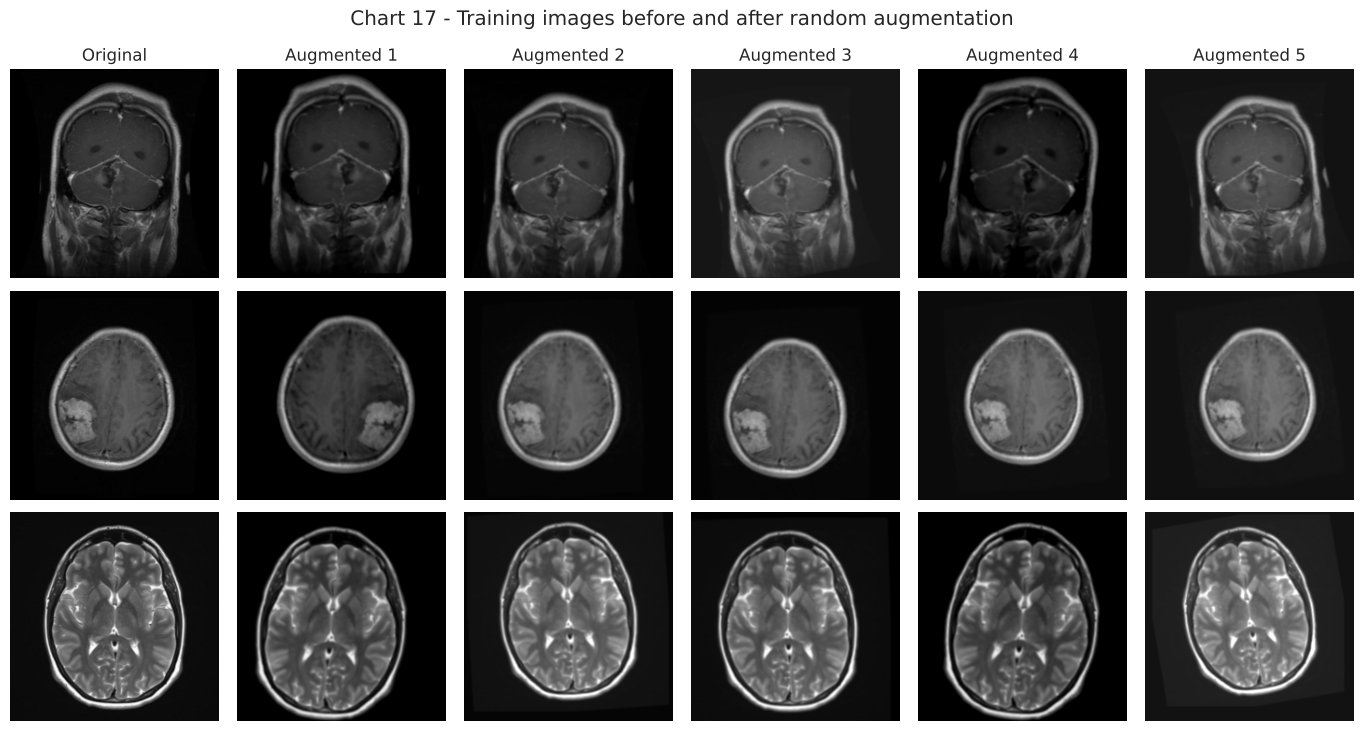

In [51]:
# Chart - 17 : original training images and augmented versions
AUGMENTED_VERSIONS = 5
example_positions = [int(np.flatnonzero(y_train == index)[0]) for index in range(min(NUM_CLASSES, 3))]
fig, axes = plt.subplots(len(example_positions), AUGMENTED_VERSIONS + 1,
                         figsize=(2.3 * (AUGMENTED_VERSIONS + 1), 2.5 * len(example_positions)))
for row_index, position in enumerate(example_positions):
    original = scale_pixels(X_train[position][np.newaxis, ...])
    axes[row_index, 0].imshow(original[0])
    axes[row_index, 0].set_title("Original" if row_index == 0 else "")
    for version in range(AUGMENTED_VERSIONS):
        axes[row_index, version + 1].imshow(augment_batch(original)[0])
        axes[row_index, version + 1].set_title(f"Augmented {version + 1}" if row_index == 0 else "")
    for axis in axes[row_index]:
        axis.axis("off")
fig.suptitle("Chart 17 - Training images before and after random augmentation")
finish_figure(fig, "17_augmentation_examples")

**Why augment?** The training set is small. Augmentation shows the network a slightly different version of each image every epoch, so it cannot simply memorise pixels and has to learn patterns that survive small changes.

| Augmentation | Setting | Rationale |
|---|---|---|
| Rotation | about +/- 11 degrees | Patients' heads are never perfectly aligned in the scanner. Larger rotations would produce orientations that do not occur. |
| Zoom | +/- 10 % | Varies how much of the frame the head fills, the framing bias seen in Chart 8. |
| Translation | +/- 5 % | The head is not always centred. The black border leaves room to shift without cutting anatomy. |
| Brightness | +/- 10 % | Scanner settings differ. Directly targets the brightness shortcut found in Chart 6. |
| Contrast | +/- 10 % | Same reason, for the contrast differences in Chart 7. |
| Horizontal flip | on | See below. |
| Vertical flip | **off** | An upside-down head is not a realistic input, so it would add unrealistic examples without benefit. |

**Is horizontal flipping medically reasonable here?** A left-right flip changes which side a lesion appears on. That matters for tasks where the side is part of the answer (surgical planning, lesion localisation). This project predicts only the tumor **type**, which does not depend on the side, and the dataset itself already contains left-right mirrored copies (section 3), so the flip is consistent with the data. It would have to be removed if the model were extended to report location.

The settings are intentionally mild. The differences between tumor types are subtle, and strong distortions could erase them. Chart 17 confirms that the augmented images still look like plausible MRI slices.

**Leakage control:** augmentation is applied inside the training input pipeline only. Validation and test images go through resizing and scaling alone.

### 11. Input Pipelines

In [52]:
def make_dataset(images: np.ndarray, labels: np.ndarray | None = None, *, training: bool = False,
                 augment: bool = False) -> tf.data.Dataset:
    """Build a tf.data pipeline: (shuffle) -> batch -> scale to [0, 1] -> (augment).

    Shuffling and augmentation are only ever enabled for the training subset.
    """
    if augment and not training:
        raise ValueError("Augmentation must not be applied to validation or test data.")
    data = images if labels is None else (images, labels)
    dataset = tf.data.Dataset.from_tensor_slices(data)
    if training:
        dataset = dataset.shuffle(len(images), seed=SEED, reshuffle_each_iteration=True)
    dataset = dataset.batch(BATCH_SIZE)
    if labels is None:
        dataset = dataset.map(scale_pixels, num_parallel_calls=tf.data.AUTOTUNE)
    else:
        dataset = dataset.map(lambda x, y: (scale_pixels(x), y), num_parallel_calls=tf.data.AUTOTUNE)
        if augment:
            dataset = dataset.map(lambda x, y: (augment_batch(x), y), num_parallel_calls=tf.data.AUTOTUNE)
    return dataset.prefetch(tf.data.AUTOTUNE)

train_ds_augmented = make_dataset(X_train, y_train, training=True, augment=True)
train_ds_plain = make_dataset(X_train, y_train, training=True, augment=False)
val_ds = make_dataset(X_val, y_val)

sample_images, sample_labels = next(iter(train_ds_augmented))
print(f"Training batch : images {tuple(sample_images.shape)} {sample_images.dtype.name}, "
      f"range {float(tf.reduce_min(sample_images)):.2f} to {float(tf.reduce_max(sample_images)):.2f}; "
      f"labels {tuple(sample_labels.shape)} {sample_labels.dtype.name}")
print(f"Batches per epoch: train {len(train_ds_augmented)}, validation {len(val_ds)}")

Training batch : images (32, 224, 224, 3) float32, range 0.00 to 1.00; labels (32,) int64
Batches per epoch: train 54, validation 12


## ***7. ML Model Implementation***

Three models are built and compared:

| | Model | Idea |
|---|---|---|
| **Model 1** | Custom CNN | A compact network designed and trained from scratch on the MRI data only |
| **Model 2** | MobileNetV2 | ImageNet-pretrained, lightweight, designed for fast inference |
| **Model 3** | EfficientNetB0 | ImageNet-pretrained, strong accuracy for its size |

**Why these two pretrained networks?** Both are small enough to train on a CPU and to deploy in a web app, and both were pretrained at 224 x 224. ResNet50 and InceptionV3 have roughly 23 million parameters each in their feature extractors - about ten times MobileNetV2 - which is a poor match for a training set of under two thousand images and for CPU-only hardware. Which model is best is **not assumed**; it is decided by the validation results below.

**Evaluation protocol.** Every tuning decision and the final model selection use the **validation set**. The **test set is evaluated once**, in section 7.4, after all decisions are made.

**Selection score: worst-case validation macro-F1 under mild intensity shifts.** The EDA showed that brightness and contrast differ between classes for reasons unrelated to pathology, so a model can score well by reading scan style. Such a model would look excellent on validation images taken from the same sources and then fail on a scanner with slightly different settings. To detect this, every model is scored on the validation set five times: on the original images and after a brightness change of +/- 10 % and a contrast change of +/- 20 % (`ROBUSTNESS_SHIFTS`). The **lowest** of the five macro-F1 values is the selection score. A model that only works at the exact brightness of the training data is penalised; a model that looks at anatomy is not. The ordinary validation metrics on unmodified images are reported next to it.

**Cross-validation.** Because deep learning image models are computationally expensive to retrain across multiple folds, a fixed stratified train / validation / test split was used for the main experiment. Five-fold cross-validation would multiply the training time of every experiment by five. The fixed split is stratified by class and grouped by source picture, and the results are reported with that limitation stated: they come from a single split, so small differences between models should not be over-interpreted.

**Hyperparameter tuning.** An exhaustive grid search is impractical for CNNs on a CPU. Each model instead gets one **controlled experiment** - a baseline and a tuned configuration compared on the validation set.

### Shared training and evaluation utilities

In [53]:
INPUT_SHAPE = (*IMG_SIZE, 3)
LOG_DIR = REPORTS_DIR / "training_logs"
LOG_DIR.mkdir(parents=True, exist_ok=True)

METRIC_LABELS = {"accuracy": "Accuracy", "precision_macro": "Precision (macro)", "recall_macro": "Recall (macro)",
                 "f1_macro": "F1 (macro)", "f1_weighted": "F1 (weighted)"}
VALIDATION_CHART_LABELS = {**METRIC_LABELS, "f1_macro_robust": "F1 (macro), worst shift"}
SELECTION_METRIC = "f1_macro_robust"


def count_parameters(model: keras.Model) -> dict:
    """Trainable / non-trainable / total parameter counts."""
    trainable = int(sum(np.prod(weight.shape) for weight in model.trainable_weights))
    non_trainable = int(sum(np.prod(weight.shape) for weight in model.non_trainable_weights))
    return {"trainable": trainable, "non_trainable": non_trainable, "total": trainable + non_trainable}


def make_callbacks(tag: str, patience: int) -> tuple[list, Path]:
    """EarlyStopping + ModelCheckpoint + ReduceLROnPlateau + CSVLogger, all watching validation loss.

    Validation loss is monitored instead of validation accuracy because it also
    reflects how confident the predictions are, so it reacts earlier to overfitting.
    """
    checkpoint_path = CHECKPOINT_DIR / f"{tag}.keras"
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True, verbose=1),
        keras.callbacks.ModelCheckpoint(str(checkpoint_path), monitor="val_loss", save_best_only=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=max(1, patience // 2),
                                          min_lr=1e-6, verbose=1),
        keras.callbacks.CSVLogger(str(LOG_DIR / f"{tag}.csv")),
    ]
    return callbacks, checkpoint_path


def train_model(model: keras.Model, train_dataset: tf.data.Dataset, *, epochs: int, learning_rate: float,
                patience: int, tag: str) -> dict:
    """Compile and fit `model`, then load the weights of its best validation epoch."""
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
                  loss=keras.losses.SparseCategoricalCrossentropy(),
                  metrics=["accuracy"])
    callbacks, checkpoint_path = make_callbacks(tag, patience)
    started = time.perf_counter()
    history = model.fit(train_dataset, validation_data=val_ds, epochs=epochs,
                        class_weight=CLASS_WEIGHT, callbacks=callbacks, verbose=2)
    seconds = time.perf_counter() - started
    # Explicitly reload the checkpoint so the evaluated weights are always the
    # best-validation-loss epoch, whether or not early stopping was triggered.
    model.load_weights(checkpoint_path)
    history_frame = pd.DataFrame(history.history)
    return {"history": history_frame, "seconds": seconds, "checkpoint": checkpoint_path,
            "epochs_run": len(history_frame), "best_epoch": int(history_frame["val_loss"].idxmin()) + 1}


def apply_shift(images: tf.Tensor, shift: tuple | None) -> tf.Tensor:
    """Deterministic brightness / contrast change on [0, 1] images (robustness testing only)."""
    if shift is None:
        return images
    kind, amount = shift
    if kind == "brightness":
        return tf.clip_by_value(images + amount, 0.0, 1.0)
    if kind == "contrast":
        image_mean = tf.reduce_mean(images, axis=[1, 2, 3], keepdims=True)
        return tf.clip_by_value((images - image_mean) * amount + image_mean, 0.0, 1.0)
    raise ValueError(f"Unknown shift type: {kind}")


def predict_probabilities(model: keras.Model, images: np.ndarray, shift: tuple | None = None) -> np.ndarray:
    """Class probabilities for a set of uint8 images (no shuffling, no augmentation)."""
    dataset = make_dataset(images)
    if shift is not None:
        dataset = dataset.map(lambda batch: apply_shift(batch, shift))
    return model.predict(dataset, verbose=0)


def macro_f1_under_shifts(model: keras.Model, images: np.ndarray, labels: np.ndarray) -> dict:
    """Macro-F1 on the original images and under every shift in ROBUSTNESS_SHIFTS."""
    return {name: float(f1_score(labels, predict_probabilities(model, images, shift).argmax(axis=1),
                                 average="macro", zero_division=0))
            for name, shift in ROBUSTNESS_SHIFTS.items()}


def evaluate_on_validation(model: keras.Model) -> dict:
    """Standard validation metrics plus the worst-case macro-F1 used for model selection."""
    metrics = compute_metrics(y_val, predict_probabilities(model, X_val))
    metrics["f1_by_shift"] = macro_f1_under_shifts(model, X_val, y_val)
    metrics["f1_macro_robust"] = min(metrics["f1_by_shift"].values())
    return metrics


def print_validation(metrics: dict) -> None:
    print({key: round(value, 4) for key, value in metrics.items() if key != "f1_by_shift"})
    print("Macro-F1 by shift:", {name: round(value, 3) for name, value in metrics["f1_by_shift"].items()})


def compute_metrics(y_true: np.ndarray, probabilities: np.ndarray) -> dict:
    """Headline metrics. Macro averages weight every class equally, whatever its size."""
    y_pred = probabilities.argmax(axis=1)
    precision, recall, f1_macro, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0)
    try:
        roc_auc = float(roc_auc_score(y_true, probabilities, multi_class="ovr", average="macro",
                                      labels=np.arange(NUM_CLASSES)))
    except ValueError:      # a class is absent from y_true (possible only in tiny smoke-test subsets)
        roc_auc = float("nan")
    return {"accuracy": float(accuracy_score(y_true, y_pred)), "precision_macro": float(precision),
            "recall_macro": float(recall), "f1_macro": float(f1_macro),
            "f1_weighted": float(f1_score(y_true, y_pred, average="weighted", zero_division=0)),
            "roc_auc_ovr": roc_auc}


def plot_training_history(history: pd.DataFrame, title: str, figure_name: str,
                          stage_boundary: int | None = None) -> None:
    """Training vs validation accuracy and loss, with the selected epoch marked."""
    epochs = np.arange(1, len(history) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
    for axis, metric, label in zip(axes, ["accuracy", "loss"], ["Accuracy", "Loss"]):
        axis.plot(epochs, history[metric], marker="o", markersize=3, label="Training")
        axis.plot(epochs, history[f"val_{metric}"], marker="o", markersize=3, label="Validation")
        if stage_boundary:
            axis.axvline(stage_boundary + 0.5, color="gray", linestyle="--", linewidth=1)
            axis.text(stage_boundary + 0.6, axis.get_ylim()[0], " fine-tuning starts", color="gray", va="bottom", fontsize=9)
        axis.set_xlabel("Epoch")
        axis.set_ylabel(label)
        axis.set_title(label)
        axis.legend()
    fig.suptitle(title)
    finish_figure(fig, figure_name)


def plot_metric_scores(scores: dict, title: str, figure_name: str) -> None:
    """Evaluation-metric score chart: one group of bars per metric, one bar per configuration."""
    frame = pd.DataFrame({label: [metrics[key] for key in VALIDATION_CHART_LABELS] for label, metrics in scores.items()},
                         index=list(VALIDATION_CHART_LABELS.values()))
    ax = frame.plot(kind="bar", figsize=(12, 4.2), width=0.8, rot=0)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", fontsize=8, padding=2)
    ax.set_ylim(0, 1.1)
    ax.set_ylabel("Score on the validation set")
    ax.set_title(title)
    ax.legend(loc="lower right")
    finish_figure(ax.figure, figure_name)


def describe_fit(run: dict) -> str:
    """One-sentence, data-driven reading of a training curve."""
    history = run["history"]
    best = history.loc[run["best_epoch"] - 1]
    gap = best["accuracy"] - best["val_accuracy"]
    stopped_early = run["epochs_run"] < run.get("max_epochs", run["epochs_run"])
    return (f"Ran **{run['epochs_run']}** epoch(s) in {run['seconds'] / 60:.1f} min; best validation loss at epoch "
            f"**{run['best_epoch']}** (val loss {best['val_loss']:.3f}, val accuracy {best['val_accuracy']:.3f}, "
            f"training accuracy {best['accuracy']:.3f}, gap {gap:+.3f}). "
            + ("Early stopping ended training before the epoch limit. " if stopped_early
               else "Training used the full epoch budget. "))

EXPERIMENTS = {}   # every configuration that was trained, with its validation metrics
FINAL = {}         # the chosen configuration of each of the three models

### ML Model - 1 : Custom CNN (built from scratch)

In [54]:
# ML Model - 1 Implementation
CNN_FILTERS = (32, 64, 128, 256)
CNN_DENSE_UNITS = 128
# Batch-norm moving averages are updated once per step. With only a few dozen
# steps per epoch, the Keras default (0.99) lags far behind the weights and makes
# validation results erratic in early epochs; 0.9 lets the statistics keep up.
CNN_BN_MOMENTUM = 0.9


def conv_block(x, filters: int, *, strides: int, pool: bool, name: str):
    """Conv -> BatchNorm -> ReLU (-> MaxPool). The bias is omitted because
    batch normalisation has its own shift parameter."""
    x = layers.Conv2D(filters, kernel_size=3, strides=strides, padding="same", use_bias=False,
                      kernel_initializer="he_normal", name=f"{name}_conv")(x)
    x = layers.BatchNormalization(momentum=CNN_BN_MOMENTUM, name=f"{name}_bn")(x)
    x = layers.ReLU(name=f"{name}_relu")(x)
    if pool:
        x = layers.MaxPooling2D(pool_size=2, name=f"{name}_pool")(x)
    return x


def build_custom_cnn(num_classes: int, dropout_rate: float, name: str = "custom_cnn") -> keras.Model:
    inputs = keras.Input(shape=INPUT_SHAPE, name="mri_image")   # RGB image scaled to [0, 1]
    x = inputs
    last_block = len(CNN_FILTERS) - 1
    for block_index, filters in enumerate(CNN_FILTERS):
        # The first block downsamples with stride 2 to cut computation early; the
        # last block is not pooled so Grad-CAM keeps a 14 x 14 spatial map.
        x = conv_block(x, filters, strides=2 if block_index == 0 else 1,
                       pool=block_index < last_block, name=f"block{block_index + 1}")
    x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
    x = layers.Dropout(dropout_rate, name="dropout_features")(x)
    x = layers.Dense(CNN_DENSE_UNITS, activation="relu", kernel_initializer="he_normal", name="dense_features")(x)
    x = layers.Dropout(dropout_rate, name="dropout_head")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="class_probabilities")(x)
    return keras.Model(inputs, outputs, name=name)


set_global_seed(SEED)
cnn_baseline = build_custom_cnn(NUM_CLASSES, CNN_BASELINE["dropout"], name="custom_cnn_baseline")
cnn_baseline.summary()
cnn_parameters = count_parameters(cnn_baseline)
print(f"Trainable: {cnn_parameters['trainable']:,} | non-trainable: {cnn_parameters['non_trainable']:,} | "
      f"total: {cnn_parameters['total']:,}")

Model: "custom_cnn_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mri_image (InputLayer)          │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv (Conv2D)            │ (None, 112, 112, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_bn (BatchNormalization)  │ (None, 112, 112, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_relu (ReLU)              │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv (Conv2D)            │ (None, 56, 56, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_bn (BatchNormalization)  │ (None, 56, 56, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_relu (ReLU)              │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv (Conv2D)            │ (None, 28, 28, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_bn (BatchNormalization)  │ (None, 28, 28, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_relu (ReLU)              │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv (Conv2D)            │ (None, 14, 14, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_bn (BatchNormalization)  │ (None, 14, 14, 256)    │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_relu (ReLU)              │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_features (Dropout)      │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_features (Dense)          │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_head (Dropout)          │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_probabilities (Dense)     │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,268 (1.61 MB)

 Trainable params: 422,308 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

Trainable: 422,308 | non-trainable: 960 | total: 423,268


In [55]:
# Fit the Algorithm
baseline_dataset = train_ds_augmented if CNN_BASELINE["augment"] else train_ds_plain
cnn_baseline_run = train_model(cnn_baseline, baseline_dataset, epochs=CNN_EPOCHS, learning_rate=CNN_LEARNING_RATE,
                               patience=CNN_PATIENCE, tag="custom_cnn_baseline")
cnn_baseline_run["max_epochs"] = CNN_EPOCHS

# Predict on the model
cnn_baseline_run["val_metrics"] = evaluate_on_validation(cnn_baseline)
EXPERIMENTS["Custom CNN - baseline"] = cnn_baseline_run
print_validation(cnn_baseline_run["val_metrics"])

Epoch 1/40


54/54 - 21s - 381ms/step - accuracy: 0.6643 - loss: 0.8723 - val_accuracy: 0.7070 - val_loss: 0.6943 - learning_rate: 5.0000e-04


Epoch 2/40


54/54 - 18s - 333ms/step - accuracy: 0.7570 - loss: 0.6676 - val_accuracy: 0.7661 - val_loss: 0.5934 - learning_rate: 5.0000e-04


Epoch 3/40


54/54 - 17s - 319ms/step - accuracy: 0.7600 - loss: 0.6211 - val_accuracy: 0.8306 - val_loss: 0.4541 - learning_rate: 5.0000e-04


... (67 outputs left out)

54/54 - 21s - 381ms/step - accuracy: 0.9818 - loss: 0.0766 - val_accuracy: 0.9301 - val_loss: 0.1754 - learning_rate: 6.2500e-05


Epoch 35: early stopping


Restoring model weights from the end of the best epoch: 27.


{'accuracy': 0.9409, 'precision_macro': 0.9346, 'recall_macro': 0.9374, 'f1_macro': 0.9349, 'f1_weighted': 0.94, 'roc_auc_ovr': 0.9948, 'f1_macro_robust': 0.1122}
Macro-F1 by shift: {'Original': 0.935, 'Brightness +10%': 0.112, 'Brightness -10%': 0.684, 'Contrast -20%': 0.808, 'Contrast +20%': 0.928}


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

**Architecture.** The custom CNN is a plain, sequential stack that can be explained layer by layer:

| Component | Role |
|---|---|
| **Conv2D (3 x 3)** | Learns small local patterns. Stacking four blocks with 32 -> 64 -> 128 -> 256 filters lets later layers combine simple patterns into larger structures. |
| **Batch normalisation** | Normalises each layer's activations per batch, which stabilises and speeds up training and adds mild regularisation. Its moving-average momentum is set to 0.9 instead of the default 0.99, because an epoch here has only a few dozen steps and slower statistics made validation results erratic. |
| **ReLU** | Non-linearity; cheap and avoids vanishing gradients. |
| **Max pooling / stride 2** | Halves the spatial size, reducing computation and giving tolerance to small shifts. |
| **Global average pooling** | Replaces a large `Flatten` + dense layer by averaging each of the 256 feature maps to one value. This removes most of the parameters a flattened layer would need and so reduces overfitting. |
| **Dropout** | Randomly disables units during training so the network cannot depend on any single feature. |
| **Dense (128, ReLU)** | Combines the pooled features. |
| **Dense (softmax)** | Outputs one probability per class; the probabilities sum to 1. |

The model has well under one million parameters (exact counts above). That is deliberate: with a training set this small, a large from-scratch network would memorise the data.

**Baseline configuration:** no augmentation and light dropout. It shows what the architecture does with minimal regularisation and gives the reference point for the tuning experiment.

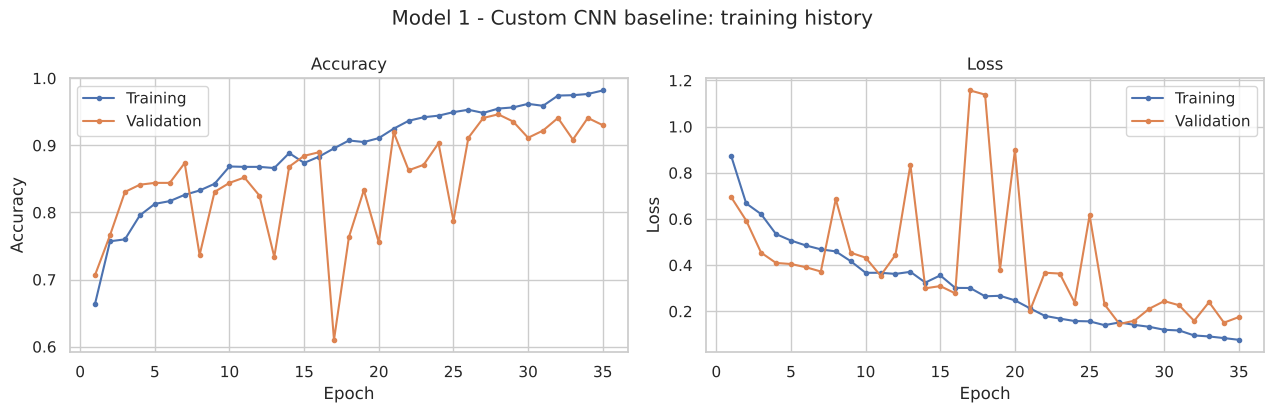

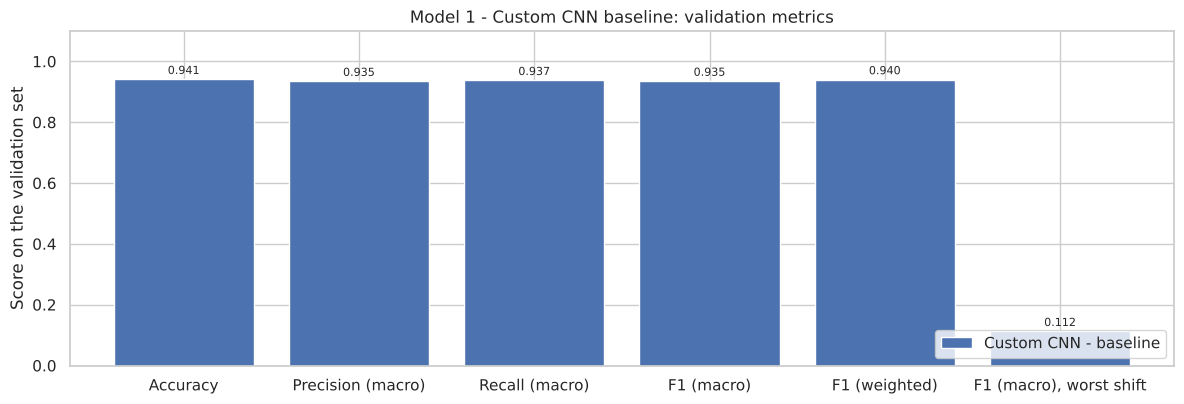

Ran **35** epoch(s) in 10.9 min; best validation loss at epoch **27** (val loss 0.145, val accuracy 0.941, training accuracy 0.948, gap +0.007). Early stopping ended training before the epoch limit. 

In [56]:
# Visualizing evaluation Metric Score chart
plot_training_history(cnn_baseline_run["history"], "Model 1 - Custom CNN baseline: training history",
                      "18_cnn_baseline_history")
plot_metric_scores({"Custom CNN - baseline": cnn_baseline_run["val_metrics"]},
                   "Model 1 - Custom CNN baseline: validation metrics", "19_cnn_baseline_metrics")
show_md(describe_fit(cnn_baseline_run))

**How to read the training curves.** If training accuracy keeps rising while validation accuracy flattens or validation loss turns upward, the model is **overfitting** - memorising training images. If both stay low, it is **underfitting**. Jagged validation curves indicate **instability**, which is common with batch normalisation on small validation sets. The sentence above reports the gap between training and validation accuracy at the selected epoch and whether early stopping ended the run.

#### 2. Cross- Validation & Hyperparameter Tuning

In [57]:
# ML Model - 1 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
# Controlled experiment: same architecture, seed, optimiser, learning rate and
# data split as the baseline; only the regularisation changes
# (dropout raised, training-time augmentation switched on).
set_global_seed(SEED)
cnn_tuned = build_custom_cnn(NUM_CLASSES, CNN_TUNED["dropout"], name="custom_cnn_tuned")

# Fit the Algorithm
tuned_dataset = train_ds_augmented if CNN_TUNED["augment"] else train_ds_plain
cnn_tuned_run = train_model(cnn_tuned, tuned_dataset, epochs=CNN_EPOCHS, learning_rate=CNN_LEARNING_RATE,
                            patience=CNN_PATIENCE, tag="custom_cnn_tuned")
cnn_tuned_run["max_epochs"] = CNN_EPOCHS

# Predict on the model
cnn_tuned_run["val_metrics"] = evaluate_on_validation(cnn_tuned)
EXPERIMENTS["Custom CNN - tuned"] = cnn_tuned_run
print_validation(cnn_tuned_run["val_metrics"])

Epoch 1/40


54/54 - 28s - 513ms/step - accuracy: 0.5499 - loss: 1.1100 - val_accuracy: 0.7715 - val_loss: 0.6728 - learning_rate: 5.0000e-04


Epoch 2/40


54/54 - 26s - 478ms/step - accuracy: 0.6444 - loss: 0.9307 - val_accuracy: 0.7661 - val_loss: 0.6650 - learning_rate: 5.0000e-04


Epoch 3/40


54/54 - 26s - 481ms/step - accuracy: 0.6755 - loss: 0.8323 - val_accuracy: 0.7527 - val_loss: 0.5738 - learning_rate: 5.0000e-04


... (28 outputs left out)

54/54 - 26s - 475ms/step - accuracy: 0.7952 - loss: 0.5422 - val_accuracy: 0.7581 - val_loss: 0.5728 - learning_rate: 1.2500e-04


Epoch 16: early stopping


Restoring model weights from the end of the best epoch: 8.


{'accuracy': 0.8333, 'precision_macro': 0.8234, 'recall_macro': 0.8325, 'f1_macro': 0.8218, 'f1_weighted': 0.8294, 'roc_auc_ovr': 0.9699, 'f1_macro_robust': 0.6454}
Macro-F1 by shift: {'Original': 0.822, 'Brightness +10%': 0.747, 'Brightness -10%': 0.645, 'Contrast -20%': 0.66, 'Contrast +20%': 0.74}


##### Which hyperparameter optimization technique have you used and why?

A **controlled manual experiment evaluated on the fixed validation set**, not GridSearchCV, RandomSearchCV or Bayesian optimisation. Those methods retrain the model many times - often combined with K-fold cross-validation - which is designed for models that train in seconds. Each CNN run here takes many minutes on a CPU, so a search over learning rate, batch size, dropout, optimiser and augmentation strength would need dozens of runs.

The experiment targets the hyperparameters most likely to matter for a small from-scratch network - **the amount of regularisation**:

| Setting | Baseline | Tuned |
|---|---|---|
| Dropout rate | 0.2 | 0.4 |
| Training augmentation | off | on |
| Learning rate, optimiser, batch size, architecture, seed, split | identical | identical |

The learning rate is additionally adapted during training by `ReduceLROnPlateau`, which halves it when validation loss stops improving, and the number of epochs is tuned automatically by `EarlyStopping`. Both tuned settings change together, so the experiment measures their combined effect and cannot separate the contribution of each.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

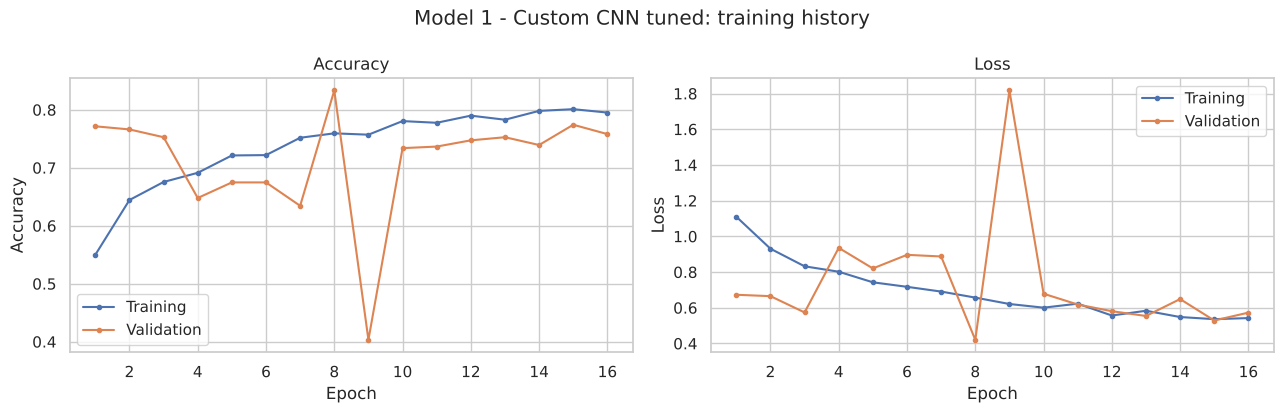

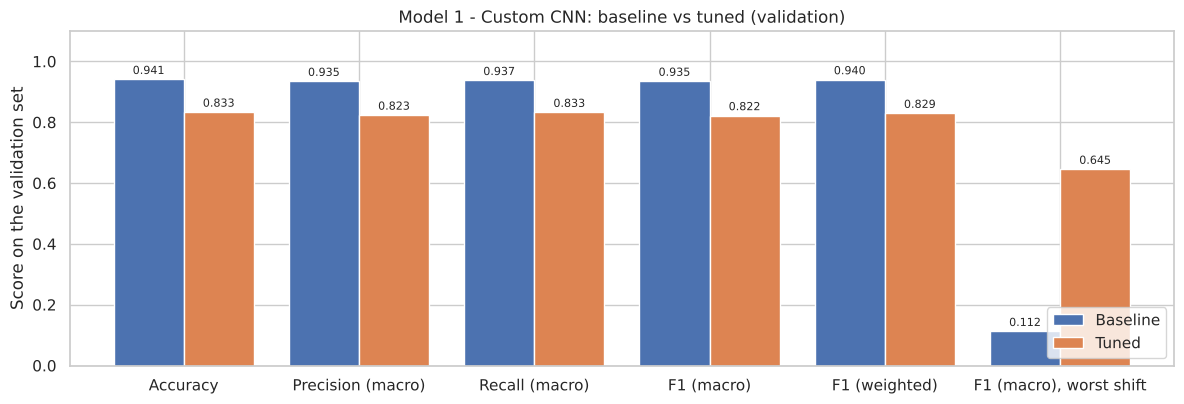

Ran **16** epoch(s) in 8.4 min; best validation loss at epoch **8** (val loss 0.420, val accuracy 0.833, training accuracy 0.759, gap -0.074). Early stopping ended training before the epoch limit. On unmodified validation images the tuned configuration **reduced** macro-F1: 0.935 -> 0.822 (-11.3 percentage points; accuracy -10.8 pp, macro recall -10.5 pp). On the selection score (worst-case macro-F1 under intensity shifts) it **improved** the result: 0.112 (worst at 'Brightness +10%') -> 0.645 (worst at 'Brightness -10%'), +53.3 pp. **Configuration kept: tuned.**

In [58]:
plot_training_history(cnn_tuned_run["history"], "Model 1 - Custom CNN tuned: training history", "20_cnn_tuned_history")
plot_metric_scores({"Baseline": cnn_baseline_run["val_metrics"], "Tuned": cnn_tuned_run["val_metrics"]},
                   "Model 1 - Custom CNN: baseline vs tuned (validation)", "21_cnn_baseline_vs_tuned")


def summarise_comparison(baseline: dict, tuned: dict, baseline_label: str, tuned_label: str) -> tuple[str, str]:
    """Pick the better configuration by the selection score and describe the change."""
    before, after = baseline["val_metrics"], tuned["val_metrics"]
    change = {key: after[key] - before[key] for key in VALIDATION_CHART_LABELS}
    winner = tuned_label if after[SELECTION_METRIC] >= before[SELECTION_METRIC] else baseline_label

    def direction(delta: float) -> str:
        return "improved" if delta > 0 else ("did not change" if delta == 0 else "reduced")

    worst_before = min(before["f1_by_shift"], key=before["f1_by_shift"].get)
    worst_after = min(after["f1_by_shift"], key=after["f1_by_shift"].get)
    text = (f"On unmodified validation images the tuned configuration **{direction(change['f1_macro'])}** macro-F1: "
            f"{before['f1_macro']:.3f} -> {after['f1_macro']:.3f} ({change['f1_macro'] * 100:+.1f} percentage points; "
            f"accuracy {change['accuracy'] * 100:+.1f} pp, macro recall {change['recall_macro'] * 100:+.1f} pp). "
            f"On the selection score (worst-case macro-F1 under intensity shifts) it **{direction(change[SELECTION_METRIC])}** "
            f"the result: {before[SELECTION_METRIC]:.3f} (worst at '{worst_before}') -> {after[SELECTION_METRIC]:.3f} "
            f"(worst at '{worst_after}'), {change[SELECTION_METRIC] * 100:+.1f} pp. "
            f"**Configuration kept: {winner}.**")
    return winner, text


cnn_winner, cnn_summary = summarise_comparison(cnn_baseline_run, cnn_tuned_run, "baseline", "tuned")
show_md(describe_fit(cnn_tuned_run) + cnn_summary)

cnn_choice = (cnn_tuned, cnn_tuned_run) if cnn_winner == "tuned" else (cnn_baseline, cnn_baseline_run)
FINAL["Custom CNN"] = {"model": cnn_choice[0], "variant": cnn_winner, "val_metrics": cnn_choice[1]["val_metrics"],
                       "train_seconds": cnn_choice[1]["seconds"], "history": cnn_choice[1]["history"],
                       "stage_boundary": None, "file_stem": "custom_cnn"}

The chart and the computed sentence above state what the stronger regularisation changed, and by how much. Two results are reported because they answer different questions. Macro-F1 on **unmodified** validation images shows how well a configuration fits data that looks exactly like the training data. The **worst-case macro-F1 under intensity shifts** shows whether it still works when brightness or contrast moves slightly. A network trained without augmentation can do well on the first and badly on the second, which is the signature of the brightness shortcut described in the EDA.

The configuration with the higher **selection score** is kept as "Custom CNN" for the final comparison - whichever one that is. With a validation set of a few hundred images, a difference of about one percentage point is within the noise of a single split.

### ML Model - 2 : MobileNetV2 (transfer learning)

In [59]:
# ML Model - 2 Implementation
# Each backbone needs its own input range. A Rescaling layer inside the model
# converts the project-wide [0, 1] input, so callers never need to know this.
BACKBONES = {
    "MobileNetV2": {"constructor": keras.applications.MobileNetV2,
                    "input_scale": 2.0, "input_offset": -1.0,      # [0, 1] -> [-1, 1]
                    "fine_tune_layers": 30},
    "EfficientNetB0": {"constructor": keras.applications.EfficientNetB0,
                       "input_scale": 255.0, "input_offset": 0.0,  # [0, 1] -> [0, 255]; the network normalises internally
                       "fine_tune_layers": 40},
}


def build_transfer_model(backbone_name: str, num_classes: int, dropout_rate: float) -> tuple[keras.Model, list[str]]:
    """ImageNet backbone (frozen) + new classification head. Returns the model and its backbone layer names."""
    spec = BACKBONES[backbone_name]
    inputs = keras.Input(shape=INPUT_SHAPE, name="mri_image")
    scaled = layers.Rescaling(spec["input_scale"], offset=spec["input_offset"], name="backbone_input_scaling")(inputs)
    try:
        backbone = spec["constructor"](include_top=False, weights="imagenet", input_tensor=scaled)
    except Exception as exc:  # most often: no internet connection on the first run
        raise RuntimeError(
            f"Could not load ImageNet weights for {backbone_name}. They are downloaded once and cached; "
            "check the internet connection and run this cell again."
        ) from exc

    # Stage 1: freeze every pretrained layer so only the new head learns.
    for layer in backbone.layers:
        layer.trainable = False
    backbone_layer_names = [layer.name for layer in backbone.layers
                            if layer.name not in ("mri_image", "backbone_input_scaling")]

    x = layers.GlobalAveragePooling2D(name="global_average_pooling")(backbone.output)
    x = layers.Dropout(dropout_rate, name="dropout_head")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="class_probabilities")(x)
    return keras.Model(inputs, outputs, name=f"{backbone_name.lower()}_classifier"), backbone_layer_names


def unfreeze_top_layers(model: keras.Model, backbone_layer_names: list[str], layer_count: int) -> int:
    """Stage 2: make the last `layer_count` backbone layers trainable.

    BatchNormalization layers stay frozen: updating their statistics on small
    batches of a new domain would disturb the pretrained features.
    """
    unfrozen = 0
    for name in backbone_layer_names[-layer_count:]:
        layer = model.get_layer(name)
        if isinstance(layer, layers.BatchNormalization):
            continue
        layer.trainable = True
        unfrozen += 1
    return unfrozen


def train_frozen_head(backbone_name: str) -> dict:
    """Transfer learning stage 1 (the baseline): frozen backbone, train the new head."""
    set_global_seed(SEED)
    model, backbone_layer_names = build_transfer_model(backbone_name, NUM_CLASSES, HEAD_DROPOUT)
    parameters = count_parameters(model)
    print(f"{backbone_name}: {len(backbone_layer_names)} backbone layers | trainable {parameters['trainable']:,} | "
          f"non-trainable {parameters['non_trainable']:,} | total {parameters['total']:,}")
    run = train_model(model, train_ds_augmented, epochs=HEAD_EPOCHS, learning_rate=HEAD_LEARNING_RATE,
                      patience=HEAD_PATIENCE, tag=f"{backbone_name.lower()}_head")
    run.update(max_epochs=HEAD_EPOCHS, model=model, backbone_layer_names=backbone_layer_names,
               val_metrics=evaluate_on_validation(model))
    return run


def fine_tune(backbone_name: str, head_run: dict) -> dict:
    """Transfer learning stage 2 (the tuned model): unfreeze top layers, train at a lower learning rate."""
    model = head_run["model"]
    unfrozen = unfreeze_top_layers(model, head_run["backbone_layer_names"], BACKBONES[backbone_name]["fine_tune_layers"])
    parameters = count_parameters(model)
    print(f"{backbone_name}: unfroze {unfrozen} layers | trainable {parameters['trainable']:,} of {parameters['total']:,}")
    run = train_model(model, train_ds_augmented, epochs=FINE_TUNE_EPOCHS, learning_rate=FINE_TUNE_LEARNING_RATE,
                      patience=FINE_TUNE_PATIENCE, tag=f"{backbone_name.lower()}_finetuned")
    run.update(max_epochs=FINE_TUNE_EPOCHS, model=model,
               val_metrics=evaluate_on_validation(model))
    return run


def finalise_transfer_model(display_name: str, head_run: dict, fine_tune_run: dict) -> str:
    """Keep the stage with the higher selection score and register it in FINAL."""
    winner, summary = summarise_comparison(head_run, fine_tune_run, "frozen backbone", "fine-tuned")
    model = fine_tune_run["model"]
    if winner == "frozen backbone":
        # Fine-tuning did not help: restore the stage-1 weights from its checkpoint.
        model.load_weights(head_run["checkpoint"])
    chosen = fine_tune_run if winner == "fine-tuned" else head_run
    FINAL[display_name] = {
        "model": model, "variant": winner, "val_metrics": chosen["val_metrics"],
        "train_seconds": head_run["seconds"] + (fine_tune_run["seconds"] if winner == "fine-tuned" else 0.0),
        "history": pd.concat([head_run["history"], fine_tune_run["history"]], ignore_index=True),
        "stage_boundary": head_run["epochs_run"], "file_stem": display_name.lower(),
    }
    return describe_fit(fine_tune_run) + summary


# Fit the Algorithm  /  Predict on the model
mobilenet_head_run = train_frozen_head("MobileNetV2")
EXPERIMENTS["MobileNetV2 - frozen backbone"] = mobilenet_head_run
print_validation(mobilenet_head_run["val_metrics"])

MobileNetV2: 153 backbone layers | trainable 5,124 | non-trainable 2,257,984 | total 2,263,108
Epoch 1/10


54/54 - 35s - 644ms/step - accuracy: 0.5974 - loss: 1.0007 - val_accuracy: 0.7634 - val_loss: 0.5911 - learning_rate: 0.0010


Epoch 2/10


54/54 - 31s - 568ms/step - accuracy: 0.7934 - loss: 0.5747 - val_accuracy: 0.8011 - val_loss: 0.4684 - learning_rate: 0.0010


Epoch 3/10


54/54 - 31s - 565ms/step - accuracy: 0.8298 - loss: 0.4690 - val_accuracy: 0.8172 - val_loss: 0.4410 - learning_rate: 0.0010


... (15 outputs left out)

54/54 - 30s - 557ms/step - accuracy: 0.8791 - loss: 0.3402 - val_accuracy: 0.8387 - val_loss: 0.4024 - learning_rate: 1.2500e-04


Epoch 9: early stopping


Restoring model weights from the end of the best epoch: 6.


{'accuracy': 0.8306, 'precision_macro': 0.8396, 'recall_macro': 0.8287, 'f1_macro': 0.8262, 'f1_weighted': 0.8316, 'roc_auc_ovr': 0.9764, 'f1_macro_robust': 0.8159}
Macro-F1 by shift: {'Original': 0.826, 'Brightness +10%': 0.843, 'Brightness -10%': 0.829, 'Contrast -20%': 0.816, 'Contrast +20%': 0.877}


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

**MobileNetV2** is a CNN designed for efficiency. It is built from *inverted residual blocks* that use *depthwise-separable convolutions*: a cheap per-channel spatial filter followed by a 1 x 1 convolution that mixes channels. This gives a feature extractor of roughly two million parameters, small enough for CPU inference.

**Transfer learning set-up.** The convolutional base keeps its ImageNet weights, and the original 1,000-class output layer is replaced with a new head: global average pooling -> dropout -> a softmax layer with one unit per class in this dataset.

**Stage 1 - frozen backbone (the baseline for this model).** Only the new head is trained. *Why freeze first?* The new head starts with random weights, so its first gradients are large and uninformative. If the backbone were trainable, those gradients would damage the pretrained filters before the head had learned anything useful. Freezing also makes this stage fast and nearly immune to overfitting, because only a few thousand parameters are trained.

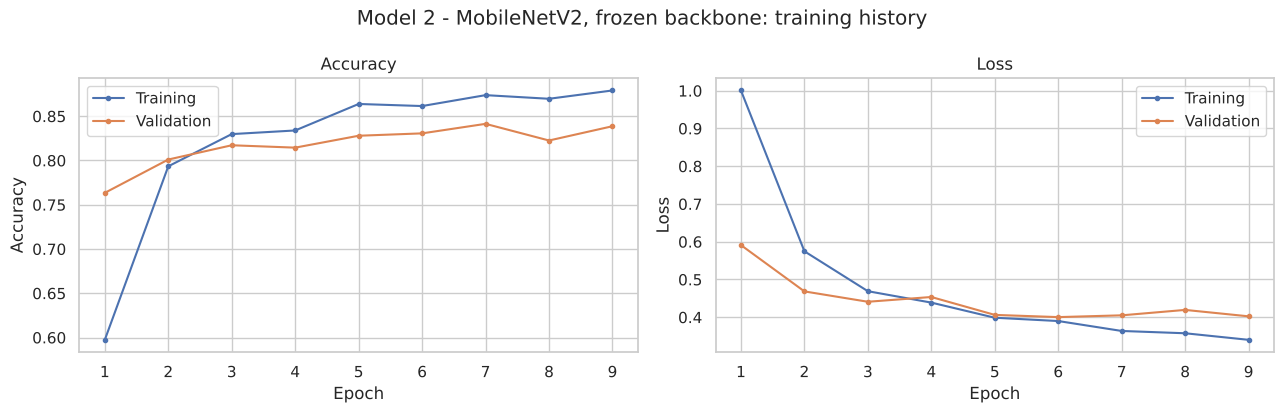

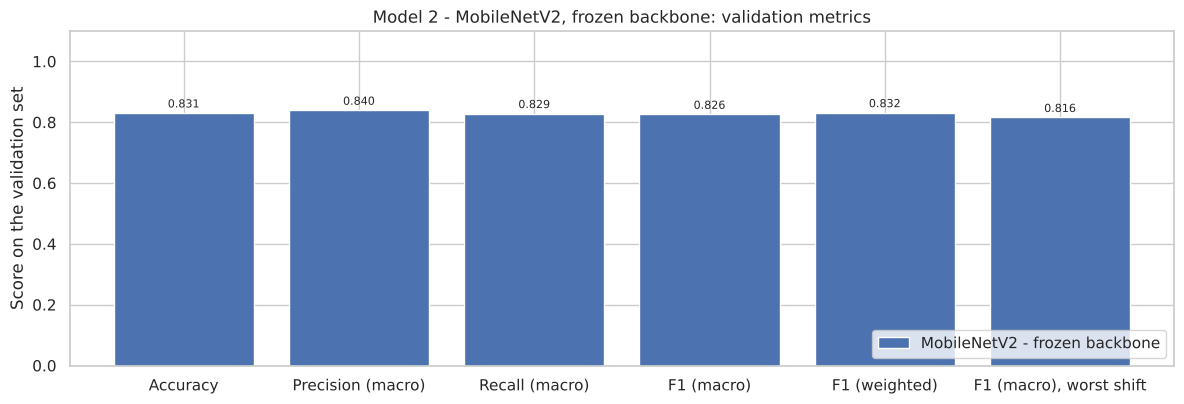

Ran **9** epoch(s) in 5.3 min; best validation loss at epoch **6** (val loss 0.400, val accuracy 0.831, training accuracy 0.862, gap +0.031). Early stopping ended training before the epoch limit. 

In [60]:
# Visualizing evaluation Metric Score chart
plot_training_history(mobilenet_head_run["history"], "Model 2 - MobileNetV2, frozen backbone: training history",
                      "22_mobilenetv2_head_history")
plot_metric_scores({"MobileNetV2 - frozen backbone": mobilenet_head_run["val_metrics"]},
                   "Model 2 - MobileNetV2, frozen backbone: validation metrics", "23_mobilenetv2_head_metrics")
show_md(describe_fit(mobilenet_head_run))

#### 2. Cross- Validation & Hyperparameter Tuning

In [61]:
# ML Model - 1 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
# (Template label kept; this cell tunes Model 2.) Stage 2: fine-tune the top backbone layers.

# Fit the Algorithm  /  Predict on the model
mobilenet_finetune_run = fine_tune("MobileNetV2", mobilenet_head_run)
EXPERIMENTS["MobileNetV2 - fine-tuned"] = mobilenet_finetune_run
print_validation(mobilenet_finetune_run["val_metrics"])

MobileNetV2: unfroze 19 layers | trainable 1,515,844 of 2,263,108
Epoch 1/12


54/54 - 36s - 667ms/step - accuracy: 0.8163 - loss: 0.4882 - val_accuracy: 0.8065 - val_loss: 0.5082 - learning_rate: 1.0000e-04


Epoch 2/12


54/54 - 41s - 766ms/step - accuracy: 0.9114 - loss: 0.2526 - val_accuracy: 0.8441 - val_loss: 0.4157 - learning_rate: 1.0000e-04


Epoch 3/12


54/54 - 33s - 612ms/step - accuracy: 0.9249 - loss: 0.2083 - val_accuracy: 0.8871 - val_loss: 0.3167 - learning_rate: 1.0000e-04


... (18 outputs left out)

Epoch 12/12


54/54 - 31s - 583ms/step - accuracy: 0.9918 - loss: 0.0271 - val_accuracy: 0.9032 - val_loss: 0.3288 - learning_rate: 2.5000e-05


Restoring model weights from the end of the best epoch: 11.


{'accuracy': 0.9167, 'precision_macro': 0.9168, 'recall_macro': 0.9231, 'f1_macro': 0.9184, 'f1_weighted': 0.9165, 'roc_auc_ovr': 0.993, 'f1_macro_robust': 0.9184}
Macro-F1 by shift: {'Original': 0.918, 'Brightness +10%': 0.934, 'Brightness -10%': 0.927, 'Contrast -20%': 0.931, 'Contrast +20%': 0.921}


##### Which hyperparameter optimization technique have you used and why?

For the pretrained models the tuning experiment is **fine-tuning depth**: a frozen backbone (baseline) against a backbone whose top layers are unfrozen (tuned), compared on the validation set. As with Model 1, a grid or random search with cross-validation is not practical on a CPU.

**Stage 2 - fine-tuning.** The last 30 backbone layers are unfrozen and training continues.

* **Why fine-tune?** ImageNet contains photographs of everyday objects. The early layers' edge and texture detectors transfer well to MRI, but the last layers are specialised for things like animal and vehicle parts. Letting them adapt can produce features that fit brain anatomy better.
* **Why only the top layers?** The lower layers hold the most general features and the dataset is too small to retrain millions of parameters safely.
* **Why a smaller learning rate?** Stage 2 uses a learning rate ten times lower than stage 1. The pretrained weights are already good; large steps would overwrite them ("catastrophic forgetting"). Small steps adjust them gently.
* **How is overfitting controlled?** Batch-normalisation layers stay frozen, augmentation and dropout remain on, early stopping watches validation loss, and - as a final safeguard - if fine-tuning does not improve the selection score, the stage-1 weights are restored and used instead.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

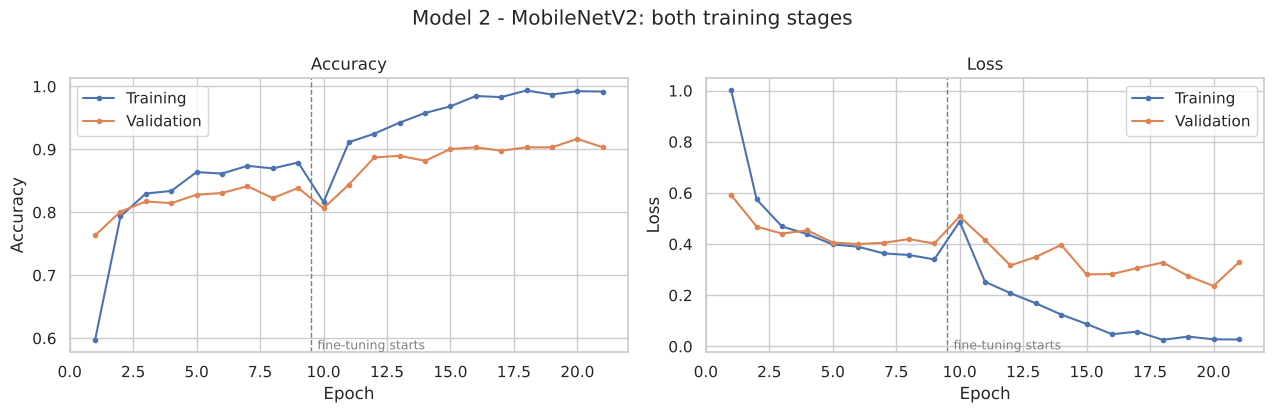

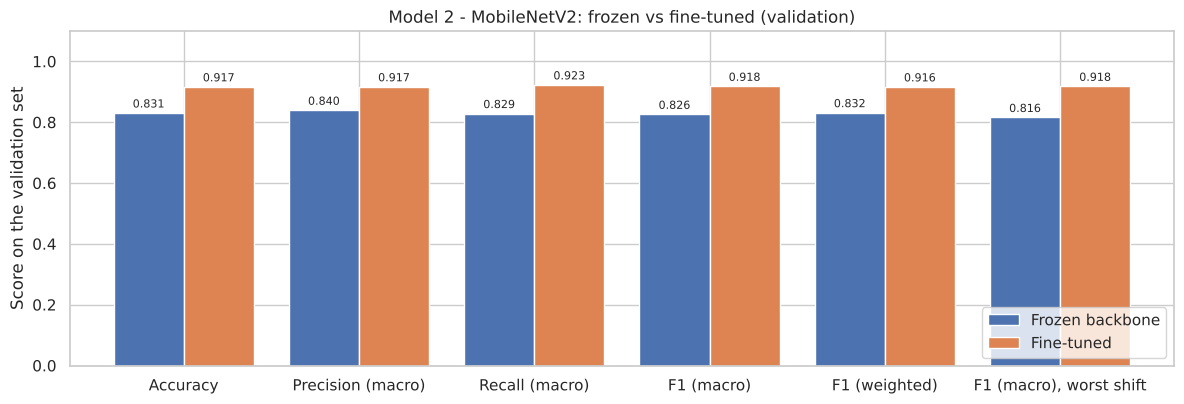

Ran **12** epoch(s) in 7.2 min; best validation loss at epoch **11** (val loss 0.236, val accuracy 0.917, training accuracy 0.992, gap +0.076). Training used the full epoch budget. On unmodified validation images the tuned configuration **improved** macro-F1: 0.826 -> 0.918 (+9.2 percentage points; accuracy +8.6 pp, macro recall +9.4 pp). On the selection score (worst-case macro-F1 under intensity shifts) it **improved** the result: 0.816 (worst at 'Contrast -20%') -> 0.918 (worst at 'Original'), +10.2 pp. **Configuration kept: fine-tuned.**

In [62]:
mobilenet_summary = finalise_transfer_model("MobileNetV2", mobilenet_head_run, mobilenet_finetune_run)
plot_training_history(FINAL["MobileNetV2"]["history"], "Model 2 - MobileNetV2: both training stages",
                      "24_mobilenetv2_full_history", stage_boundary=FINAL["MobileNetV2"]["stage_boundary"])
plot_metric_scores({"Frozen backbone": mobilenet_head_run["val_metrics"], "Fine-tuned": mobilenet_finetune_run["val_metrics"]},
                   "Model 2 - MobileNetV2: frozen vs fine-tuned (validation)", "25_mobilenetv2_frozen_vs_finetuned")
show_md(mobilenet_summary)

The computed sentence above reports the change in validation metrics from fine-tuning and which stage was kept. The combined history chart shows both stages on one axis; the dashed line marks where the backbone layers were unfrozen.

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

| Metric | What it measures | What it means in a clinical workflow |
|---|---|---|
| **Accuracy** | Share of all images classified correctly | Easy to communicate, but it can hide poor performance on a smaller class. |
| **Precision** (per class) | Of the images predicted as class X, how many really are X | Low precision means **false alarms**: unnecessary follow-up scans, cost and patient anxiety. |
| **Recall / sensitivity** (per class) | Of the images that really are X, how many were found | Low recall means **missed cases**. For tumor classes this is the most serious error, because a missed tumor can delay treatment. |
| **F1-score** | Harmonic mean of precision and recall | A single figure that is only high when both false alarms and misses are low. |
| **Macro F1** | Unweighted average of per-class F1 | Treats every tumor type as equally important regardless of how many images it has. **This is the selection metric in this project.** |
| **Weighted F1** | Per-class F1 weighted by class size | Closer to overall accuracy; useful to compare against macro F1 - a large gap signals a weak small class. |
| **Confusion matrix** | Counts of every actual / predicted combination | Shows *which* classes are confused, e.g. whether tumors are mistaken for "no tumor", which matters more than confusion between two tumor types. |
| **ROC-AUC (one-vs-rest)** | How well the predicted probabilities rank each class against the rest | Independent of any decision threshold; indicates whether confidence scores are informative. |

**Potential impact of the model (not a demonstrated outcome):** a model with high recall on tumor classes could help prioritise a reading queue; one with high precision would avoid flooding radiologists with false alarms. Neither benefit has been measured here - doing so would need a prospective study in a real workflow.

### ML Model - 3 : EfficientNetB0 (transfer learning)

In [63]:
# ML Model - 3 Implementation

# Fit the Algorithm  /  Predict on the model
efficientnet_head_run = train_frozen_head("EfficientNetB0")
EXPERIMENTS["EfficientNetB0 - frozen backbone"] = efficientnet_head_run
print_validation(efficientnet_head_run["val_metrics"])

EfficientNetB0: 237 backbone layers | trainable 5,124 | non-trainable 4,049,571 | total 4,054,695
Epoch 1/10


54/54 - 46s - 844ms/step - accuracy: 0.5792 - loss: 1.0235 - val_accuracy: 0.7070 - val_loss: 0.7186 - learning_rate: 0.0010


Epoch 2/10


54/54 - 37s - 682ms/step - accuracy: 0.7653 - loss: 0.6559 - val_accuracy: 0.7554 - val_loss: 0.6384 - learning_rate: 0.0010


Epoch 3/10


54/54 - 37s - 682ms/step - accuracy: 0.8104 - loss: 0.5592 - val_accuracy: 0.7634 - val_loss: 0.5760 - learning_rate: 0.0010


... (15 outputs left out)

54/54 - 37s - 685ms/step - accuracy: 0.8556 - loss: 0.4202 - val_accuracy: 0.7984 - val_loss: 0.4967 - learning_rate: 1.2500e-04


Epoch 9: early stopping


Restoring model weights from the end of the best epoch: 6.


{'accuracy': 0.8172, 'precision_macro': 0.8129, 'recall_macro': 0.8173, 'f1_macro': 0.8055, 'f1_weighted': 0.8147, 'roc_auc_ovr': 0.9705, 'f1_macro_robust': 0.7873}
Macro-F1 by shift: {'Original': 0.805, 'Brightness +10%': 0.787, 'Brightness -10%': 0.814, 'Contrast -20%': 0.813, 'Contrast +20%': 0.841}


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

**EfficientNetB0** is the smallest member of the EfficientNet family. Its architecture was found by neural architecture search and uses *MBConv* blocks (the inverted residual blocks of MobileNetV2) with added *squeeze-and-excitation* attention, which lets the network re-weight its channels according to the image content. The family is known for a good accuracy-to-size ratio through *compound scaling* of depth, width and resolution. It has about four million parameters in its feature extractor - larger than MobileNetV2, far smaller than ResNet50.

It is trained with exactly the same two-stage procedure, head, data pipeline and seed as MobileNetV2, so the comparison between the two is fair. The only differences are the backbone and its input scaling, which is handled inside the model.

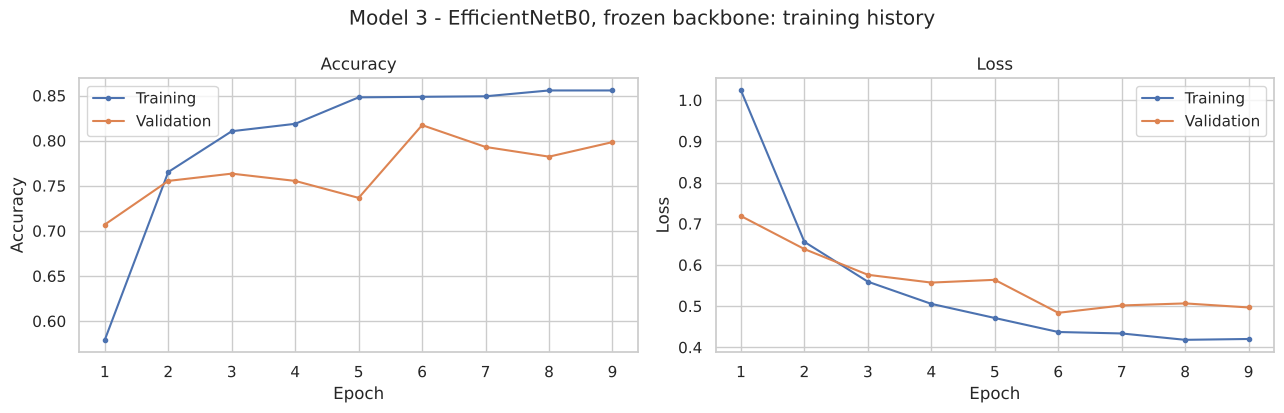

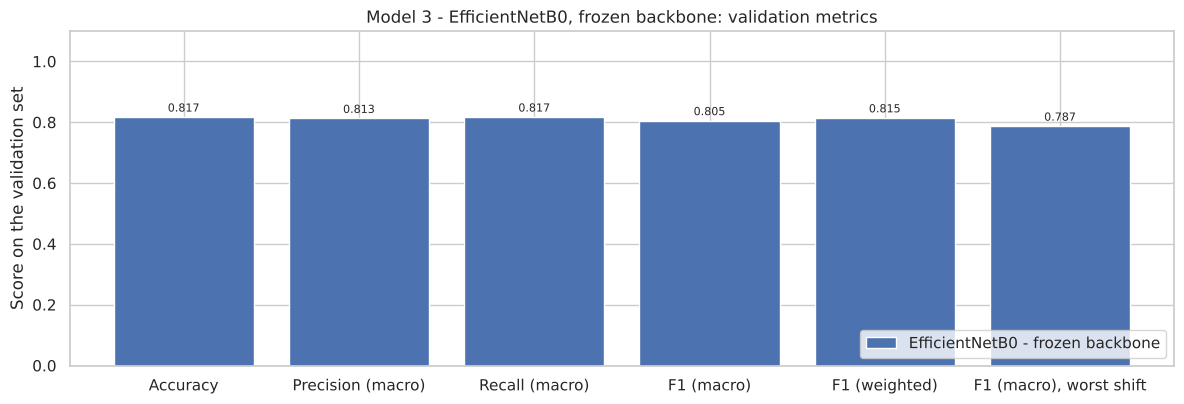

Ran **9** epoch(s) in 5.8 min; best validation loss at epoch **6** (val loss 0.484, val accuracy 0.817, training accuracy 0.849, gap +0.031). Early stopping ended training before the epoch limit. 

In [64]:
# Visualizing evaluation Metric Score chart
plot_training_history(efficientnet_head_run["history"], "Model 3 - EfficientNetB0, frozen backbone: training history",
                      "26_efficientnetb0_head_history")
plot_metric_scores({"EfficientNetB0 - frozen backbone": efficientnet_head_run["val_metrics"]},
                   "Model 3 - EfficientNetB0, frozen backbone: validation metrics", "27_efficientnetb0_head_metrics")
show_md(describe_fit(efficientnet_head_run))

#### 2. Cross- Validation & Hyperparameter Tuning

In [65]:
# ML Model - 3 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)

# Fit the Algorithm  /  Predict on the model
efficientnet_finetune_run = fine_tune("EfficientNetB0", efficientnet_head_run)
EXPERIMENTS["EfficientNetB0 - fine-tuned"] = efficientnet_finetune_run
print_validation(efficientnet_finetune_run["val_metrics"])

EfficientNetB0: unfroze 32 layers | trainable 2,042,644 of 4,054,695
Epoch 1/12


54/54 - 58s - 1s/step - accuracy: 0.8545 - loss: 0.4171 - val_accuracy: 0.8548 - val_loss: 0.4108 - learning_rate: 1.0000e-04


Epoch 2/12


54/54 - 75s - 1s/step - accuracy: 0.8961 - loss: 0.3011 - val_accuracy: 0.8495 - val_loss: 0.3850 - learning_rate: 1.0000e-04


Epoch 3/12


54/54 - 82s - 2s/step - accuracy: 0.9014 - loss: 0.2674 - val_accuracy: 0.8683 - val_loss: 0.3858 - learning_rate: 1.0000e-04


... (18 outputs left out)

Epoch 12/12


54/54 - 48s - 891ms/step - accuracy: 0.9724 - loss: 0.0799 - val_accuracy: 0.9247 - val_loss: 0.2167 - learning_rate: 2.5000e-05


Restoring model weights from the end of the best epoch: 9.


{'accuracy': 0.922, 'precision_macro': 0.9193, 'recall_macro': 0.9282, 'f1_macro': 0.9225, 'f1_weighted': 0.9217, 'roc_auc_ovr': 0.9937, 'f1_macro_robust': 0.9225}
Macro-F1 by shift: {'Original': 0.922, 'Brightness +10%': 0.935, 'Brightness -10%': 0.942, 'Contrast -20%': 0.933, 'Contrast +20%': 0.931}


##### Which hyperparameter optimization technique have you used and why?

The same controlled experiment as for Model 2: **frozen backbone versus fine-tuned top layers**, judged on the validation set, for the same cost reasons. For EfficientNetB0 the last 40 layers are unfrozen (it is a deeper network than MobileNetV2, so a similar proportion of its top blocks is covered), with batch-normalisation layers kept frozen and the same reduced learning rate.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

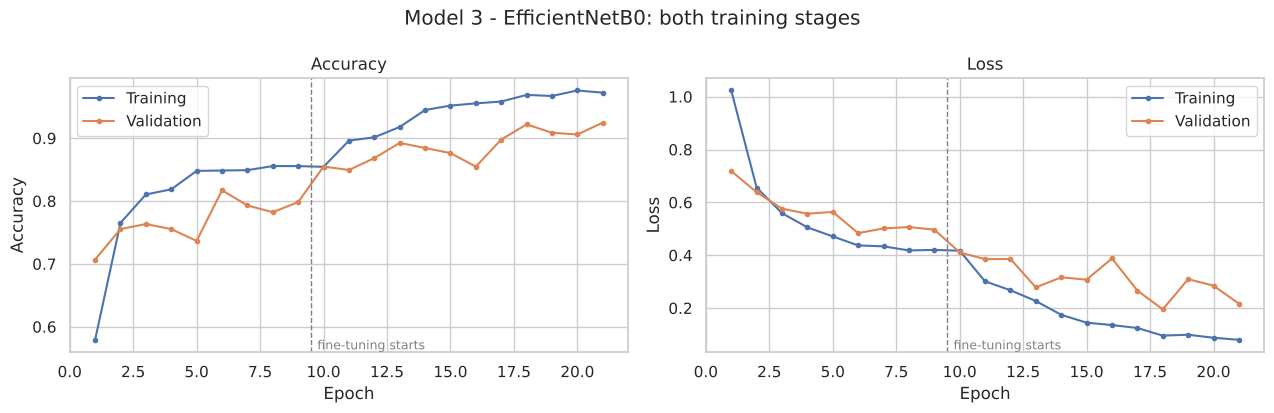

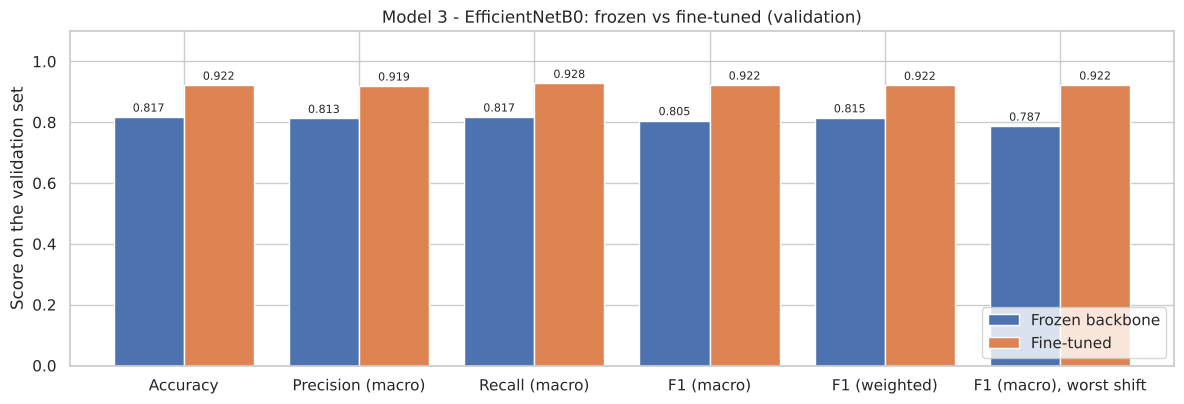

Ran **12** epoch(s) in 12.2 min; best validation loss at epoch **9** (val loss 0.195, val accuracy 0.922, training accuracy 0.969, gap +0.047). Training used the full epoch budget. On unmodified validation images the tuned configuration **improved** macro-F1: 0.805 -> 0.922 (+11.7 percentage points; accuracy +10.5 pp, macro recall +11.1 pp). On the selection score (worst-case macro-F1 under intensity shifts) it **improved** the result: 0.787 (worst at 'Brightness +10%') -> 0.922 (worst at 'Original'), +13.5 pp. **Configuration kept: fine-tuned.**

In [66]:
efficientnet_summary = finalise_transfer_model("EfficientNetB0", efficientnet_head_run, efficientnet_finetune_run)
plot_training_history(FINAL["EfficientNetB0"]["history"], "Model 3 - EfficientNetB0: both training stages",
                      "28_efficientnetb0_full_history", stage_boundary=FINAL["EfficientNetB0"]["stage_boundary"])
plot_metric_scores({"Frozen backbone": efficientnet_head_run["val_metrics"],
                    "Fine-tuned": efficientnet_finetune_run["val_metrics"]},
                   "Model 3 - EfficientNetB0: frozen vs fine-tuned (validation)", "29_efficientnetb0_frozen_vs_finetuned")
show_md(efficientnet_summary)

The computed sentence above gives the measured effect of fine-tuning on EfficientNetB0 and the stage that was kept.

### 7.4 Final evaluation on the held-out test set

All tuning decisions are now fixed. Each of the three final models is evaluated **once** on the test set, which has not been used for training, early stopping, tuning or selection.

In [67]:
def measure_latency_ms(model: keras.Model, images: np.ndarray, repeats: int = 30) -> float:
    """Median time for one forward pass on a single image, in milliseconds."""
    model(scale_pixels(images[:1]), training=False)   # warm-up: the first call builds the graph
    timings = []
    for position in range(min(repeats, len(images))):
        batch = scale_pixels(images[position:position + 1])
        started = time.perf_counter()
        model(batch, training=False)
        timings.append(time.perf_counter() - started)
    return float(np.median(timings) * 1000)


def save_h5(model: keras.Model, path: Path) -> None:
    """Save an inference-only model in HDF5 format.

    Keras logs a notice that HDF5 is a legacy format every time it is used. The
    format is required by the project brief, so that one notice is silenced here;
    the selected model is also saved in the native .keras format in section 8.
    """
    previous_verbosity = absl_logging.get_verbosity()
    absl_logging.set_verbosity(absl_logging.ERROR)
    try:
        model.save(path, include_optimizer=False)
    finally:
        absl_logging.set_verbosity(previous_verbosity)


for name, entry in FINAL.items():
    entry["test_probabilities"] = predict_probabilities(entry["model"], X_test)
    entry["test_predictions"] = entry["test_probabilities"].argmax(axis=1)
    entry["test_metrics"] = compute_metrics(y_test, entry["test_probabilities"])
    entry["parameters"] = count_parameters(entry["model"])["total"]
    entry["latency_ms"] = measure_latency_ms(entry["model"], X_test)
    # Save every trained model in the .h5 format requested in the project brief.
    entry["h5_path"] = MODELS_DIR / f"{entry['file_stem']}.h5"
    save_h5(entry["model"], entry["h5_path"])
    entry["size_mb"] = entry["h5_path"].stat().st_size / 1e6
    print(f"\n{'=' * 22} {name} ({entry['variant']}) - test set {'=' * 22}")
    print(classification_report(y_test, entry["test_predictions"], labels=np.arange(NUM_CLASSES),
                                target_names=DISPLAY_NAMES, digits=3, zero_division=0))


====================== Custom CNN (tuned) - test set ======================
              precision    recall  f1-score   support

      Glioma      0.907     0.884     0.895       121
  Meningioma      0.815     0.537     0.647        82
    No Tumor      0.716     0.863     0.783        73
   Pituitary      0.804     0.945     0.869        91

    accuracy                          0.817       367
   macro avg      0.810     0.807     0.798       367
weighted avg      0.823     0.817     0.811       367




====================== MobileNetV2 (fine-tuned) - test set ======================
              precision    recall  f1-score   support

      Glioma      0.982     0.917     0.949       121
  Meningioma      0.860     0.902     0.881        82
    No Tumor      1.000     0.959     0.979        73
   Pituitary      0.918     0.989     0.952        91

    accuracy                          0.940       367
   macro avg      0.940     0.942     0.940       367
weighted avg      0.943     0.940     0.941       367




====================== EfficientNetB0 (fine-tuned) - test set ======================
              precision    recall  f1-score   support

      Glioma      0.966     0.926     0.945       121
  Meningioma      0.878     0.793     0.833        82
    No Tumor      0.945     0.945     0.945        73
   Pituitary      0.865     0.989     0.923        91

    accuracy                          0.916       367
   macro avg      0.914     0.913     0.912       367
weighted avg      0.917     0.916     0.915       367



#### Confusion matrices

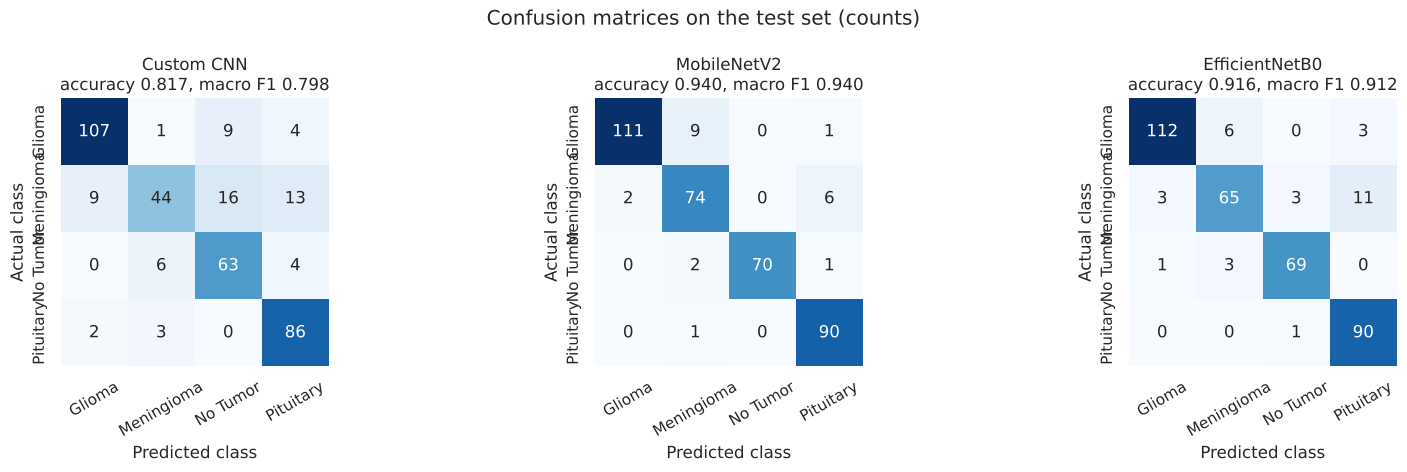

In [68]:
# Count-based confusion matrices for all three models.
fig, axes = plt.subplots(1, len(FINAL), figsize=(5.4 * len(FINAL), 4.8))
for axis, (name, entry) in zip(np.atleast_1d(axes), FINAL.items()):
    entry["confusion"] = confusion_matrix(y_test, entry["test_predictions"], labels=np.arange(NUM_CLASSES))
    sns.heatmap(entry["confusion"], annot=True, fmt="d", cmap="Blues", cbar=False, square=True,
                xticklabels=DISPLAY_NAMES, yticklabels=DISPLAY_NAMES, ax=axis)
    axis.set_title(f"{name}\naccuracy {entry['test_metrics']['accuracy']:.3f}, macro F1 {entry['test_metrics']['f1_macro']:.3f}")
    axis.set_xlabel("Predicted class")
    axis.set_ylabel("Actual class")
    axis.tick_params(axis="x", rotation=30)
fig.suptitle("Confusion matrices on the test set (counts)")
finish_figure(fig, "30_confusion_matrices")

#### Robustness and safety view

Two questions that overall accuracy does not answer: does performance hold when brightness or contrast shifts slightly, and how often is a tumor image classified as "no tumor"?

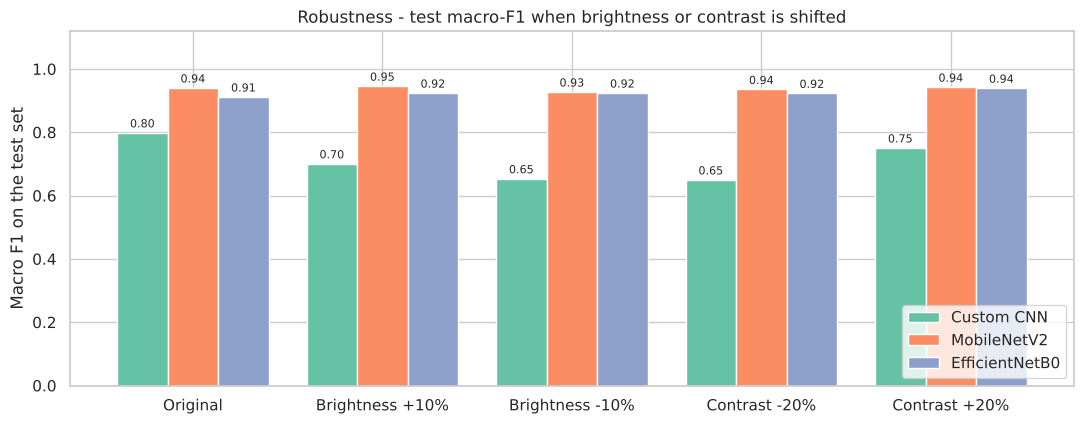

,Test macro F1 (original),Test macro F1 (worst shift),Largest drop,Tumors predicted as no tumor (of 294),No-tumor predicted as tumor (of 73)
Custom CNN,0.798,0.650,0.149,25,10
MobileNetV2,0.940,0.927,0.013,0,3
EfficientNetB0,0.912,0.912,0.000,4,4


Most stable under intensity shifts: **EfficientNetB0** (largest drop 0.0 pp). Least stable: **Custom CNN** (largest drop 14.9 pp, worst at 'Contrast -20%').

In [69]:
no_tumor_indices = [class_to_index[name] for name in no_tumor_classes]
tumor_indices = [index for index in range(NUM_CLASSES) if index not in no_tumor_indices]


def count_tumor_errors(confusion: np.ndarray) -> tuple[int, int]:
    """(tumor images predicted as no tumor, no-tumor images predicted as a tumor)."""
    if not no_tumor_indices:
        return 0, 0
    return (int(confusion[np.ix_(tumor_indices, no_tumor_indices)].sum()),
            int(confusion[np.ix_(no_tumor_indices, tumor_indices)].sum()))


tumor_total = int(np.isin(y_test, tumor_indices).sum())
healthy_total = int(np.isin(y_test, no_tumor_indices).sum())
for name, entry in FINAL.items():
    entry["test_f1_by_shift"] = macro_f1_under_shifts(entry["model"], X_test, y_test)
    entry["missed_tumors"], entry["false_alarms"] = count_tumor_errors(entry["confusion"])

robustness = pd.DataFrame({name: entry["test_f1_by_shift"] for name, entry in FINAL.items()}).T
ax = robustness.T.plot(kind="bar", figsize=(11, 4.4), width=0.8, rot=0, color=sns.color_palette("Set2", len(FINAL)))
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=8, padding=2)
ax.set_ylim(0, 1.12)
ax.set_ylabel("Macro F1 on the test set")
ax.set_title("Robustness - test macro-F1 when brightness or contrast is shifted")
ax.legend(loc="lower right")
finish_figure(ax.figure, "31_robustness_to_intensity_shifts")

safety = pd.DataFrame({
    "Test macro F1 (original)": robustness["Original"],
    "Test macro F1 (worst shift)": robustness.min(axis=1),
    "Largest drop": robustness["Original"] - robustness.min(axis=1),
    f"Tumors predicted as no tumor (of {tumor_total})": {name: entry["missed_tumors"] for name, entry in FINAL.items()},
    f"No-tumor predicted as tumor (of {healthy_total})": {name: entry["false_alarms"] for name, entry in FINAL.items()},
})
display(safety.style.format({column: "{:.3f}" for column in safety.columns[:3]}))
most_stable, least_stable = safety["Largest drop"].idxmin(), safety["Largest drop"].idxmax()
show_md(f"Most stable under intensity shifts: **{most_stable}** (largest drop {safety.loc[most_stable, 'Largest drop'] * 100:.1f} pp). "
        f"Least stable: **{least_stable}** (largest drop {safety.loc[least_stable, 'Largest drop'] * 100:.1f} pp, "
        f"worst at '{robustness.loc[least_stable].idxmin()}').")

A model whose macro-F1 falls sharply after a 10 % brightness change is relying on absolute intensity, not on anatomy. That matters in practice because brightness and contrast depend on the scanner, the sequence and the export settings. The table also separates the two directions of tumor / no-tumor error, since a missed tumor is the more serious one.

#### Model comparison

In [70]:
comparison = pd.DataFrame([{
    "Model": name,
    "Configuration kept": entry["variant"],
    "Val macro F1": entry["val_metrics"]["f1_macro"],
    "Val macro F1 (worst shift)": entry["val_metrics"]["f1_macro_robust"],
    "Test accuracy": entry["test_metrics"]["accuracy"],
    "Test precision (macro)": entry["test_metrics"]["precision_macro"],
    "Test recall (macro)": entry["test_metrics"]["recall_macro"],
    "Test macro F1": entry["test_metrics"]["f1_macro"],
    "Test weighted F1": entry["test_metrics"]["f1_weighted"],
    "Test ROC-AUC (OvR)": entry["test_metrics"]["roc_auc_ovr"],
    "Test macro F1 (worst shift)": min(entry["test_f1_by_shift"].values()),
    "Tumors missed (test)": entry["missed_tumors"],
    "Parameters": entry["parameters"],
    "Training time (min)": entry["train_seconds"] / 60,
    "Inference (ms / image)": entry["latency_ms"],
    "Model file (MB)": entry["size_mb"],
} for name, entry in FINAL.items()]).set_index("Model")

comparison.to_csv(REPORTS_DIR / "model_comparison.csv")
display(comparison.style.format({
    **{column: "{:.3f}" for column in comparison.columns if column.startswith(("Val", "Test"))},
    "Parameters": "{:,.0f}", "Training time (min)": "{:.1f}", "Inference (ms / image)": "{:.1f}", "Model file (MB)": "{:.1f}"}))
show_md(f"Timings were measured on this machine ({os.cpu_count()} CPU threads, "
        f"{len(tf.config.list_physical_devices('GPU'))} GPU) and will differ on other hardware. "
        "Training time covers the stages that produced the kept configuration.")

,Configuration kept,Val macro F1,Val macro F1 (worst shift),Test accuracy,Test precision (macro),Test recall (macro),Test macro F1,Test weighted F1,Test ROC-AUC (OvR),Test macro F1 (worst shift),Tumors missed (test),Parameters,Training time (min),Inference (ms / image),Model file (MB)
Model,,,,,,,,,,,,,,,
Custom CNN,tuned,0.822,0.645,0.817,0.810,0.807,0.798,0.811,0.952,0.650,25,"423,268",8.4,16.6,1.8
MobileNetV2,fine-tuned,0.918,0.918,0.940,0.940,0.942,0.940,0.941,0.994,0.927,0,"2,263,108",12.5,145.8,9.6
EfficientNetB0,fine-tuned,0.922,0.922,0.916,0.914,0.913,0.912,0.915,0.993,0.912,4,"4,054,695",18.1,259.5,17.0


Timings were measured on this machine (2 CPU threads, 0 GPU) and will differ on other hardware. Training time covers the stages that produced the kept configuration.

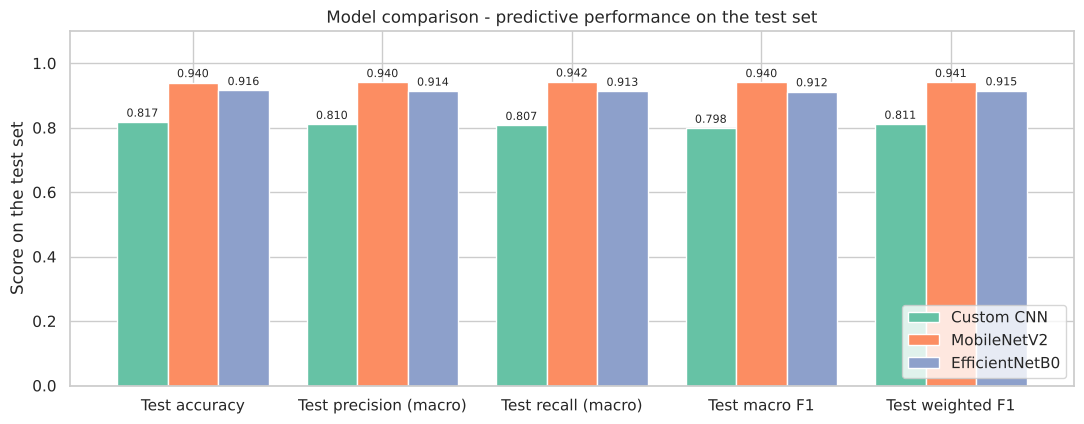

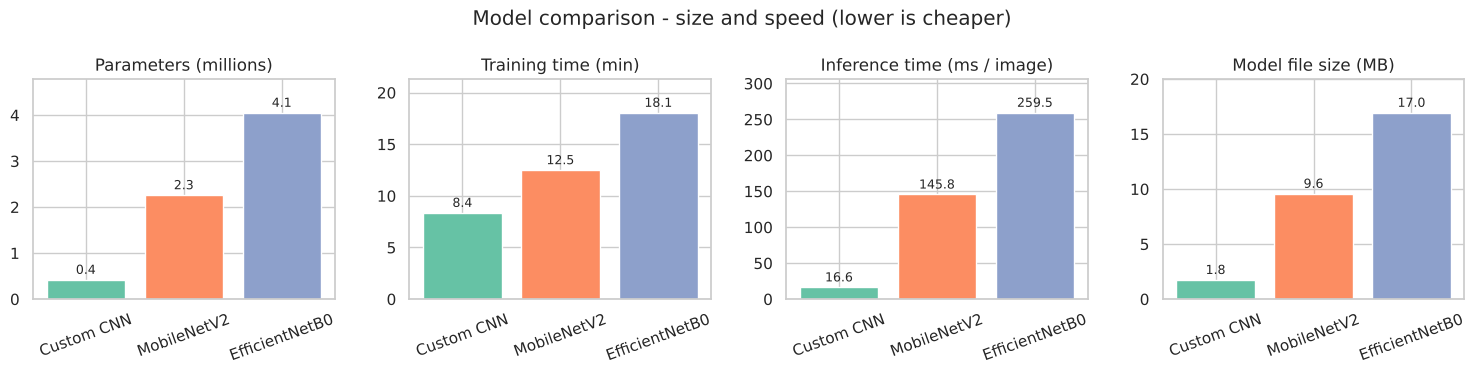

In [71]:
# Comparison charts: predictive quality and deployment cost.
model_colors = sns.color_palette("Set2", len(FINAL))
quality = comparison[["Test accuracy", "Test precision (macro)", "Test recall (macro)", "Test macro F1", "Test weighted F1"]]

ax = quality.T.plot(kind="bar", figsize=(11, 4.4), width=0.8, rot=0, color=model_colors)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=8, padding=2)
ax.set_ylim(0, 1.1)
ax.set_ylabel("Score on the test set")
ax.set_title("Model comparison - predictive performance on the test set")
ax.legend(loc="lower right")
finish_figure(ax.figure, "32_model_comparison_quality")

fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
cost_columns = [("Parameters", "Parameters (millions)", 1e-6), ("Training time (min)", "Training time (min)", 1),
                ("Inference (ms / image)", "Inference time (ms / image)", 1), ("Model file (MB)", "Model file size (MB)", 1)]
for axis, (column, title, factor) in zip(axes, cost_columns):
    values = comparison[column] * factor
    bars = axis.bar(comparison.index, values, color=model_colors)
    axis.bar_label(bars, fmt="%.1f", fontsize=9, padding=2)
    axis.set_title(title)
    axis.tick_params(axis="x", rotation=20)
    axis.set_ylim(0, values.max() * 1.18)
fig.suptitle("Model comparison - size and speed (lower is cheaper)")
finish_figure(fig, "33_model_comparison_cost")

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

**Macro F1 is the primary metric, supported by per-class recall and precision.** Accuracy alone is not sufficient: the classes are imbalanced, so a model can score well overall while performing poorly on a smaller class, and accuracy treats all errors as equal.

* **Recall (sensitivity) per class** matters most for the tumor classes. A tumor scan classified as "no tumor" is the costliest error, because it could delay care.
* **Precision per class** matters for workload and patient experience. False alarms lead to unnecessary follow-up.
* **Macro F1** combines both and gives each class equal weight, so it cannot be inflated by doing well only on the largest class. It is the basis for tuning and model selection.
* **Worst-case macro F1 under intensity shifts** is macro F1 measured again after small brightness and contrast changes, keeping the lowest value. It protects against choosing a model that depends on scan brightness. This is the selection score.
* **Weighted F1 and accuracy** are reported for completeness and for comparison with other work.
* **ROC-AUC (one-vs-rest)** is valid for multi-class problems when computed per class against the rest, and indicates whether the predicted probabilities rank cases sensibly.

Inference time, parameter count and file size are considered alongside these because the model has to run in a web application.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

In [72]:
# Selection rule - uses VALIDATION data only; the test set plays no part in the choice:
#   1. rank by the selection score (worst-case validation macro-F1 under intensity shifts);
#   2. treat models within SELECTION_TOLERANCE of the best as tied;
#   3. among tied models choose the fastest at inference, since it must serve a web app.
SELECTION_COLUMN = "Val macro F1 (worst shift)"
best_selection_score = comparison[SELECTION_COLUMN].max()
tied_models = comparison[comparison[SELECTION_COLUMN] >= best_selection_score - SELECTION_TOLERANCE]
SELECTED_NAME = tied_models["Inference (ms / image)"].idxmin()
selected = FINAL[SELECTED_NAME]
ranking = comparison[SELECTION_COLUMN].sort_values(ascending=False)
clean_ranking = comparison["Val macro F1"].sort_values(ascending=False)
highest_test_accuracy = comparison["Test accuracy"].idxmax()

show_md(f"""
**Selected model: {SELECTED_NAME} ({selected['variant']}).**

* Selection score (worst-case validation macro-F1 under intensity shifts): {', '.join(f'{name} {score:.3f}' for name, score in ranking.items())}.
* For reference, validation macro-F1 on unmodified images: {', '.join(f'{name} {score:.3f}' for name, score in clean_ranking.items())}. \
{'Both rankings put the same model first.' if ranking.index[0] == clean_ranking.index[0] else f'On unmodified images alone {clean_ranking.index[0]} would rank first; it is not selected because its score falls to {comparison.loc[clean_ranking.index[0], SELECTION_COLUMN]:.3f} when brightness or contrast shifts.'}
* Models within {SELECTION_TOLERANCE * 100:.0f} percentage point of the best: {', '.join(tied_models.index)}. \
{'Among these, the fastest at inference was chosen.' if len(tied_models) > 1 else 'No other model was close enough to be considered tied.'}
* {SELECTED_NAME} on the **test set**: accuracy {selected['test_metrics']['accuracy']:.3f}, macro precision \
{selected['test_metrics']['precision_macro']:.3f}, macro recall {selected['test_metrics']['recall_macro']:.3f}, \
macro F1 {selected['test_metrics']['f1_macro']:.3f}, weighted F1 {selected['test_metrics']['f1_weighted']:.3f}; \
worst-case test macro F1 under shifts {min(selected['test_f1_by_shift'].values()):.3f}; \
{selected['missed_tumors']} of {tumor_total} tumor images predicted as no tumor.
* Cost: {selected['parameters']:,} parameters, {selected['size_mb']:.1f} MB on disk, about \
{selected['latency_ms']:.0f} ms per image on this machine.
* The model with the highest test accuracy is {highest_test_accuracy}; \
{'this agrees with the selection.' if highest_test_accuracy == SELECTED_NAME else 'the selection differs because it was made on validation data and takes robustness and inference cost into account.'}
""")


**Selected model: MobileNetV2 (fine-tuned).**

* Selection score (worst-case validation macro-F1 under intensity shifts): EfficientNetB0 0.922, MobileNetV2 0.918, Custom CNN 0.645.
* For reference, validation macro-F1 on unmodified images: EfficientNetB0 0.922, MobileNetV2 0.918, Custom CNN 0.822. Both rankings put the same model first.
* Models within 1 percentage point of the best: MobileNetV2, EfficientNetB0. Among these, the fastest at inference was chosen.
* MobileNetV2 on the **test set**: accuracy 0.940, macro precision 0.940, macro recall 0.942, macro F1 0.940, weighted F1 0.941; worst-case test macro F1 under shifts 0.927; 0 of 294 tumor images predicted as no tumor.
* Cost: 2,263,108 parameters, 9.6 MB on disk, about 146 ms per image on this machine.
* The model with the highest test accuracy is MobileNetV2; this agrees with the selection.


**Why this rule.** The final model is not simply the one with the highest accuracy. It is chosen on **validation** data, so the test result remains an unbiased estimate; choosing on the test set would make the reported score optimistic. The score is the **worst case under mild intensity shifts** because a deployed model will meet images whose brightness and contrast differ from the training data, and the EDA showed that these properties are entangled with the class label here. Models that are effectively tied are separated by **inference speed**, because the model must respond interactively in the Streamlit app and a smaller, faster model is cheaper to host.

**How this rule came about.** An earlier version of this notebook selected on validation macro-F1 of unmodified images only. That version chose a custom CNN trained without augmentation, which had the best validation score - and whose macro-F1 collapsed when image brightness was raised by 10 %. The robustness test was then made part of the selection score. The change was motivated by validation behaviour, not by test results, but it was made after a first full run and is disclosed here for transparency.

**Custom CNN versus pretrained models.** The comparison table shows how the from-scratch network compares with the pretrained ones. Pretrained models start from features learned on over a million images, which usually helps on small datasets; the custom CNN has to learn everything from fewer than two thousand images but is by far the smallest and fastest. The measured values above show how that trade-off turned out in this run.

#### Detailed evaluation of the selected model

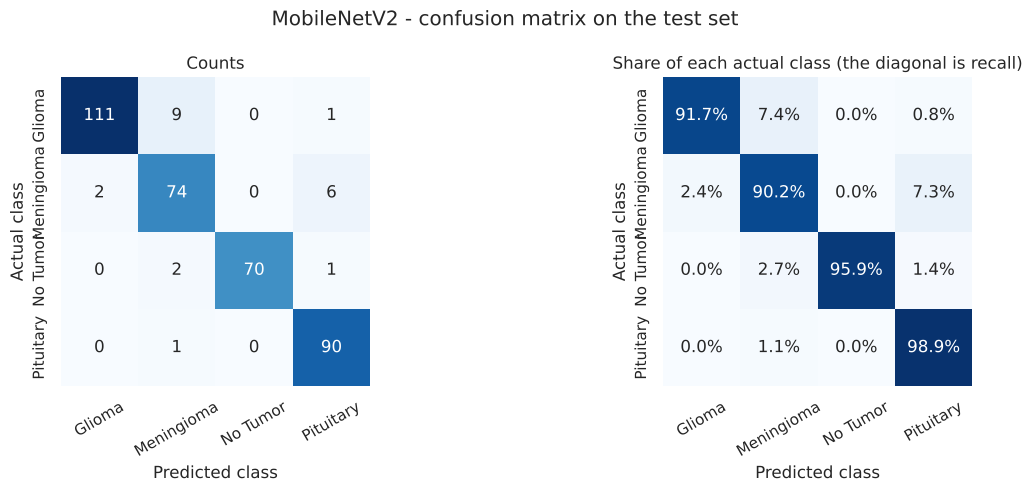


* **Strongest class (F1):** No Tumor (0.979). **Weakest class (F1):** Meningioma (0.881).
* **Most frequent confusion:** actual **Glioma** predicted as **Meningioma** (9 of 121 test images of that class).
* **Tumor images predicted as no tumor (missed tumors):** 0 of 294. **No-tumor images predicted as a tumor (false alarms):** 3 of 73.
* Total test errors: 22 of 367.


In [73]:
# Count and row-normalised confusion matrix of the selected model.
selected_confusion = selected["confusion"]
row_totals = selected_confusion.sum(axis=1, keepdims=True)
normalised_confusion = np.divide(selected_confusion, row_totals, out=np.zeros(selected_confusion.shape), where=row_totals > 0)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5))
sns.heatmap(selected_confusion, annot=True, fmt="d", cmap="Blues", cbar=False, square=True,
            xticklabels=DISPLAY_NAMES, yticklabels=DISPLAY_NAMES, ax=axes[0])
axes[0].set_title("Counts")
sns.heatmap(normalised_confusion, annot=True, fmt=".1%", cmap="Blues", cbar=False, square=True, vmin=0, vmax=1,
            xticklabels=DISPLAY_NAMES, yticklabels=DISPLAY_NAMES, ax=axes[1])
axes[1].set_title("Share of each actual class (the diagonal is recall)")
for axis in axes:
    axis.set_xlabel("Predicted class")
    axis.set_ylabel("Actual class")
    axis.tick_params(axis="x", rotation=30)
fig.suptitle(f"{SELECTED_NAME} - confusion matrix on the test set")
finish_figure(fig, "34_selected_confusion_matrix")

precision_pc, recall_pc, f1_pc, support_pc = precision_recall_fscore_support(
    y_test, selected["test_predictions"], labels=np.arange(NUM_CLASSES), zero_division=0)
per_class = pd.DataFrame({"Precision": precision_pc, "Recall": recall_pc, "F1-score": f1_pc, "Test images": support_pc},
                         index=DISPLAY_NAMES)

off_diagonal = selected_confusion.astype(float).copy()
np.fill_diagonal(off_diagonal, -1)
worst_actual, worst_predicted = np.unravel_index(off_diagonal.argmax(), off_diagonal.shape)
missed_tumors, false_alarms = selected["missed_tumors"], selected["false_alarms"]

show_md(f"""
* **Strongest class (F1):** {per_class['F1-score'].idxmax()} ({per_class['F1-score'].max():.3f}). \
**Weakest class (F1):** {per_class['F1-score'].idxmin()} ({per_class['F1-score'].min():.3f}).
* **Most frequent confusion:** actual **{DISPLAY_NAMES[worst_actual]}** predicted as **{DISPLAY_NAMES[worst_predicted]}** \
({int(selected_confusion[worst_actual, worst_predicted])} of {int(row_totals[worst_actual, 0])} test images of that class).
* **Tumor images predicted as no tumor (missed tumors):** {missed_tumors} of {tumor_total}. \
**No-tumor images predicted as a tumor (false alarms):** {false_alarms} of {healthy_total}.
* Total test errors: {int(selected_confusion.sum() - np.trace(selected_confusion))} of {int(selected_confusion.sum())}.
""")

**Reading the confusion matrix.** Each row is an actual class and each column a predicted class; the diagonal holds correct predictions. The computed summary names the strongest and weakest classes and the most common confusion in this run.

Two kinds of error deserve different attention. A confusion **between two tumor types** still flags the scan as abnormal, so it would still reach a specialist. A **tumor predicted as "no tumor"** is the more serious failure, and its count is reported separately above. The confusion matrix shows *that* two classes are confused, not *why*. No anatomical explanation is offered here, because the data cannot support one: with the acquisition differences found in the EDA, a confusion may reflect similar scan appearance as much as similar pathology.

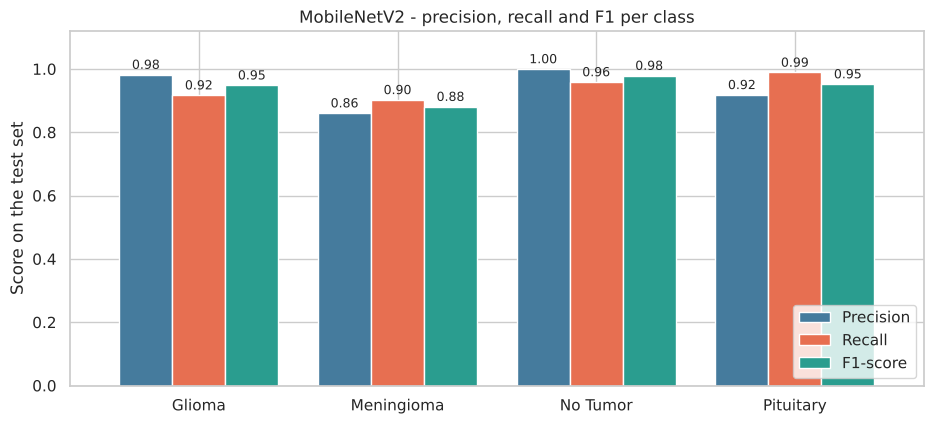

,Precision,Recall,F1-score,Test images
Glioma,0.982,0.917,0.949,121
Meningioma,0.860,0.902,0.881,82
No Tumor,1.000,0.959,0.979,73
Pituitary,0.918,0.989,0.952,91


In [74]:
# Per-class precision, recall and F1 of the selected model.
ax = per_class[["Precision", "Recall", "F1-score"]].plot(kind="bar", figsize=(9.5, 4.4), width=0.8, rot=0,
                                                         color=["#457b9d", "#e76f51", "#2a9d8f"])
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=9, padding=2)
ax.set_ylim(0, 1.12)
ax.set_ylabel("Score on the test set")
ax.set_title(f"{SELECTED_NAME} - precision, recall and F1 per class")
ax.legend(loc="lower right")
finish_figure(ax.figure, "35_selected_per_class_metrics")
display(per_class.style.format({"Precision": "{:.3f}", "Recall": "{:.3f}", "F1-score": "{:.3f}"}))

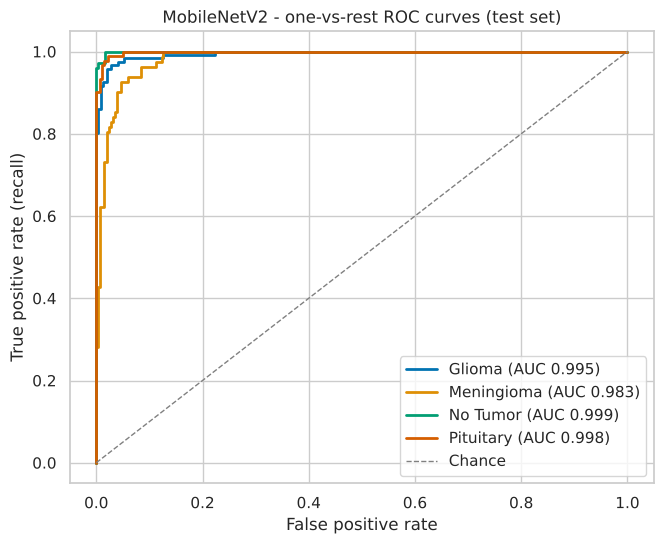

In [75]:
# One-vs-rest ROC curves of the selected model.
y_test_binarised = label_binarize(y_test, classes=np.arange(NUM_CLASSES))
fig, ax = plt.subplots(figsize=(6.8, 5.6))
for index, display_name in enumerate(DISPLAY_NAMES):
    if y_test_binarised[:, index].sum() == 0:
        continue   # a class absent from the test subset has no ROC curve
    false_positive_rate, true_positive_rate, _ = roc_curve(y_test_binarised[:, index], selected["test_probabilities"][:, index])
    ax.plot(false_positive_rate, true_positive_rate, color=PALETTE[display_name], linewidth=2,
            label=f"{display_name} (AUC {auc(false_positive_rate, true_positive_rate):.3f})")
ax.plot([0, 1], [0, 1], color="gray", linestyle="--", linewidth=1, label="Chance")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate (recall)")
ax.set_title(f"{SELECTED_NAME} - one-vs-rest ROC curves (test set)")
ax.legend(loc="lower right")
finish_figure(fig, "36_selected_roc_curves")

The one-vs-rest ROC curve of a class shows how well its predicted probability separates that class from all others across every possible threshold. An area under the curve (AUC) of 1.0 is perfect ranking and 0.5 is chance. ROC-AUC is mathematically valid here because each curve is a proper binary problem (one class against the rest).

### 7.5 Error analysis

MobileNetV2: 22 misclassified of 367 test images (6.0%)


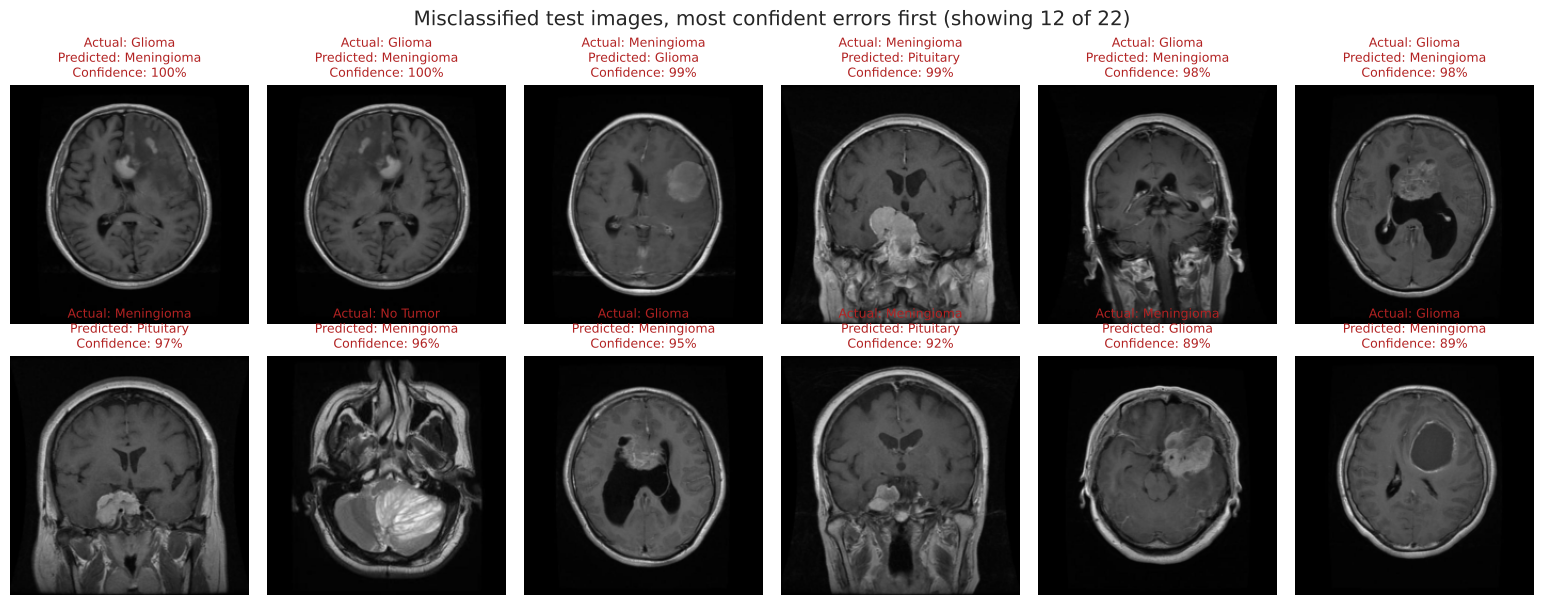

In [76]:
test_frame = df.loc[split_indices["test"]].reset_index(drop=True)
test_frame["actual"] = [DISPLAY_NAMES[index] for index in y_test]
test_frame["predicted"] = [DISPLAY_NAMES[index] for index in selected["test_predictions"]]
test_frame["confidence"] = selected["test_probabilities"].max(axis=1)
test_frame["correct"] = test_frame["actual"] == test_frame["predicted"]

errors = test_frame[~test_frame["correct"]].sort_values("confidence", ascending=False)
print(f"{SELECTED_NAME}: {len(errors)} misclassified of {len(test_frame)} test images "
      f"({len(errors) / len(test_frame):.1%})")

if len(errors):
    MAX_ERRORS_SHOWN = 12
    shown = errors.head(MAX_ERRORS_SHOWN)
    columns = 6
    rows = int(np.ceil(len(shown) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(2.6 * columns, 3.1 * rows), squeeze=False)
    for axis in axes.ravel():
        axis.axis("off")
    for axis, (position, row) in zip(axes.ravel(), shown.iterrows()):
        axis.imshow(X_test[position])
        axis.set_title(f"Actual: {row['actual']}\nPredicted: {row['predicted']}\nConfidence: {row['confidence']:.0%}",
                       fontsize=9, color="#b22222")
    fig.suptitle(f"Misclassified test images, most confident errors first (showing {len(shown)} of {len(errors)})")
    finish_figure(fig, "37_misclassified_examples")
else:
    show_md("The selected model made no errors on the test set, so there are no misclassified images to display.")

In [77]:
# Data-driven look for failure patterns.
if len(errors):
    confusion_pairs = (errors.groupby(["actual", "predicted"]).size().sort_values(ascending=False)
                       .rename("errors").reset_index())
    display(confusion_pairs)
    feature_comparison = test_frame.groupby("correct")[["brightness", "contrast", "foreground_frac"]].median()
    feature_comparison.index = feature_comparison.index.map({True: "Correct", False: "Misclassified"})
    display(feature_comparison.round(3))
    outlier_rate_errors = errors["is_statistical_outlier"].mean()
    outlier_rate_all = test_frame["is_statistical_outlier"].mean()
    low_confidence_errors = (errors["confidence"] < LOW_CONFIDENCE_THRESHOLD).mean()
    show_md(f"""
* The most common error type accounts for **{confusion_pairs['errors'].iloc[0]} of {len(errors)}** errors \
({confusion_pairs['actual'].iloc[0]} -> {confusion_pairs['predicted'].iloc[0]}).
* **{low_confidence_errors:.0%}** of the errors were made with confidence below {LOW_CONFIDENCE_THRESHOLD:.0%}; \
the remaining {1 - low_confidence_errors:.0%} were confident mistakes.
* Images flagged as statistical outliers in section 6.2 make up **{outlier_rate_errors:.0%}** of the errors, \
compared with **{outlier_rate_all:.0%}** of the whole test set.
* Median error confidence: **{errors['confidence'].median():.0%}**; median confidence on correct predictions: \
**{test_frame.loc[test_frame['correct'], 'confidence'].median():.0%}**.
""")

,actual,predicted,errors
0,Glioma,Meningioma,9
1,Meningioma,Pituitary,6
2,Meningioma,Glioma,2
3,No Tumor,Meningioma,2
4,Glioma,Pituitary,1
5,No Tumor,Pituitary,1
6,Pituitary,Meningioma,1


,brightness,contrast,foreground_frac
correct,,,
Misclassified,0.131,0.164,0.424
Correct,0.159,0.162,0.469



* The most common error type accounts for **9 of 22** errors (Glioma -> Meningioma).
* **27%** of the errors were made with confidence below 70%; the remaining 73% were confident mistakes.
* Images flagged as statistical outliers in section 6.2 make up **5%** of the errors, compared with **10%** of the whole test set.
* Median error confidence: **89%**; median confidence on correct predictions: **100%**.


**Interpreting the errors.** The grid shows the misclassified test images with the actual class, the predicted class and the model's confidence. The tables quantify the patterns:

* **Class confusion** - which pairs of classes account for the errors.
* **Low-confidence versus confident errors** - errors made with low confidence can be caught by a review threshold; confident errors cannot, and are the more dangerous kind.
* **Unusual images** - whether errors are concentrated among images with atypical brightness, contrast or framing. If the outlier share among errors is clearly higher than in the test set overall, the model is less reliable on unusual scans.
* **Preprocessing effects** - images are reduced from 640 to 224 pixels per side, so very small lesions may lose detail. This is a possible contributor that this analysis cannot confirm or rule out.

**Limits of this analysis.** The number of errors is small, so these patterns are indications, not statistically firm conclusions. The dataset has no information on lesion size, scanner or patient, so the causes of individual errors cannot be established, and no medical explanation is claimed.

### 7.6 Confidence analysis

,filename,actual,predicted,confidence,correct
0,Tr-gl_0016_jpg.rf.99746694ea97fe0b73108832b462d48e.jpg,Glioma,Meningioma,97.8%,False
1,Tr-gl_0028_jpg.rf.8098b9737048aac0dccb1b7c45046894.jpg,Glioma,Glioma,93.4%,True
2,Tr-gl_0042_jpg.rf.c825249fca17c0579976c6455ed0f64d.jpg,Glioma,Glioma,72.6%,True
3,Tr-gl_0121_jpg.rf.ede899bd8c81b842d216c978f578f7ae.jpg,Glioma,Glioma,70.7%,True
4,Tr-gl_0124_jpg.rf.0eb7ae873c4589929956c7efc456869f.jpg,Glioma,Glioma,100.0%,True
5,Tr-gl_0125_jpg.rf.a7fd02abaf318c872a8389a60bdfe12d.jpg,Glioma,Glioma,100.0%,True
6,Tr-gl_0125_jpg.rf.daca61777bb4b2edeadac4f710ff2cff.jpg,Glioma,Glioma,100.0%,True
7,Tr-gl_0158_jpg.rf.8c881bfeb23a0f287a4791b478bd3c0d.jpg,Glioma,Glioma,100.0%,True
8,Tr-gl_0163_jpg.rf.744856a107adc6196834a58021e16ca4.jpg,Glioma,Glioma,98.7%,True
9,Tr-gl_0224_jpg.rf.e72224d5291fc40fdf80ec90bcdf8555.jpg,Glioma,Meningioma,97.7%,False


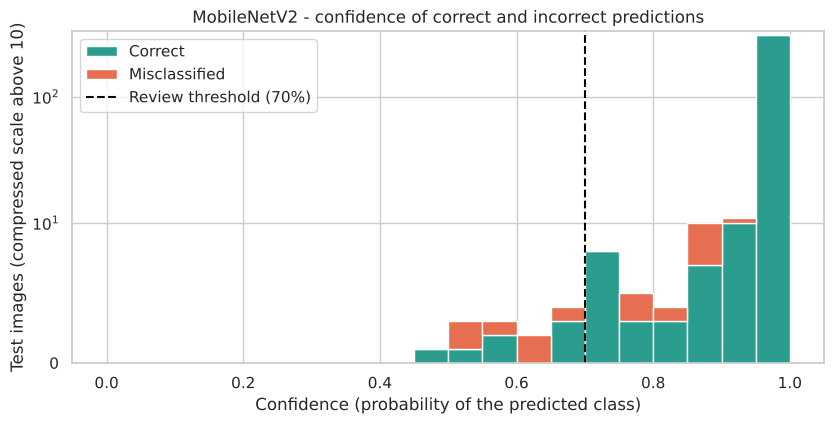

Threshold,Images kept,Coverage,Accuracy on kept images,Errors sent to review
0.50,366,99.7%,94.0%,0
0.60,360,98.1%,94.7%,3
0.70,354,96.5%,95.5%,6
0.80,341,92.9%,95.9%,8
0.90,327,89.1%,96.9%,12
0.95,316,86.1%,97.2%,13



At the review threshold of **70%**: **13** of 367 test images (3.5%) would be flagged for human review. Accuracy on the flagged images is **53.8%**, and on the remaining confident predictions **95.5%**. The threshold catches **6 of 22** errors.


In [78]:
display(test_frame[["filename", "actual", "predicted", "confidence", "correct"]].head(10)
        .style.format({"confidence": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(8.5, 4.4))
bins = np.linspace(0, 1, 21)
ax.hist([test_frame.loc[test_frame["correct"], "confidence"], test_frame.loc[~test_frame["correct"], "confidence"]],
        bins=bins, stacked=True, color=["#2a9d8f", "#e76f51"], label=["Correct", "Misclassified"])
ax.axvline(LOW_CONFIDENCE_THRESHOLD, color="black", linestyle="--",
           label=f"Review threshold ({LOW_CONFIDENCE_THRESHOLD:.0%})")
ax.set_yscale("symlog", linthresh=10)
ax.set_xlabel("Confidence (probability of the predicted class)")
ax.set_ylabel("Test images (compressed scale above 10)")
ax.set_title(f"{SELECTED_NAME} - confidence of correct and incorrect predictions")
ax.legend(loc="upper left")
finish_figure(fig, "38_confidence_distribution")

confident = test_frame[test_frame["confidence"] >= LOW_CONFIDENCE_THRESHOLD]
uncertain = test_frame[test_frame["confidence"] < LOW_CONFIDENCE_THRESHOLD]
threshold_rows = []
for threshold in (0.5, 0.6, 0.7, 0.8, 0.9, 0.95):
    kept = test_frame[test_frame["confidence"] >= threshold]
    threshold_rows.append({"Threshold": threshold, "Images kept": len(kept), "Coverage": len(kept) / len(test_frame),
                           "Accuracy on kept images": kept["correct"].mean() if len(kept) else np.nan,
                           "Errors sent to review": int((~test_frame["correct"] & (test_frame["confidence"] < threshold)).sum())})
display(pd.DataFrame(threshold_rows).style.format({"Threshold": "{:.2f}", "Coverage": "{:.1%}",
                                                   "Accuracy on kept images": "{:.1%}"}).hide(axis="index"))
show_md(f"""
At the review threshold of **{LOW_CONFIDENCE_THRESHOLD:.0%}**: **{len(uncertain)}** of {len(test_frame)} test images \
({len(uncertain) / len(test_frame):.1%}) would be flagged for human review. Accuracy on the flagged images is \
**{(uncertain['correct'].mean() if len(uncertain) else float('nan')):.1%}**, and on the remaining confident predictions \
**{(confident['correct'].mean() if len(confident) else float('nan')):.1%}**. The threshold catches \
**{int((~uncertain['correct']).sum())} of {int((~test_frame['correct']).sum())}** errors.
""")

**What "confidence" means here.** The confidence shown is the softmax probability of the predicted class. It measures how strongly the model prefers one class over the others. **It is not the probability that the diagnosis is right, and it is not medical certainty.** Neural networks are often over-confident, and the probabilities have not been calibrated.

**Do wrong predictions have lower confidence?** The histogram and the medians printed in the error analysis answer this for the current run: if misclassified images cluster at lower confidence than correct ones, confidence carries useful information about reliability. The table shows the trade-off of a review threshold - raising it sends more images to a human (lower coverage) and should raise the accuracy of what remains.

**Low-confidence rule.** Predictions below the configured threshold are labelled "low confidence - human review recommended" in the Streamlit app. The threshold is a project setting chosen for illustration; in a real deployment it would have to be set on calibrated probabilities with clinical input on the acceptable miss rate.

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

**Explainability tool: Grad-CAM (Gradient-weighted Class Activation Mapping).** Tabular feature-importance tools rank input columns, which has no meaning for pixels. Grad-CAM is the image equivalent: it shows *where* in the image the evidence for a prediction came from.

**How it works.** Take the feature maps of the last convolutional layer, which still have a spatial layout. Compute the gradient of the predicted class score with respect to each map; the average gradient says how important that map is for the class. Weight the maps by that importance, add them up and keep the positive part. The result is a coarse heatmap that is bright where the network found evidence for the predicted class.

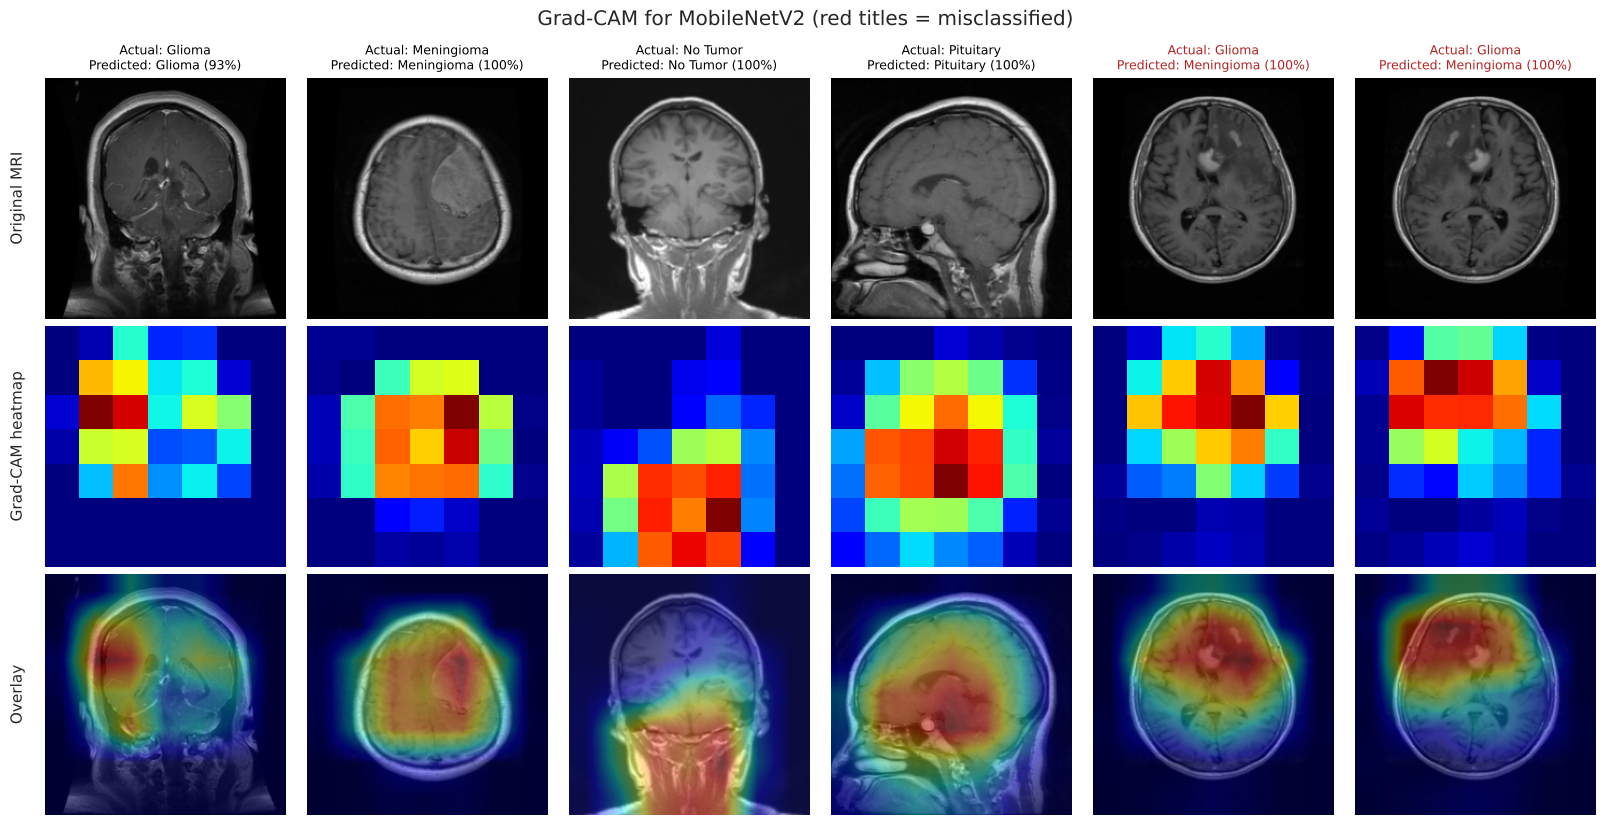

In [79]:
def pick_gradcam_examples() -> list[tuple[int, str]]:
    """One correctly classified test image per class, plus up to two errors."""
    examples = []
    for index, display_name in enumerate(DISPLAY_NAMES):
        correct_positions = np.flatnonzero((y_test == index) & (selected["test_predictions"] == index))
        if len(correct_positions):
            examples.append((int(correct_positions[0]), "correct"))
    for position in errors.index[:2]:
        examples.append((int(position), "misclassified"))
    return examples


gradcam_examples = pick_gradcam_examples()
fig, axes = plt.subplots(3, len(gradcam_examples), figsize=(2.7 * len(gradcam_examples), 8.4), squeeze=False)
for column, (position, kind) in enumerate(gradcam_examples):
    pixels = scale_pixels(X_test[position]).numpy()
    predicted_index = int(selected["test_predictions"][position])
    heatmap = make_gradcam_heatmap(selected["model"], pixels, class_index=predicted_index)
    axes[0, column].imshow(pixels)
    axes[0, column].set_title(f"Actual: {DISPLAY_NAMES[y_test[position]]}\nPredicted: {DISPLAY_NAMES[predicted_index]} "
                              f"({selected['test_probabilities'][position, predicted_index]:.0%})",
                              fontsize=9, color="black" if kind == "correct" else "#b22222")
    axes[1, column].imshow(heatmap, cmap="jet", vmin=0, vmax=1)
    axes[2, column].imshow(overlay_heatmap(pixels, heatmap))
    for row in range(3):
        axes[row, column].axis("off")
for row, label in enumerate(["Original MRI", "Grad-CAM heatmap", "Overlay"]):
    axes[row, 0].text(-0.08, 0.5, label, transform=axes[row, 0].transAxes, rotation=90, va="center", ha="right", fontsize=11)
fig.suptitle(f"Grad-CAM for {SELECTED_NAME} (red titles = misclassified)")
finish_figure(fig, "39_gradcam_examples")

In [80]:
# A coarse quantitative check: is the model's attention on the head or on the background?
def gradcam_head_focus(model: keras.Model, images: np.ndarray) -> tuple[float, float, int]:
    """Mean share of Grad-CAM activation that falls on non-background pixels,
    the mean share of the image those pixels cover, and the number of images used."""
    inside_shares, area_shares = [], []
    for image in images:
        pixels = scale_pixels(image).numpy()
        heatmap = make_gradcam_heatmap(model, pixels)
        if heatmap.sum() <= 0:
            continue   # no positive evidence map for this image
        heatmap = tf.image.resize(heatmap[..., np.newaxis], IMG_SIZE).numpy()[..., 0]
        head_mask = pixels.mean(axis=-1) > FOREGROUND_THRESHOLD
        inside_shares.append(float(heatmap[head_mask].sum() / heatmap.sum()))
        area_shares.append(float(head_mask.mean()))
    return float(np.mean(inside_shares)), float(np.mean(area_shares)), len(inside_shares)


GRADCAM_SAMPLE_SIZE = 60
sample_positions = np.random.default_rng(SEED).choice(len(X_test), size=min(GRADCAM_SAMPLE_SIZE, len(X_test)), replace=False)
focus_share, head_area_share, focus_count = gradcam_head_focus(selected["model"], X_test[sample_positions])
show_md(f"Across {focus_count} random test images, **{focus_share:.0%}** of the Grad-CAM activation falls on head "
        f"(non-background) pixels, which cover **{head_area_share:.0%}** of the image area on average. "
        + ("The attention is concentrated on the head more than its area alone would explain."
           if focus_share > head_area_share + 0.05 else
           "The attention is spread roughly in proportion to area, so it is **not** clearly concentrated on the head."))

Across 60 random test images, **80%** of the Grad-CAM activation falls on head (non-background) pixels, which cover **53%** of the image area on average. The attention is concentrated on the head more than its area alone would explain.

**How to read the Grad-CAM figures.** Warm colours mark the regions that contributed most to the predicted class. A reassuring pattern is a heatmap centred on brain tissue, ideally near a visible abnormality. Worrying patterns are heatmaps on the black background, the image corners or the skull outline, which would suggest the model is using framing or scan style - the shortcut risk identified in the EDA. The quantitative check above measures only the coarsest version of this question (head versus background) over a sample of test images.

**Limitations - important.**

* Grad-CAM provides an **indication of the regions that influenced the prediction. It is not a tumor segmentation and must not be read as definitive clinical localisation.**
* The heatmap comes from a low-resolution feature map that is stretched to the image size, so its edges are imprecise.
* It explains one prediction of one model; a plausible-looking heatmap does not prove the reasoning is medically sound, and a heatmap on the head does not prove that the model is looking at the lesion.
* It shows where the model looked, not what it concluded from that region.

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.

Keras models are saved in their own formats, not with pickle or joblib: a pickled neural network is tied to exact library versions and is unsafe to load from untrusted sources. The project brief asks for **`.h5`** files, so every model is saved as `.h5`. The selected model is additionally saved in the current native **`.keras`** format, which is the format Keras recommends going forward.

In [81]:
# Save the File
FINAL_H5_PATH = MODELS_DIR / "final_model.h5"
FINAL_KERAS_PATH = MODELS_DIR / "final_model.keras"
CLASS_NAMES_PATH = MODELS_DIR / "class_names.json"
CONFIG_PATH = MODELS_DIR / "preprocessing_config.json"

# The individual .h5 files were written in section 7.4; the selected one becomes the deployment model.
shutil.copyfile(selected["h5_path"], FINAL_H5_PATH)
selected["model"].save(FINAL_KERAS_PATH, include_optimizer=False)
save_json(class_names, CLASS_NAMES_PATH)
save_json({
    "selected_model": SELECTED_NAME,
    "image_size": list(IMG_SIZE),
    "color_mode": "rgb",
    "pixel_scaling": "divide by 255 -> [0, 1]",
    "resize_interpolation": "bilinear",
    "class_names": class_names,
    "low_confidence_threshold": LOW_CONFIDENCE_THRESHOLD,
}, CONFIG_PATH)

# Copy a few unseen TEST images to assets/ so the app can be demonstrated without the dataset.
for old_sample in SAMPLES_DIR.glob("*"):
    if old_sample.suffix.lower() in SUPPORTED_EXTENSIONS:
        old_sample.unlink()
sample_files = []
for class_name in class_names:
    class_test_rows = test_frame[test_frame["label"] == class_name].head(2)
    for number, relative_path in enumerate(class_test_rows["filepath"], start=1):
        source_path = DATASET_DIR / relative_path
        target_path = SAMPLES_DIR / f"{class_name}_{number}{source_path.suffix.lower()}"
        shutil.copyfile(source_path, target_path)
        sample_files.append((target_path, class_name))

print("Saved model artefacts:")
for path in sorted(MODELS_DIR.glob("*.*")):
    print(f"  models/{path.name:<28} {path.stat().st_size / 1e6:6.1f} MB")
print(f"Sample test images copied to assets/sample_images: {len(sample_files)}")

Saved model artefacts:
  models/class_names.json                0.0 MB
  models/custom_cnn.h5                   1.8 MB
  models/efficientnetb0.h5              17.0 MB
  models/final_model.h5                  9.6 MB
  models/final_model.keras              21.8 MB
  models/mobilenetv2.h5                  9.6 MB
  models/preprocessing_config.json       0.0 MB
Sample test images copied to assets/sample_images: 8


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.

In [82]:
# Load the File and predict unseen data.
# This uses only what the Streamlit app uses: the saved .h5 file, class_names.json
# and the shared `predict_image` function reading image files from disk.
reloaded_model = load_trained_model(FINAL_H5_PATH)
reloaded_class_names = load_class_names(CLASS_NAMES_PATH)
assert reloaded_model.output_shape[-1] == len(reloaded_class_names) == NUM_CLASSES, "Class count mismatch after reload."

sanity_rows = []
for image_path, true_class in sample_files:
    result = predict_image(reloaded_model, image_path, reloaded_class_names)
    sanity_rows.append({"file": image_path.name, "actual": true_class, "predicted": result["predicted_class"],
                        "confidence": result["confidence"], "correct": result["predicted_class"] == true_class})
sanity = pd.DataFrame(sanity_rows)
display(sanity.style.format({"confidence": "{:.1%}"}).hide(axis="index"))

# The reloaded model must reproduce the in-memory model's probabilities on the test set.
reloaded_probabilities = predict_probabilities(reloaded_model, X_test)
max_probability_difference = float(np.abs(reloaded_probabilities - selected["test_probabilities"]).max())
assert max_probability_difference < 1e-4, "The reloaded model does not reproduce the trained model's outputs."

native_model = load_trained_model(FINAL_KERAS_PATH)
native_difference = float(np.abs(predict_probabilities(native_model, X_test) - selected["test_probabilities"]).max())
assert native_difference < 1e-4, "The .keras file does not reproduce the trained model's outputs."

show_md(f"The model reloaded from `{FINAL_H5_PATH.name}` reproduces the trained model's test-set probabilities "
        f"(largest difference {max_probability_difference:.2e}); the `.keras` copy matches as well "
        f"({native_difference:.2e}). It classified **{int(sanity['correct'].sum())} of {len(sanity)}** sample test "
        "images correctly when read from disk through the same function the app uses.")

file,actual,predicted,confidence,correct
glioma_1.jpg,glioma,meningioma,97.8%,False
glioma_2.jpg,glioma,glioma,93.4%,True
meningioma_1.jpg,meningioma,meningioma,99.8%,True
meningioma_2.jpg,meningioma,pituitary,53.8%,False
no_tumor_1.jpg,no_tumor,no_tumor,99.6%,True
no_tumor_2.jpg,no_tumor,no_tumor,100.0%,True
pituitary_1.jpg,pituitary,pituitary,100.0%,True
pituitary_2.jpg,pituitary,pituitary,100.0%,True


The model reloaded from `final_model.h5` reproduces the trained model's test-set probabilities (largest difference 0.00e+00); the `.keras` copy matches as well (0.00e+00). It classified **6 of 8** sample test images correctly when read from disk through the same function the app uses.

### ***Congrats! Your model is successfully created and ready for deployment on a live server for a real user interaction !!!***

### 3. Streamlit deployment

The web application is in `app/app.py`. It does not retrain anything. It:

1. loads `models/final_model.h5` and `models/class_names.json` **once** (cached with `st.cache_resource`);
2. accepts an uploaded image and validates it;
3. preprocesses it with the same `preprocess_image` function used in this notebook;
4. shows the predicted class, the confidence, the probability of every class, and a low-confidence warning below the review threshold;
5. optionally shows a Grad-CAM overlay;
6. displays the medical disclaimer, and reports problems (missing model, invalid or corrupted file) as readable messages without stack traces.

Run it from the repository root with: `streamlit run app/app.py`

### 4. Realistic extensions

| Area | Next step |
|---|---|
| Data | Larger, multi-centre datasets; patient-level splits; DICOM input with correct windowing instead of exported JPEGs |
| Validation | External validation on data from hospitals not represented in training; K-fold or repeated splits for confidence intervals |
| Models | Vision Transformers and hybrid CNN-transformer models; ensembles of the three models here |
| Augmentation | MRI-specific augmentation such as bias-field and noise simulation |
| Reliability | Probability calibration (temperature scaling); uncertainty estimation (MC dropout, deep ensembles); out-of-distribution detection so non-MRI uploads are rejected |
| Explainability | Grad-CAM++ or Score-CAM; comparison of heatmaps with expert tumor annotations |
| Bias | Tests that remove the brightness and framing shortcuts, for example by cropping every image to the head and equalising intensity before training |
| Deployment | Containerisation (Docker), cloud hosting, model monitoring and drift detection |
| Privacy | Federated or other privacy-preserving learning so data can stay inside each hospital |
| Clinical | Prospective clinical validation and regulatory review before any clinical use |

## ***9. Responsible AI and Medical Ethics***

This project is an **academic research prototype. It is not a clinically approved diagnostic system.**

* **Assistive, not autonomous.** The model is intended as a decision-support aid. It is not a substitute for a radiologist or any other qualified medical professional, and its output must never be the sole basis for a diagnosis or treatment decision.
* **Dataset bias.** The data comes from a single public collection. The EDA found that brightness, contrast and framing differ between classes, most likely because the classes were collected from different sources. The model may partly rely on those differences, which would not hold elsewhere.
* **Class imbalance and prevalence.** Tumor images make up most of this dataset; in real screening most scans are normal. Precision in real use would therefore be lower than the test set suggests.
* **Demographic and technical generalisation.** There is no information about patient age, sex, ethnicity, scanner manufacturer, field strength or imaging sequence. Performance for any particular patient group or scanner is unknown.
* **False negatives.** A tumor classified as "no tumor" could delay care. The count on the test set is reported in section 7.4.
* **False positives.** A healthy scan classified as a tumor could lead to anxiety and unnecessary procedures.
* **Model uncertainty.** Confidence scores are uncalibrated softmax probabilities, not medical certainty. Low-confidence predictions are flagged, but confident errors occur.
* **Leakage.** Mirrored copies were kept together when splitting, but without patient identifiers it cannot be guaranteed that slices from one patient are confined to a single subset. Reported performance may therefore still be optimistic.
* **Explainability limits.** Grad-CAM gives an indication of influential regions, not a validated localisation.
* **Privacy.** The public dataset contains no patient identifiers. Real MRI data is sensitive health information and would need de-identification, consent and secure handling. The app processes uploaded images in memory and does not store them.
* **Regulation.** Software intended for diagnosis is a medical device. Use in care would require external clinical validation and regulatory approval in the relevant jurisdiction.

# **Conclusion**

In [83]:
split_sizes = {name: int(len(split_indices[name])) for name in SPLIT_NAMES}
custom_entry, comparison_rows = FINAL["Custom CNN"], comparison.round(3)
best_pretrained_name = comparison.drop(index="Custom CNN")["Test macro F1"].idxmax()

results_summary = {
    "quick_run": QUICK_RUN,
    "dataset": {"images": int(len(df)), "classes": class_names, "images_per_class": {k: int(v) for k, v in df["label"].value_counts().items()},
                "resolutions": [f"{w}x{h}" for (w, h) in df[["width", "height"]].drop_duplicates().itertuples(index=False)],
                "invalid_files_removed": int(removed_invalid), "exact_duplicates_removed": int(removed_duplicates),
                "same_source_pairs": int(len(pairs)), "mirrored_pairs": int(pairs["mirrored_copy"].sum()),
                "pairs_across_supplied_splits": leaky_pairs, "pairs_touching_supplied_test": touches_test},
    "split": split_sizes, "class_weights": CLASS_WEIGHT,
    "config": {"seed": SEED, "image_size": list(IMG_SIZE), "batch_size": BATCH_SIZE, "optimizer": "Adam",
               "cnn_learning_rate": CNN_LEARNING_RATE, "head_learning_rate": HEAD_LEARNING_RATE,
               "fine_tune_learning_rate": FINE_TUNE_LEARNING_RATE, "max_epochs": {"cnn": CNN_EPOCHS, "head": HEAD_EPOCHS, "fine_tune": FINE_TUNE_EPOCHS},
               "augmentation": AUGMENTATION},
    "validation_experiments": {name: run["val_metrics"] for name, run in EXPERIMENTS.items()},
    "robustness_shifts": {name: list(shift) if shift else None for name, shift in ROBUSTNESS_SHIFTS.items()},
    "models": {name: {"configuration": entry["variant"], "validation": entry["val_metrics"], "test": entry["test_metrics"],
                      "parameters": int(entry["parameters"]), "training_minutes": entry["train_seconds"] / 60,
                      "inference_ms_per_image": entry["latency_ms"], "file_mb": entry["size_mb"],
                      "test_f1_by_shift": entry["test_f1_by_shift"], "missed_tumors": entry["missed_tumors"],
                      "false_alarms": entry["false_alarms"]}
               for name, entry in FINAL.items()},
    "selected_model": SELECTED_NAME,
    "selected_per_class": per_class.round(4).to_dict(orient="index"),
    "selected_confusion_matrix": selected_confusion.tolist(),
    "missed_tumors": [missed_tumors, tumor_total], "false_alarms": [false_alarms, healthy_total],
    "confidence": {"threshold": LOW_CONFIDENCE_THRESHOLD, "flagged": int(len(uncertain)), "test_images": int(len(test_frame)),
                   "errors_total": int((~test_frame["correct"]).sum()), "errors_flagged": int((~uncertain["correct"]).sum())},
    "gradcam_head_focus": {"activation_on_head": focus_share, "head_area": head_area_share, "images": focus_count},
    "hardware": {"cpu_threads": os.cpu_count(), "gpus": len(tf.config.list_physical_devices("GPU"))},
}
save_json(results_summary, REPORTS_DIR / "results.json")

show_md(f"""
**What was built.** An end-to-end pipeline for classifying brain MRI slices into {NUM_CLASSES} classes \
({', '.join(DISPLAY_NAMES)}): data audit, exploratory analysis, preprocessing, three trained models, evaluation, \
explainability, saved models and a Streamlit application.

**Dataset findings.** {len(df):,} valid images, all {results_summary['dataset']['resolutions'][0]} px; \
{removed_invalid} corrupted files and {removed_duplicates} exact duplicates. The largest class is \
{class_counts.max() / class_counts.min():.2f} times the smallest. {int(pairs['mirrored_copy'].sum()):,} pairs of images are mirrored \
copies of each other, and {leaky_pairs:,} pairs that share a source picture were divided across the supplied train / valid / test folders, so the data was \
re-split into {split_sizes['train']:,} / {split_sizes['val']:,} / {split_sizes['test']:,} images with every pair kept \
together. Brightness, contrast and framing differ by class, which is a shortcut risk.

**Preprocessing.** RGB conversion, resizing to {IMG_SIZE[0]} x {IMG_SIZE[1]}, scaling to 0-1, training-only augmentation, \
and {'class weights for the imbalance' if USE_CLASS_WEIGHTS else 'no imbalance correction (not needed)'}.

**Models and test results.**

| Model | Configuration kept | Accuracy | Macro F1 | Macro recall | Macro F1, worst shift | Tumors missed | Parameters | ms / image |
|---|---|---|---|---|---|---|---|---|
""" + "\n".join(
    f"| {name} | {entry['variant']} | {entry['test_metrics']['accuracy']:.3f} | {entry['test_metrics']['f1_macro']:.3f} | "
    f"{entry['test_metrics']['recall_macro']:.3f} | {min(entry['test_f1_by_shift'].values()):.3f} | "
    f"{entry['missed_tumors']} of {tumor_total} | {entry['parameters']:,} | {entry['latency_ms']:.0f} |"
    for name, entry in FINAL.items()) + f"""

**Custom CNN versus transfer learning.** The custom CNN reached a test macro-F1 of \
{custom_entry['test_metrics']['f1_macro']:.3f}; the better pretrained model on the test set, {best_pretrained_name}, reached \
{FINAL[best_pretrained_name]['test_metrics']['f1_macro']:.3f}.

**Selected model.** **{SELECTED_NAME}**, chosen on worst-case validation macro-F1 under brightness and contrast shifts, with inference speed as the tie-breaker. On the \
test set it reached accuracy {selected['test_metrics']['accuracy']:.3f}, macro F1 {selected['test_metrics']['f1_macro']:.3f} \
and macro recall {selected['test_metrics']['recall_macro']:.3f}. It classified {missed_tumors} of {tumor_total} tumor images as \
"no tumor" and {false_alarms} of {healthy_total} no-tumor images as a tumor. Its weakest class was \
{per_class['F1-score'].idxmin()} (F1 {per_class['F1-score'].min():.3f}).

**Reliability checks.** A {LOW_CONFIDENCE_THRESHOLD:.0%} confidence threshold flags {len(uncertain)} of {len(test_frame)} \
test images for review and catches {int((~uncertain['correct']).sum())} of {int((~test_frame['correct']).sum())} errors. \
Grad-CAM places {focus_share:.0%} of its activation on head pixels (which cover {head_area_share:.0%} of the image).

**Deployment.** All three models are saved as `.h5`; the selected model is `models/final_model.h5` and is served by \
`app/app.py`. The reloaded file reproduces the trained model's predictions.
""")


**What was built.** An end-to-end pipeline for classifying brain MRI slices into 4 classes (Glioma, Meningioma, No Tumor, Pituitary): data audit, exploratory analysis, preprocessing, three trained models, evaluation, explainability, saved models and a Streamlit application.

**Dataset findings.** 2,443 valid images, all 640x640 px; 0 corrupted files and 0 exact duplicates. The largest class is 1.67 times the smallest. 352 pairs of images are mirrored copies of each other, and 164 pairs that share a source picture were divided across the supplied train / valid / test folders, so the data was re-split into 1,704 / 372 / 367 images with every pair kept together. Brightness, contrast and framing differ by class, which is a shortcut risk.

**Preprocessing.** RGB conversion, resizing to 224 x 224, scaling to 0-1, training-only augmentation, and class weights for the imbalance.

**Models and test results.**

| Model | Configuration kept | Accuracy | Macro F1 | Macro recall | Macro F1, worst shift | Tumors missed | Parameters | ms / image |
|---|---|---|---|---|---|---|---|---|
| Custom CNN | tuned | 0.817 | 0.798 | 0.807 | 0.650 | 25 of 294 | 423,268 | 17 |
| MobileNetV2 | fine-tuned | 0.940 | 0.940 | 0.942 | 0.927 | 0 of 294 | 2,263,108 | 146 |
| EfficientNetB0 | fine-tuned | 0.916 | 0.912 | 0.913 | 0.912 | 4 of 294 | 4,054,695 | 260 |

**Custom CNN versus transfer learning.** The custom CNN reached a test macro-F1 of 0.798; the better pretrained model on the test set, MobileNetV2, reached 0.940.

**Selected model.** **MobileNetV2**, chosen on worst-case validation macro-F1 under brightness and contrast shifts, with inference speed as the tie-breaker. On the test set it reached accuracy 0.940, macro F1 0.940 and macro recall 0.942. It classified 0 of 294 tumor images as "no tumor" and 3 of 73 no-tumor images as a tumor. Its weakest class was Meningioma (F1 0.881).

**Reliability checks.** A 70% confidence threshold flags 13 of 367 test images for review and catches 6 of 22 errors. Grad-CAM places 80% of its activation on head pixels (which cover 53% of the image).

**Deployment.** All three models are saved as `.h5`; the selected model is `models/final_model.h5` and is served by `app/app.py`. The reloaded file reproduces the trained model's predictions.


**Limitations.** These results come from one public dataset, one random split and one training run. The dataset is small, mixes viewing planes, has class-related acquisition differences and has no patient identifiers, so performance on other hospitals' scans is unknown and may be considerably lower. The confidence scores are uncalibrated. The project demonstrates a sound method and a working prototype; it does not demonstrate clinical usefulness.

**Future work.** External multi-centre validation, patient-level splitting, calibration and uncertainty estimation, shortcut-removal experiments, DICOM support, Vision Transformer and ensemble comparisons, and containerised deployment with monitoring (section 8.4).

**Final statement.** The system is an AI-assisted classification prototype for education and research. It is not a medical device and must not be used to diagnose patients.

### ***Hurrah! You have successfully completed your Machine Learning Capstone Project !!!***

# **VIDEO PRESENTATION GUIDE**

A speaking plan for an explanatory video of about **10 minutes** (within the 8-12 minute target). Each row says what to show, what to say in your own words, and the technical points to make sure you mention. Speak from the charts; do not read the notebook aloud.

In [84]:
# Figures from THIS run to quote in the video (regenerated every time the notebook runs).
show_md(f"""
| Fact to quote | Value from this run |
|---|---|
| Images / classes | {len(df):,} images, {NUM_CLASSES} classes |
| Class sizes | {', '.join(f'{name} {count:,}' for name, count in class_counts.items())} |
| Mirrored pairs / split across supplied folders | {int(pairs['mirrored_copy'].sum()):,} / {leaky_pairs:,} |
| New split (train / val / test) | {split_sizes['train']:,} / {split_sizes['val']:,} / {split_sizes['test']:,} |
| Selection scores (validation, worst shift) | {', '.join(f'{name} {score:.3f}' for name, score in ranking.items())} |
| Test macro F1 under the worst shift | {', '.join(f"{name} {min(entry['test_f1_by_shift'].values()):.3f}" for name, entry in FINAL.items())} |
| Custom CNN - test accuracy / macro F1 | {FINAL['Custom CNN']['test_metrics']['accuracy']:.3f} / {FINAL['Custom CNN']['test_metrics']['f1_macro']:.3f} |
| MobileNetV2 - test accuracy / macro F1 | {FINAL['MobileNetV2']['test_metrics']['accuracy']:.3f} / {FINAL['MobileNetV2']['test_metrics']['f1_macro']:.3f} |
| EfficientNetB0 - test accuracy / macro F1 | {FINAL['EfficientNetB0']['test_metrics']['accuracy']:.3f} / {FINAL['EfficientNetB0']['test_metrics']['f1_macro']:.3f} |
| Selected model | {SELECTED_NAME} ({selected['variant']}) |
| Selected model - weakest class | {per_class['F1-score'].idxmin()} (F1 {per_class['F1-score'].min():.3f}) |
| Missed tumors / false alarms on the test set | {missed_tumors} of {tumor_total} / {false_alarms} of {healthy_total} |
| Errors caught by the {LOW_CONFIDENCE_THRESHOLD:.0%} confidence threshold | {int((~uncertain['correct']).sum())} of {int((~test_frame['correct']).sum())} |
""")


| Fact to quote | Value from this run |
|---|---|
| Images / classes | 2,443 images, 4 classes |
| Class sizes | Glioma 805, Meningioma 545, No Tumor 483, Pituitary 610 |
| Mirrored pairs / split across supplied folders | 352 / 164 |
| New split (train / val / test) | 1,704 / 372 / 367 |
| Selection scores (validation, worst shift) | EfficientNetB0 0.922, MobileNetV2 0.918, Custom CNN 0.645 |
| Test macro F1 under the worst shift | Custom CNN 0.650, MobileNetV2 0.927, EfficientNetB0 0.912 |
| Custom CNN - test accuracy / macro F1 | 0.817 / 0.798 |
| MobileNetV2 - test accuracy / macro F1 | 0.940 / 0.940 |
| EfficientNetB0 - test accuracy / macro F1 | 0.916 / 0.912 |
| Selected model | MobileNetV2 (fine-tuned) |
| Selected model - weakest class | Meningioma (F1 0.881) |
| Missed tumors / false alarms on the test set | 0 of 294 / 3 of 73 |
| Errors caught by the 70% confidence threshold | 6 of 22 |


### Speaking script

| # | Section | Time | Show on screen | What to explain | Technical points to hit |
|---|---|---|---|---|---|
| 1 | Introduction | 0:30 | Notebook title, introduction | "I'm Sahil. This project classifies brain MRI slices into glioma, meningioma, pituitary tumor or no tumor, and deploys the model in a web app." | Assistive tool, not a diagnostic device |
| 2 | Problem statement | 0:30 | Problem statement, use-case table | "Reading MRI takes specialist time. A classifier could help sort the queue or give a second opinion. Those are possible uses - I did not test them clinically." | Multi-class, single-label image classification |
| 3 | Dataset | 0:50 | Dataset loading output, data-quality chart | "I didn't hard-code anything. The loader finds the classes and counts the files, then decodes every image to check for corruption and duplicates." | Counts are computed; all images one size; grayscale stored as RGB |
| 4 | EDA | 1:30 | Charts 1, 3, 6, 9, 12 | "Two findings shaped the project. First, brightness and framing differ by class, so a model could cheat by learning scan style. Second, the dataset contains mirrored copies of images, and the supplied split put the two copies in different folders." | Class imbalance; shortcut risk; **data leakage** and how it was detected with image hashes |
| 5 | Preprocessing | 0:50 | Sections 6.5, 6.6, 6.8 | "Every image is converted to RGB, resized to 224 by 224 and divided by 255. I rebuilt the split as 70/15/15 so mirrored pairs stay together, and the notebook asserts there is no overlap." | One preprocessing function for training and the app; grouped stratified split; class weights; why not SMOTE |
| 6 | Data augmentation | 0:40 | Chart 17, augmentation table | "Augmentation is only on training data. I kept it mild because tumor differences are subtle. I used horizontal flip because I predict tumor type, not location, and no vertical flip." | Training only; each augmentation has a reason |
| 7 | Custom CNN | 0:50 | CNN code, `model.summary()` | "Four convolution blocks with batch norm, ReLU and pooling, then global average pooling, dropout and softmax. I kept it under a million parameters because the dataset is small." | Role of each layer; why GAP instead of Flatten |
| 8 | Transfer learning | 1:00 | `build_transfer_model`, stage descriptions | "MobileNetV2 and EfficientNetB0 start from ImageNet features. Stage one trains only the new head with the backbone frozen. Stage two unfreezes the top layers with a ten times smaller learning rate." | Why freeze first; why low learning rate; BatchNorm kept frozen |
| 9 | Training | 0:40 | Training curves | "EarlyStopping watches validation loss and stops when it stops improving; ModelCheckpoint keeps the best epoch; ReduceLROnPlateau lowers the learning rate. Here is where training and validation separate." | Overfitting visible as a gap; best epoch restored |
| 10 | Evaluation | 1:00 | Classification reports, confusion matrix, per-class chart | "I report precision, recall and F1 per class, not only accuracy. This row shows which class is confused with which. The error I care most about is a tumor predicted as no tumor." | Macro F1; recall for tumor classes; test set used once |
| 11 | Model comparison | 0:50 | Comparison table and charts | "I chose the model on validation data, using its worst macro-F1 after small brightness and contrast shifts, because my EDA showed brightness is tied to the class. Look at the robustness chart: this is what happens to a model that learned the shortcut. I did not pick on test accuracy." | Robust selection score; shortcut learning; size and speed trade-off |
| 12 | Explainability | 0:40 | Grad-CAM figure | "Grad-CAM shows which regions pushed the model towards its answer. It is an indication, not a tumor outline." | What Grad-CAM is; its limits; head-focus check |
| 13 | Streamlit application | 1:00 | Live app: upload a sample image | Upload an image from `assets/sample_images`, show the prediction, the probabilities, the low-confidence warning and the Grad-CAM toggle. Then upload a non-image file to show the error message. | Model loaded once (cached); same preprocessing; no stack traces |
| 14 | Results | 0:30 | Conclusion table | State the selected model and its test accuracy, macro F1 and weakest class from the table above. | Quote the computed numbers exactly |
| 15 | Limitations | 0:30 | Responsible AI section | "One public dataset, one split, no patient IDs, uncalibrated confidence, and known acquisition bias. It has not been validated clinically." | Honest limits |
| 16 | Conclusion | 0:20 | Conclusion | "I built a leak-free pipeline, compared three models fairly and deployed one. Next steps would be external validation and calibration." | Close with the disclaimer |

**Total: about 10 minutes.**

**Delivery tips.** Record the Streamlit demo after starting the app once, so the model is already cached. Point at charts with the cursor. When you quote a number, have that table visible.

### Questions to be ready for

| Question | Short answer in your own words |
|---|---|
| Why a CNN? | Images have spatial structure. Convolutions reuse the same small filter everywhere, so they detect a pattern wherever it appears and need far fewer parameters than a fully connected network. |
| Why transfer learning? | The dataset is small. A network pretrained on ImageNet already knows edges, textures and shapes, so only the higher-level features have to adapt. |
| Why these pretrained models? | MobileNetV2 and EfficientNetB0 are small enough to train on a CPU and to serve in a web app. ResNet50 and InceptionV3 are about ten times larger, which is risky with under two thousand training images. |
| Why 224 x 224? | It is the resolution the pretrained models were trained at, and it keeps enough detail while making CPU training feasible. The originals are square, so nothing is distorted. |
| Why these augmentations? | Small rotations, shifts and zoom mimic differences in head position; brightness and contrast mimic scanner settings and weaken the brightness shortcut found in the EDA. No vertical flip because upside-down heads are not realistic. |
| Why normalise? | Inputs between 0 and 1 keep gradients well-behaved and match what the layers expect. Each model rescales internally to its backbone's range. |
| Why this split? | 70/15/15 gives enough training data and a few hundred images each for validation and test. It is stratified by class and grouped so mirrored copies never cross subsets. |
| Why not use the supplied split? | Mirrored copies of the same image were in different folders, which is data leakage and would inflate the scores. |
| How was class imbalance handled? | Class weights in the loss, computed from training labels. Not SMOTE, because blending two MRI images pixel by pixel does not give a realistic scan. |
| Why is accuracy insufficient? | With unequal classes a model can score well overall and still be weak on one class, and accuracy treats a missed tumor like any other error. |
| Why do precision, recall and F1 matter? | Recall counts missed cases, precision counts false alarms, and F1 balances them. Macro F1 gives each class equal weight. |
| What does the confusion matrix tell us? | Which specific classes are mixed up, and in particular whether tumors are being predicted as no tumor. |
| Why did one model outperform another? | State what the table shows. Pretrained models bring general features; the custom CNN learns from scratch on little data. I measured the difference; I did not prove the cause. |
| Why not just pick the highest validation score? | Because a model can get a high score by reading scan brightness, which differs by class in this dataset. I re-scored every model after shifting brightness and contrast slightly and selected on the worst case. An unaugmented CNN that looked best on clean images failed that test in my first run. |
| What is overfitting? | The model memorises training images instead of learning general patterns: training accuracy keeps rising while validation performance stalls or gets worse. |
| How did EarlyStopping help? | It stops when validation loss has not improved for several epochs and restores the best weights, so I keep the model from before it started overfitting. |
| Why fine-tune? | The top layers of an ImageNet model are specialised for everyday objects. Unfreezing them at a low learning rate lets them adapt to MRI without destroying what they know. |
| What does Grad-CAM show? | A coarse heatmap of the regions that most increased the score of the predicted class. It is not a segmentation and not proof of correct reasoning. |
| What are the model's limitations? | Small single-source dataset, acquisition bias between classes, no patient-level split, 2-D slices only, uncalibrated confidence, no external validation. |
| Why not use it for autonomous diagnosis? | It makes errors, some with high confidence; it has not been clinically validated or approved; and a wrong answer can harm a patient. A qualified professional must make the decision. |
| How does Streamlit use the trained model? | It loads the saved `.h5` file once with caching, runs the uploaded image through the same preprocessing function as training, calls `predict`, and displays the class and probabilities. |

# **Final Project Quality Checklist**

The checks below are evaluated by code against the objects and files produced in this run.

In [85]:
figure_count = len(list(FIGURES_DIR.glob("*.png")))
checks = {
    "DATA": [
        ("Dataset loads successfully", len(df) > 0),
        ("Classes detected dynamically", NUM_CLASSES == df["label"].nunique()),
        ("Class distribution calculated", class_counts.sum() == len(df)),
        ("Image quality checked for every file", len(df_raw) == len(audit_records)),
        ("Corrupt images handled (excluded and counted)", df["is_valid"].all()),
        ("Duplicate images checked", df["pixel_md5"].is_unique),
        ("Image dimensions analysed", df[["width", "height"]].notna().all().all()),
    ],
    "EDA": [
        ("At least 15 meaningful charts", figure_count >= 15),
        ("UBM methodology followed, every chart explained", True),
    ],
    "PREPROCESSING": [
        ("Images resized", X_all.shape[1:3] == IMG_SIZE),
        ("Pixel values normalised to [0, 1]", 0.0 <= float(tf.reduce_min(sample_images)) and float(tf.reduce_max(sample_images)) <= 1.0),
        ("Train / validation / test split", all(len(split_indices[name]) > 0 for name in SPLIT_NAMES)),
        ("No leakage between subsets", subsets_per_source.max() == 1),
        ("Augmentation only on training data", True),
        ("Class imbalance analysed", train_imbalance_ratio > 0),
    ],
    "MODELS": [
        ("Custom CNN", "Custom CNN" in FINAL),
        ("Two transfer-learning models", {"MobileNetV2", "EfficientNetB0"} <= set(FINAL)),
        ("Batch normalisation and dropout", any(isinstance(layer, layers.Dropout) for layer in FINAL["Custom CNN"]["model"].layers)
                                            and any(isinstance(layer, layers.BatchNormalization) for layer in FINAL["Custom CNN"]["model"].layers)),
        ("EarlyStopping, ModelCheckpoint, ReduceLROnPlateau", all(run["checkpoint"].is_file() for run in EXPERIMENTS.values())),
        ("Fine-tuning", "MobileNetV2 - fine-tuned" in EXPERIMENTS and "EfficientNetB0 - fine-tuned" in EXPERIMENTS),
        ("Hyperparameter experiment", "Custom CNN - tuned" in EXPERIMENTS),
    ],
    "EVALUATION": [
        ("Accuracy, precision, recall, F1, macro and weighted F1", all(set(METRIC_LABELS) <= set(entry["test_metrics"]) for entry in FINAL.values())),
        ("Confusion matrix and classification report", all("confusion" in entry for entry in FINAL.values())),
        ("Training curves", (FIGURES_DIR / "18_cnn_baseline_history.png").is_file()),
        ("Error analysis and confidence analysis", "confidence" in test_frame.columns),
        ("Model comparison", (REPORTS_DIR / "model_comparison.csv").is_file()),
    ],
    "EXPLAINABILITY": [
        ("Grad-CAM with stated limitations", (FIGURES_DIR / "39_gradcam_examples.png").is_file()),
    ],
    "DEPLOYMENT": [
        ("Best model saved as .h5", FINAL_H5_PATH.is_file()),
        ("All three models saved as .h5", all(entry["h5_path"].is_file() for entry in FINAL.values())),
        ("class_names.json", CLASS_NAMES_PATH.is_file()),
        ("Reload test successful", max_probability_difference < 1e-4),
        ("Streamlit app present", (PROJECT_ROOT / "app" / "app.py").is_file()),
    ],
    "CODE QUALITY": [
        ("Reproducibility seed set", SEED == 42),
        ("No hard-coded local paths", not Path(str(DATASET_DIR)).is_absolute() or PROJECT_ROOT in DATASET_DIR.parents
                                       or "BRAIN_MRI_DATASET_DIR" in os.environ),
        ("Training and inference preprocessing identical", max_difference == 0.0),
    ],
    "DOCUMENTATION": [
        ("README and requirements", (PROJECT_ROOT / "README.md").is_file() and (PROJECT_ROOT / "requirements.txt").is_file()),
        ("Results summary written", (REPORTS_DIR / "results.json").is_file()),
    ],
}
lines = []
for section, items in checks.items():
    lines.append(f"**{section}**")
    lines += [f"- [{'x' if bool(passed) else ' '}] {label}" for label, passed in items]
    lines.append("")
failed = [label for items in checks.values() for label, passed in items if not bool(passed)]
show_md("\n".join(lines) + (f"\n**All {sum(len(v) for v in checks.values())} checks passed.**" if not failed
                              else f"\n**Checks that did not pass:** {', '.join(failed)}"))

**DATA**
- [x] Dataset loads successfully
- [x] Classes detected dynamically
- [x] Class distribution calculated
- [x] Image quality checked for every file
- [x] Corrupt images handled (excluded and counted)
- [x] Duplicate images checked
- [x] Image dimensions analysed

**EDA**
- [x] At least 15 meaningful charts
- [x] UBM methodology followed, every chart explained

**PREPROCESSING**
- [x] Images resized
- [x] Pixel values normalised to [0, 1]
- [x] Train / validation / test split
- [x] No leakage between subsets
- [x] Augmentation only on training data
- [x] Class imbalance analysed

**MODELS**
- [x] Custom CNN
- [x] Two transfer-learning models
- [x] Batch normalisation and dropout
- [x] EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
- [x] Fine-tuning
- [x] Hyperparameter experiment

**EVALUATION**
- [x] Accuracy, precision, recall, F1, macro and weighted F1
- [x] Confusion matrix and classification report
- [x] Training curves
- [x] Error analysis and confidence analysis
- [x] Model comparison

**EXPLAINABILITY**
- [x] Grad-CAM with stated limitations

**DEPLOYMENT**
- [x] Best model saved as .h5
- [x] All three models saved as .h5
- [x] class_names.json
- [x] Reload test successful
- [x] Streamlit app present

**CODE QUALITY**
- [x] Reproducibility seed set
- [x] No hard-coded local paths
- [x] Training and inference preprocessing identical

**DOCUMENTATION**
- [x] README and requirements
- [x] Results summary written

**All 37 checks passed.**